In [ ]:
#cell1
import os
import math
from pathlib import Path
from datetime import date, timedelta
from zoneinfo import ZoneInfo

# ---- paths ---------------------------------------------------------------------
ROOT = Path(os.environ.get("UEBA_ROOT", os.getcwd())).expanduser().resolve()

def resolve_path(value):
    p = Path(value).expanduser()
    return (ROOT / p).resolve() if not p.is_absolute() else p.resolve()

EVENTS_PATH = resolve_path(
    os.environ.get("EVENTS_PATH", "events30days.jsonl")
)
GT_PATH = resolve_path(
    os.environ.get("GT_PATH", "GROUND_TRUTH30.md")
)
CACHE_DIR = resolve_path(os.environ.get("CACHE_DIR", "cache5"))
OUT_DIR = resolve_path(os.environ.get("OUT_DIR", "baseline_output5"))

if not EVENTS_PATH.is_file():
    raise FileNotFoundError(
        f"Event file not found: {EVENTS_PATH}\n"
        "Set EVENTS_PATH or UEBA_ROOT before running this cell."
    )
if EVENTS_PATH.stat().st_size == 0:
    raise ValueError(f"Event file is empty: {EVENTS_PATH}")

CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- time ----------------------------------------------------------------------
# Benchmark dates and 10-minute window keys remain UTC.
# Behavioral hour-of-day and weekday/weekend context are derived in IST later.
TZ = "UTC"                       # compatibility: benchmark/calendar timezone
SPLIT_TZ = "UTC"
BEHAVIOR_TZ = "Asia/Kolkata"
DAYTYPE_TZ = BEHAVIOR_TZ

for zone in (TZ, SPLIT_TZ, BEHAVIOR_TZ, DAYTYPE_TZ):
    ZoneInfo(zone)               # fail early if timezone data is unavailable

WINDOW = "10min"
WINDOW_MINUTES = 10
WINDOWS_PER_HOUR = 60 // WINDOW_MINUTES
WINDOWS_PER_DAY = 24 * WINDOWS_PER_HOUR

assert WINDOW_MINUTES > 0 and 60 % WINDOW_MINUTES == 0

def inclusive_dates(start, end):
    start, end = date.fromisoformat(start), date.fromisoformat(end)
    if end < start:
        raise ValueError("End date precedes start date.")
    return [
        (start + timedelta(days=i)).isoformat()
        for i in range((end - start).days + 1)
    ]

# Declared synthetic benchmark split; do not infer these from attack timestamps.
TRAIN_DATES = inclusive_dates("2026-07-28", "2026-08-03")
TEST_DATES = inclusive_dates("2026-08-04", "2026-08-26")
ALL_DATES = TRAIN_DATES + TEST_DATES

assert TRAIN_DATES and TEST_DATES
assert len(ALL_DATES) == len(set(ALL_DATES))
assert set(TRAIN_DATES).isdisjoint(TEST_DATES)
assert max(TRAIN_DATES) < min(TEST_DATES)
assert ALL_DATES == inclusive_dates(ALL_DATES[0], ALL_DATES[-1])

# ---- principal eligibility -----------------------------------------------------
# Necessary safeguards, not proof of sufficient behavioral history.
# Later baseline cells must enforce these, including within calibration folds.
MIN_TRAIN_EVENTS = 200
MIN_TRAIN_DAYS = 4
MIN_CELL_WINDOWS = 18
MIN_CELL_DAYS = 3

BS = chr(92)

# ---- scoring -------------------------------------------------------------------
MAD_NORMAL_FACTOR = 1.4826
MAD_FLOOR = 0.35
USER_SCALE_FACTOR = 0.60

# Proposed initial sensitivity settings; not optimized on test labels.
Z0, Z1 = 4.0, 12.0

K_STAT = 1.6
K_NOV = 3.2
K_RARE = 1.2
K_ACT = 2.5

W_STAT = 0.55
W_NOV = 0.88
W_RARE = 0.90
W_ACT = 0.80
W_ML = 0.12
W_TEMP = 0.10

TEMP_ALPHA = 4.0

# One source of truth for fusion, explanations, and ablation.
FULL_W = {
    "s_stat": W_STAT,
    "s_nov": W_NOV,
    "s_rare": W_RARE,
    "s_act": W_ACT,
    "s_ml": W_ML,
    "s_temp": W_TEMP,
}
SIGS = FULL_W.copy()

# Bands describe score magnitude, NOT the alert decision.
# Unsupported history will explicitly receive UNRATED later.
RISK_BANDS = [
    (0.25, "NORMAL"),
    (0.45, "LOW"),
    (0.60, "MEDIUM"),
    (0.80, "HIGH"),
    (float("inf"), "CRITICAL"),
]

FP_BUDGET_PER_USER_DAY = 0.20

# Final eligible-cell threshold must never fall below this floor.
# A floor can result in fewer alerts than the budget, which is acceptable.
GLOBAL_DEFAULT_THRESHOLD = 0.576
THRESHOLD_FLOOR = GLOBAL_DEFAULT_THRESHOLD

K_CELL, K_USER = 80.0, 300.0

# Neutral starting shape bounds, not claimed to be independently validated.
# Previously inspected scored-day results are development results.
SHAPE_LO, SHAPE_HI = 0.85, 1.40

# Fixed-baseline novelty: "unseen in training", not online first-ever occurrence.
NOVELTY_MODE = "fixed_baseline"

# Optional data-assisted label expansion; disabled for primary timeline evaluation.
BEACON_EXPANSION = False
DNS_HOST_OWNER = False

# First/last events establish an envelope, not verified sensor uptime.
# Later coverage cells must document their evidence or explicit assumption.
COVERAGE_POLICY = "require_explicit_coverage_or_documented_assumption"

RANDOM_STATE = 0

# ---- parameter validation ------------------------------------------------------
assert 0 <= Z0 < Z1
assert all(math.isfinite(k) and k > 0 for k in
           (K_STAT, K_NOV, K_RARE, K_ACT, TEMP_ALPHA, MAD_FLOOR))
assert all(math.isfinite(w) and 0 <= w <= 1 for w in FULL_W.values())
assert 0 < FP_BUDGET_PER_USER_DAY < WINDOWS_PER_DAY
assert 0 < THRESHOLD_FLOOR <= 1
assert 0 < SHAPE_LO <= 1 <= SHAPE_HI
assert K_CELL > 0 and K_USER > 0
assert MIN_CELL_DAYS <= MIN_TRAIN_DAYS <= len(TRAIN_DATES)

# ---- optional evaluation cell magic -------------------------------------------
from IPython import get_ipython

ip = get_ipython()
if ip is None:
    raise RuntimeError("Run these cells in a Jupyter/IPython notebook.")

HAS_GT = GT_PATH.is_file()

def requires_ground_truth(line, cell):
    # Recheck the file rather than relying on a stale HAS_GT value.
    if not GT_PATH.is_file():
        print(f"Skipped evaluation: ground-truth file not found at {GT_PATH}")
        return
    result = get_ipython().run_cell(cell)
    result.raise_error()

ip.register_magic_function(
    requires_ground_truth,
    magic_kind="cell",
    magic_name="requires_ground_truth",
)

print("Configuration loaded")
print(f"  events          : {EVENTS_PATH}")
print(f"  ground truth    : {GT_PATH} ({'found' if HAS_GT else 'optional / absent'})")
print(f"  benchmark split : {SPLIT_TZ}")
print(f"  behavior context: {BEHAVIOR_TZ}")
print(f"  window          : {WINDOW}; {WINDOWS_PER_DAY} windows/day")
print(f"  train           : {TRAIN_DATES[0]} -> {TRAIN_DATES[-1]}")
print(f"  test            : {TEST_DATES[0]} -> {TEST_DATES[-1]}")
print(f"  z ramp          : {Z0} -> {Z1}")
print(f"  threshold floor : {THRESHOLD_FLOOR}")

Configuration loaded
  events          : C:\Users\Aarya.DAS\Downloads\prompt\New folder\events30days.jsonl
  ground truth    : C:\Users\Aarya.DAS\Downloads\prompt\New folder\GROUND_TRUTH30.md (found)
  benchmark split : UTC
  behavior context: Asia/Kolkata
  window          : 10min; 144 windows/day
  train           : 2026-07-28 -> 2026-08-03
  test            : 2026-08-04 -> 2026-08-26
  z ramp          : 4.0 -> 12.0
  threshold floor : 0.576


In [ ]:
#cell2
import json
import re
import warnings
import textwrap
import hashlib
import tempfile
import ipaddress
import platform
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    roc_curve,
    f1_score,
    confusion_matrix,
)

try:
    import pyarrow as pa
    import pyarrow.parquet as pq
except ImportError as exc:
    raise ImportError(
        "pyarrow is required. Install it with %pip install pyarrow, "
        "then restart the kernel and run from Cell 1."
    ) from exc

# The loader below uses pandas >= 2 ISO8601 parsing.
if int(pd.__version__.split(".")[0]) < 2:
    raise RuntimeError(
        f"pandas >= 2 is required; installed version is {pd.__version__}."
    )

# Do NOT suppress all warnings: they can expose invalid operations and API changes.
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 70)

# ---- chart styling -------------------------------------------------------------
# Color alone is not the only way to identify categories; keep labels/legends.
CAT = [
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100",
    "#e87ba4", "#008300", "#4a3aa7", "#e34948",
]
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5",
       "#256abf", "#184f95", "#0d366b"]
STATUS = {
    "good": "#0ca30c",
    "warning": "#fab219",
    "serious": "#ec835a",
    "critical": "#d03b3b",
    "unrated": "#898781",
}
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("ueba_blues", SEQ)

mpl.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "font.size": 9.5,
    "axes.titlesize": 11,
    "axes.titleweight": "semibold",
    "axes.labelsize": 9.5,
    "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS,
    "axes.titlecolor": INK,
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.7,
    "grid.linestyle": "-",
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.frameon": False,
    "legend.fontsize": 8.5,
    "figure.dpi": 110,
    "lines.linewidth": 2.0,
    "lines.markersize": 5,
})

def finish(ax, title=None, sub=None, xlabel=None, ylabel=None, xgrid=False):
    """Consistent chart labels and a grid on the value axis."""
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

    ax.spines["left"].set_color(AXIS)
    ax.spines["bottom"].set_color(AXIS)
    ax.grid(False, axis="both", which="both")
    ax.grid(True, axis="x" if xgrid else "y", which="major")

    if title is not None:
        ax.set_title(title, loc="left", pad=21 if sub else 8)
    if sub:
        ax.text(
            0, 1.012, sub, transform=ax.transAxes,
            color=MUTED, fontsize=8.5, va="bottom",
        )
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    return ax

print(
    f"Python {platform.python_version()} | "
    f"numpy {np.__version__} | pandas {pd.__version__} | "
    f"matplotlib {mpl.__version__} | sklearn {sklearn.__version__} | "
    f"pyarrow {pa.__version__}"
)

Python 3.10.0 | numpy 2.2.6 | pandas 2.3.3 | matplotlib 3.10.9 | sklearn 1.7.2 | pyarrow 25.0.0


In [ ]:
#cell3
KEEP_FIELDS = """
timestamp EventID Channel Computer Provider EventRecordID
SubjectUserName SubjectDomainName SubjectLogonId SubjectUserSid
TargetUserName TargetDomainName TargetLogonId TargetSid TargetUserSid
LogonType LogonGuid LogonProcessName AuthenticationPackageName WorkstationName
IpAddress IpPort Status SubStatus FailureReason ElevatedToken
PrivilegeList SessionId PackageName Workstation
NewProcessId NewProcessName ParentProcessName ProcessId ProcessName
CommandLine TokenElevationType TargetServerName ServiceName
MemberName MemberSid SamAccountName ServiceFileName ServiceAccount TaskName
ProcessID Application Direction SourceAddress SourcePort DestAddress DestPort Protocol
User UserSid ProcessGuid Image IntegrityLevel TerminalSessionId LogonId
ParentProcessGuid ParentProcessId ParentImage ParentUser OriginalFileName
Initiated SourceIp DestinationIp DestinationHostname DestinationPort DestinationPortName
QueryName QueryStatus TargetFilename EventType TargetObject ImageLoaded Signed SignatureStatus
SourceProcessGuid SourceProcessGUID SourceProcessId SourceImage SourceUser
TargetProcessGuid TargetProcessGUID TargetProcessId TargetImage TargetUser
GrantedAccess StartModule StartFunction
""".split()

ALIASES = {
    "SourceProcessGUID": "SourceProcessGuid",
    "TargetProcessGUID": "TargetProcessGuid",
}

FINAL_COLS = [c for c in KEEP_FIELDS if c not in ALIASES]
assert len(FINAL_COLS) == len(set(FINAL_COLS))

_KEEP = set(KEEP_FIELDS)
CHUNK = 100_000
LOADER_VERSION = "ueba-flat-jsonl-v2"
CACHE_METADATA_KEY = b"ueba_loader_manifest"

# Namespace handling applies to any retained field, not just four identity fields.
_NS = "{http://manifests.microsoft.com/win/2004/08/windows/eventlog}"

def _field_name(key):
    if key.startswith(_NS):
        return key[len(_NS):]
    return key

def _as_text(value):
    if value is None:
        return None
    if isinstance(value, (dict, list)):
        raise ValueError(
            "Nested/list-valued retained field encountered. "
            "This loader requires flat JSONL records."
        )
    if isinstance(value, float) and not math.isfinite(value):
        raise ValueError("Nonfinite numeric field encountered.")
    return str(value)

def _usable(value):
    return value is not None and value.strip() not in ("", "-")

def _project_record(event):
    if not isinstance(event, dict):
        raise ValueError("Each JSONL record must be a JSON object.")

    result = {}
    for original_key, value in event.items():
        name = _field_name(original_key)
        if name not in _KEEP:
            continue

        name = ALIASES.get(name, name)
        value = _as_text(value)

        # Do not silently choose between conflicting aliases.
        previous = result.get(name)
        if _usable(previous) and _usable(value) and previous != value:
            raise ValueError(f"Conflicting values for canonical field {name!r}.")
        if name not in result or not _usable(previous):
            result[name] = value

    for field in ("timestamp", "EventID", "Channel", "Computer"):
        if not _usable(result.get(field)):
            raise ValueError(f"Missing required field {field!r}.")

    return result

def _chunk_frame(records):
    frame = pd.DataFrame(records).reindex(columns=FINAL_COLS)
    return frame.astype("string")

def _source_identity(path):
    stat = path.stat()
    # Fast cache invalidation. Not a cryptographic check of current source contents.
    return {
        "path": str(path),
        "size": stat.st_size,
        "mtime_ns": stat.st_mtime_ns,
        "ctime_ns": stat.st_ctime_ns,
    }

def _reject_json_constant(value):
    raise ValueError(f"Nonstandard JSON numeric constant: {value}")

def load_events(path=None, cache=None, rebuild=False):
    """
    Strictly ingest flat JSONL into a fixed-schema parquet cache.

    - Rejects malformed/incomplete records instead of silently skipping evidence.
    - Writes a temporary cache and atomically publishes only after validation.
    - Records the source SHA-256 at cache creation.
    - Cache reuse checks source path/size/timestamps and loader schema.
      Use rebuild=True to rehash/rebuild if source metadata is not trustworthy.
    """
    path = resolve_path(EVENTS_PATH if path is None else path)
    if not path.is_file():
        raise FileNotFoundError(path)
    if path.stat().st_size == 0:
        raise ValueError(f"Empty event file: {path}")

    expected = {
        "loader_version": LOADER_VERSION,
        "source": _source_identity(path),
        "columns": FINAL_COLS,
    }

    if cache is None:
        token = hashlib.sha256(
            json.dumps(expected, sort_keys=True).encode("utf-8")
        ).hexdigest()[:20]
        cache = CACHE_DIR / f"events_raw_{token}.parquet"
    else:
        cache = resolve_path(cache)

    if cache == path:
        raise ValueError("Cache path must not be the source event file.")
    cache.parent.mkdir(parents=True, exist_ok=True)

    manifest = None
    if cache.is_file() and not rebuild:
        try:
            metadata = pq.read_metadata(cache).metadata or {}
            saved = metadata.get(CACHE_METADATA_KEY)
            if saved is not None:
                candidate = json.loads(saved.decode("utf-8"))
                if candidate.get("identity") == expected:
                    manifest = candidate
        except (OSError, ValueError, pa.ArrowException) as exc:
            warnings.warn(f"Cache metadata could not be read; rebuilding: {exc}")

    if manifest is None:
        fd, temporary_name = tempfile.mkstemp(
            prefix=cache.name + ".", suffix=".tmp", dir=cache.parent
        )
        os.close(fd)
        temporary = Path(temporary_name)

        writer = None
        buffer = []
        records = 0
        blank_lines = 0
        digest = hashlib.sha256()

        schema = pa.schema([(name, pa.string()) for name in FINAL_COLS])

        def flush():
            nonlocal writer, buffer
            if not buffer:
                return
            table = pa.Table.from_pandas(
                _chunk_frame(buffer),
                schema=schema,
                preserve_index=False,
                safe=True,
            )
            if writer is None:
                writer = pq.ParquetWriter(
                    temporary, schema=schema, compression="snappy"
                )
            writer.write_table(table)
            buffer = []

        try:
            with path.open("rb") as source:
                for line_number, binary_line in enumerate(source, start=1):
                    digest.update(binary_line)

                    try:
                        # Permit a UTF-8 BOM only at the beginning of the file.
                        encoding = "utf-8-sig" if line_number == 1 else "utf-8"
                        text = binary_line.decode(encoding)
                        if not text.strip():
                            blank_lines += 1
                            continue

                        event = json.loads(
                            text, parse_constant=_reject_json_constant
                        )
                        buffer.append(_project_record(event))
                    except (UnicodeError, ValueError, TypeError) as exc:
                        raise ValueError(
                            f"Invalid event record at line {line_number}: {exc}"
                        ) from exc

                    records += 1
                    if len(buffer) >= CHUNK:
                        flush()
                        print(f"  parsed {records:,} records")

            flush()

            if records == 0 or writer is None:
                raise ValueError("No event records were found.")

            if _source_identity(path) != expected["source"]:
                raise RuntimeError(
                    "Source file changed while loading; retry with a stable file."
                )

            manifest = {
                "identity": expected,
                "source_sha256": digest.hexdigest(),
                "records": records,
                "blank_lines": blank_lines,
            }

            writer.add_key_value_metadata({
                CACHE_METADATA_KEY.decode("ascii"): json.dumps(
                    manifest, sort_keys=True
                )
            })
            writer.close()
            writer = None

            # Validate before publishing the cache.
            if pq.read_metadata(temporary).num_rows != records:
                raise RuntimeError("Temporary cache row count mismatch.")

            _validate_loaded_frame(pd.read_parquet(temporary))
            os.replace(temporary, cache)
            print(f"  cache created: {cache}")

        finally:
            if writer is not None:
                writer.close()
            if temporary.exists():
                temporary.unlink()

    df = pd.read_parquet(cache)
    if len(df) != manifest["records"]:
        raise RuntimeError("Cached row count does not match its manifest.")

    df = _validate_loaded_frame(df)

    if not df["timestamp"].is_monotonic_increasing:
        df = df.sort_values(
            "timestamp", kind="stable", ignore_index=True
        )
        print("  records sorted chronologically")
    else:
        df = df.reset_index(drop=True)

    df.attrs["ingest_manifest"] = manifest
    df.attrs["cache_path"] = str(cache)

    print(f"Loaded {len(df):,} events × {df.shape[1]} retained fields")
    print(f"  UTC range     : {df.timestamp.min()} -> {df.timestamp.max()}")
    print(f"  source SHA256 : {manifest['source_sha256']}")
    print(f"  blank lines   : {manifest['blank_lines']}")
    print("  malformed records skipped: 0 (strict loading)")
    return df


def _validate_loaded_frame(df):
    """Validate identifiers/timestamps without dropping problematic rows."""
    if list(df.columns) != FINAL_COLS:
        raise ValueError("Cache schema mismatch; rebuild the cache.")
    if df.empty:
        raise ValueError("Loaded event table is empty.")

    # Preserve exact integer parsing rather than coercing via float.
    eid_text = df["EventID"].astype("string").str.strip()
    valid_eid = eid_text.str.fullmatch(r"[0-9]+").fillna(False)
    if not valid_eid.all():
        bad = df.index[~valid_eid][:5].tolist()
        raise ValueError(f"Invalid EventID strings at row indices {bad}.")

    eid = pd.to_numeric(eid_text, errors="raise")
    if not eid.between(0, 65535).all():
        raise ValueError("EventID outside the Windows event-ID range 0..65535.")
    df["EventID"] = eid.astype("int32")

    # Require explicit UTC/offset information; do not assume naive times are UTC.
    timestamp_text = df["timestamp"].astype("string").str.strip()
    has_offset = timestamp_text.str.contains(
        r"(?:[zZ]|[+-]\d{2}:?\d{2})$", regex=True, na=False
    )
    if not has_offset.all():
        bad = df.index[~has_offset][:5].tolist()
        raise ValueError(
            f"Missing explicit timestamp timezone at row indices {bad}."
        )

    df["timestamp"] = pd.to_datetime(
        timestamp_text, format="ISO8601", utc=True, errors="raise"
    )
    if df["timestamp"].isna().any():
        raise ValueError("Missing timestamps after parsing.")

    for field in ("Channel", "Computer"):
        values = df[field].astype("string").str.strip()
        invalid = values.isna() | values.isin(["", "-"])
        if invalid.any():
            raise ValueError(f"Missing/blank required field: {field}")
        df[field] = values

    return df


raw = load_events()

display(
    raw.head(3)[
        ["timestamp", "EventID", "Channel", "Computer", "TargetUserName", "User"]
    ]
)

Loaded 2,473,937 events × 90 retained fields
  UTC range     : 2026-07-28 00:00:23.971389+00:00 -> 2026-08-26 23:59:41.108442+00:00
  source SHA256 : 510289f8b3d68b83e70ec2887ce27537f77fe8461bc8269640a104a8ed8b4c72
  blank lines   : 0
  malformed records skipped: 0 (strict loading)


,timestamp,EventID,Channel,Computer,TargetUserName,User
0,2026-07-28 00:00:23.971389+00:00,10,Microsoft-Windows-Sysmon/Operational,FILE-01.corp.local,None,None
1,2026-07-28 00:00:29.901606+00:00,5156,Security,SQL-01.corp.local,None,None
2,2026-07-28 00:00:29.913606+00:00,4624,Security,SQL-01.corp.local,ANONYMOUS LOGON,None


In [ ]:
# cell4---- validate input ------------------------------------------------------------
if raw.empty:
    raise ValueError("raw is empty; run the loader successfully before this cell.")

if not isinstance(raw["timestamp"].dtype, pd.DatetimeTZDtype):
    raise TypeError("raw.timestamp must be timezone-aware.")

if raw["timestamp"].isna().any():
    raise ValueError("raw.timestamp contains missing values.")

n_events = len(raw)
_ts_utc = raw["timestamp"].dt.tz_convert(SPLIT_TZ)
_local = raw["timestamp"].dt.tz_convert(BEHAVIOR_TZ)

t0, t1 = _ts_utc.min(), _ts_utc.max()

# Central helper reused by later identity/feature cells.
# Do not classify actual account names such as SYSTEM as missing.
MISSING_TEXT_TOKENS = frozenset({"", "-", "null", "none", "nan", "<na>"})

def usable_text(series):
    """Trim string values and replace recognized missing placeholders with NA."""
    values = series.astype("string").str.strip()
    invalid = values.isna() | values.str.casefold().isin(MISSING_TEXT_TOKENS)
    return values.mask(invalid)

_provider = usable_text(raw["Provider"])

print(f"source file         : {EVENTS_PATH}")
print(f"total events        : {n_events:,}")
print(f"provider populated  : {_provider.notna().sum():,} / {n_events:,}")
print(f"UTC range           : {t0} -> {t1}")
print(f"elapsed span        : {(t1 - t0).total_seconds() / 86400:.3f} days")
print(f"benchmark dates     : {SPLIT_TZ}")
print(f"behavioral context  : {BEHAVIOR_TZ}")
print("coverage note       : event timestamps alone do not establish sensor uptime.")

print("\nChannel distribution")
channel_counts = raw["Channel"].value_counts(dropna=False)
for channel, count in channel_counts.items():
    print(
        f"  {str(channel):45s} {count:>10,} "
        f"({count / n_events:6.2%})"
    )

# UTC date membership is shared by summary plots and subsequent split checks.
_event_dates = _ts_utc.dt.strftime("%Y-%m-%d")
observed_per_day = _event_dates.value_counts().sort_index()

# Include configured days with no events, plus any unexpected observed dates.
# A zero here means no records observed, NOT verified quiet behavior.
summary_dates = sorted(set(ALL_DATES) | set(observed_per_day.index))
per_day = (
    observed_per_day.reindex(summary_dates, fill_value=0)
    .astype("int64")
    .rename("events")
)

outside_dates = sorted(set(observed_per_day.index) - set(ALL_DATES))
if outside_dates:
    warnings.warn(
        "Events occur outside the configured benchmark dates: "
        + ", ".join(outside_dates)
        + ". They must not enter training/testing silently."
    )

print("\nEvents per UTC benchmark day")
for day, count in per_day.items():
    if day in TRAIN_DATES:
        split = "train"
    elif day in TEST_DATES:
        split = "test"
    else:
        split = "OUTSIDE"
    print(f"  {day}  {split:7s}  {count:>10,}")

assert int(per_day.sum()) == n_events, "Daily counts do not reconcile."

print("\nIdentity/session field completeness")
print("Usable = nonmissing, nonblank, and not a recognized placeholder.")

idf = [
    "TargetUserName", "SubjectUserName", "User", "SourceUser",
    "Computer", "LogonId", "LogonGuid", "ProcessGuid", "IpAddress",
]

# reindex makes absent optional columns visible rather than raising KeyError.
identity_fields = raw.reindex(columns=idf)

profile_rows = []
for field in idf:
    original = identity_fields[field]
    cleaned = usable_text(original)

    profile_rows.append({
        "field": field,
        "column_exists": field in raw.columns,
        "non_null": int(original.notna().sum()),
        "usable": int(cleaned.notna().sum()),
        "unusable_pct": float(cleaned.isna().mean() * 100),
        "distinct_usable": int(cleaned.nunique(dropna=True)),
    })

prof = pd.DataFrame(profile_rows).set_index("field")

display(prof.round({"unusable_pct": 2}))

print(
    "Note: completeness is not attribution accuracy. For example, an all-zero "
    "LogonGuid may be populated but is not a usable correlation key."
)

source file         : C:\Users\Aarya.DAS\Downloads\prompt\New folder\events30days.jsonl
total events        : 2,473,937
provider populated  : 2,473,937 / 2,473,937
UTC range           : 2026-07-28 00:00:23.971389+00:00 -> 2026-08-26 23:59:41.108442+00:00
elapsed span        : 30.000 days
benchmark dates     : UTC
behavioral context  : Asia/Kolkata
coverage note       : event timestamps alone do not establish sensor uptime.

Channel distribution
  Security                                       1,874,798 (75.78%)
  Microsoft-Windows-Sysmon/Operational             599,139 (24.22%)

Events per UTC benchmark day
  2026-07-28  train        88,387
  2026-07-29  train        82,255
  2026-07-30  train        87,854
  2026-07-31  train        80,219
  2026-08-01  train        57,371
  2026-08-02  train        57,690
  2026-08-03  train        83,483
  2026-08-04  test         86,138
  2026-08-05  test         83,866
  2026-08-06  test         86,094
  2026-08-07  test         86,807
  2026-08-0

,column_exists,non_null,usable,unusable_pct,distinct_usable
field,,,,,
TargetUserName,True,622978,501217,79.74,42
SubjectUserName,True,430519,406721,83.56,11
User,True,519133,519133,79.02,12
SourceUser,True,80006,80006,96.77,8
Computer,True,2473937,2473937,0.00,12
LogonId,True,121761,121761,95.08,3239
LogonGuid,True,432148,432148,82.53,16581
ProcessGuid,True,519133,519133,79.02,121957
IpAddress,True,401367,353674,85.70,27


Note: completeness is not attribution accuracy. For example, an all-zero LogonGuid may be populated but is not a usable correlation key.


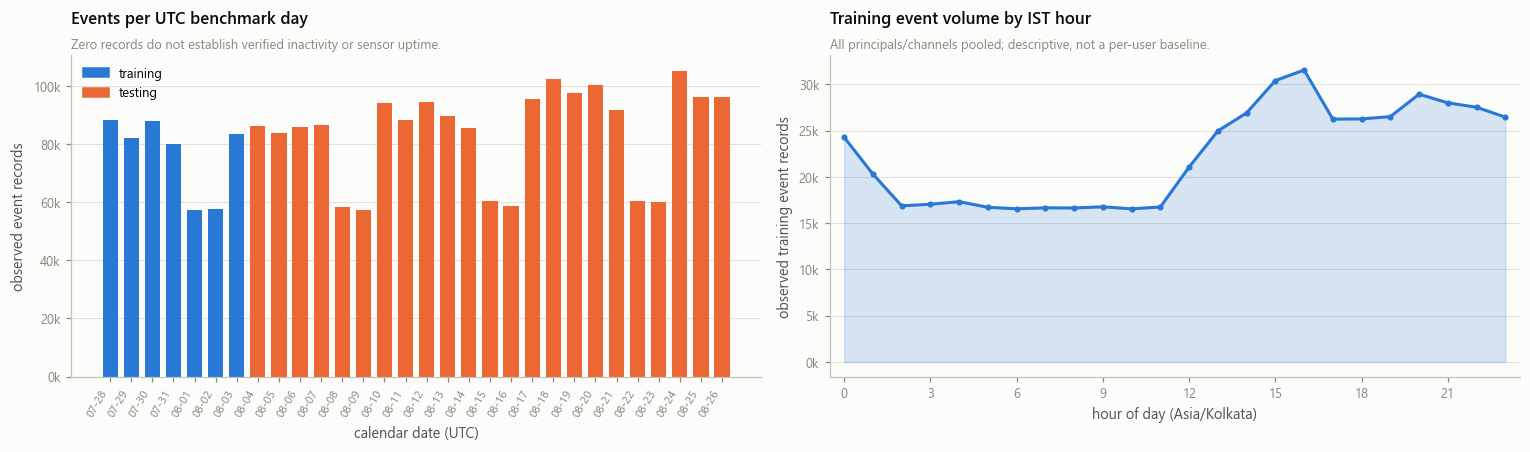

Hourly counts use UTC-selected training events, displayed by IST hour. They They are not exposure-normalized activity rates; partial coverage and collection gaps must be handled separately.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

# ---- daily event volume: UTC benchmark dates -----------------------------------
ax = axes[0]

days = list(per_day.index)
colors = [
    CAT[0] if day in TRAIN_DATES
    else CAT[1] if day in TEST_DATES
    else MUTED
    for day in days
]

ax.bar(
    np.arange(len(days)),
    per_day.to_numpy(),
    color=colors,
    width=0.72,
)

ax.set_xticks(np.arange(len(days)))
ax.set_xticklabels(
    [day[5:] for day in days],
    rotation=60,
    ha="right",
    fontsize=7.5,
)
ax.yaxis.set_major_formatter(
    mpl.ticker.FuncFormatter(lambda value, _: f"{value / 1000:.0f}k")
)

finish(
    ax,
    "Events per UTC benchmark day",
    "Zero records do not establish verified inactivity or sensor uptime.",
    xlabel=f"calendar date ({SPLIT_TZ})",
    ylabel="observed event records",
)

legend_handles = [
    Patch(color=CAT[0], label="training"),
    Patch(color=CAT[1], label="testing"),
]
if outside_dates:
    legend_handles.append(Patch(color=MUTED, label="outside configured split"))

ax.legend(handles=legend_handles, loc="best")

# ---- hourly profile: training dates only, behavioral timezone ------------------
ax = axes[1]

training_event_mask = _event_dates.isin(TRAIN_DATES)

if training_event_mask.any():
    hourly = (
        _local.loc[training_event_mask]
        .dt.hour.value_counts()
        .reindex(range(24), fill_value=0)
        .astype("int64")
        .sort_index()
    )

    assert int(hourly.sum()) == int(training_event_mask.sum())

    hours = hourly.index.to_numpy(dtype=int)
    counts = hourly.to_numpy(dtype=np.int64)

    ax.fill_between(hours, counts, color=CAT[0], alpha=0.18)
    ax.plot(hours, counts, color=CAT[0], marker="o", markersize=3)

    ax.yaxis.set_major_formatter(
        mpl.ticker.FuncFormatter(lambda value, _: f"{value / 1000:.0f}k")
    )
else:
    hourly = pd.Series(
        0, index=pd.Index(range(24), name="hour"),
        dtype="int64", name="events",
    )
    ax.text(
        0.5, 0.5,
        "No events fall in the configured training dates.",
        transform=ax.transAxes,
        ha="center", va="center",
    )

ax.set_xticks(range(0, 24, 3))
ax.set_xlim(-0.5, 23.5)

finish(
    ax,
    "Training event volume by IST hour",
    "All principals/channels pooled; descriptive, not a per-user baseline.",
    xlabel=f"hour of day ({BEHAVIOR_TZ})",
    ylabel="observed training event records",
)

plt.tight_layout()
plt.show()

print(
    "Hourly counts use UTC-selected training events, displayed by IST hour. "
    "They They are not exposure-normalized activity rates; partial coverage and "
    "collection gaps must be handled separately."
)

In [7]:
# ---- event-family classification ----------------------------------------------
# A populated conflicting provider is not silently accepted.
# Missing providers are accepted by channel, but explicitly reported.

def classify_event_family(channels, providers):
    channel = usable_text(channels).str.casefold()
    provider = usable_text(providers).str.casefold()

    channel_sysmon = channel.eq(
        "microsoft-windows-sysmon/operational"
    ).fillna(False)
    channel_security = channel.eq("security").fillna(False)

    provider_sysmon = provider.eq("microsoft-windows-sysmon").fillna(False)
    provider_security = provider.eq(
        "microsoft-windows-security-auditing"
    ).fillna(False)

    missing_provider = provider.isna()

    family = pd.Series("other", index=channels.index, dtype="string")
    family.loc[
        channel_sysmon & (provider_sysmon | missing_provider)
    ] = "sysmon"
    family.loc[
        channel_security & (provider_security | missing_provider)
    ] = "security"

    conflict = (
        (channel_sysmon & ~missing_provider & ~provider_sysmon)
        | (channel_security & ~missing_provider & ~provider_security)
    )
    family.loc[conflict] = "provider_conflict"

    return family


raw["event_family"] = classify_event_family(raw["Channel"], raw["Provider"])

# Reuse these channel-qualified masks in later cells.
IS_SYSMON = raw["event_family"].eq("sysmon")
IS_SECURITY = raw["event_family"].eq("security")

print("Event-family classification:")
display(raw["event_family"].value_counts(dropna=False).rename("events").to_frame())

missing_provider_count = int(usable_text(raw["Provider"]).isna().sum())
if missing_provider_count:
    print(
        f"NOTE: {missing_provider_count:,} records have no usable provider. "
        "Recognized channels provide their provisional family."
    )

conflict_mask = raw["event_family"].eq("provider_conflict")
if conflict_mask.any():
    warnings.warn(
        f"{int(conflict_mask.sum()):,} records have unexpected providers for "
        "their Security/Sysmon channel. Inspect them before attribution. "
        "They are not assigned a trusted event family."
    )
    display(
        raw.loc[conflict_mask]
        .groupby(["Channel", "Provider"], dropna=False)
        .size()
        .rename("events")
        .reset_index()
    )

# ---- identity fields -----------------------------------------------------------
# Compatibility name retained, but authentication TargetUserName is the
# account being authenticated/affected, not necessarily the initiating actor.
SECURITY_ACTOR_FIELD = {
    4624: "TargetUserName",
    4625: "TargetUserName",
    4634: "TargetUserName",
    4647: "SubjectUserName",
    4768: "TargetUserName",
    4769: "TargetUserName",
    4770: "TargetUserName",
    4771: "TargetUserName",
    4776: "TargetUserName",
    4800: "TargetUserName",
    4801: "TargetUserName",

    4688: "SubjectUserName",
    4689: "SubjectUserName",
    4672: "SubjectUserName",
    4648: "SubjectUserName",

    4720: "SubjectUserName",
    4722: "SubjectUserName",
    4723: "SubjectUserName",
    4724: "SubjectUserName",
    4725: "SubjectUserName",
    4726: "SubjectUserName",
    4738: "SubjectUserName",
    4740: "SubjectUserName",
    4767: "SubjectUserName",
    4781: "SubjectUserName",

    4727: "SubjectUserName",
    4728: "SubjectUserName",
    4729: "SubjectUserName",
    4730: "SubjectUserName",
    4731: "SubjectUserName",
    4732: "SubjectUserName",
    4733: "SubjectUserName",
    4734: "SubjectUserName",
    4735: "SubjectUserName",
    4737: "SubjectUserName",
    4754: "SubjectUserName",
    4755: "SubjectUserName",
    4756: "SubjectUserName",
    4757: "SubjectUserName",
    4758: "SubjectUserName",

    4697: "SubjectUserName",
    4698: "SubjectUserName",
    4699: "SubjectUserName",
    4700: "SubjectUserName",
    4701: "SubjectUserName",
    4702: "SubjectUserName",
    1102: "SubjectUserName",
}

SYSMON_ACTOR_FIELD = {
    1: "User", 2: "User", 3: "User", 5: "User",
    6: "User", 7: "User",
    8: "SourceUser", 10: "SourceUser",
    11: "User", 12: "User", 13: "User", 14: "User", 15: "User",
    17: "User", 18: "User", 22: "User", 23: "User", 25: "User",
}
# These are candidate fields. A schema/version may not provide one.
# Presence does not establish a human principal or validate its identity.

SECURITY_IDENTITY_ROLE = {
    eid: (
        "authenticated/affected account"
        if field == "TargetUserName"
        else "subject account"
    )
    for eid, field in SECURITY_ACTOR_FIELD.items()
}
SECURITY_IDENTITY_ROLE[4740] = (
    "subject reporting lockout; locked account remains separate"
)
SECURITY_IDENTITY_ROLE[4648] = (
    "initiating subject; explicit credential target remains separate"
)

# ---- channel-qualified event meanings -----------------------------------------
SYSMON_MEANING = {
    1: "Process created",
    2: "File creation time changed",
    3: "Network connection",
    5: "Process terminated",
    6: "Driver loaded",
    7: "Image loaded",
    8: "CreateRemoteThread",
    10: "Process access",
    11: "File created",
    12: "Registry object created/deleted",
    13: "Registry value set",
    14: "Registry object renamed",
    15: "File stream created",
    17: "Named pipe created",
    18: "Named pipe connected",
    22: "DNS query",
    23: "File deleted (archived)",
    25: "Process tampering",
}

SECURITY_MEANING = {
    1102: "Security audit log cleared",
    4624: "Logon success",
    4625: "Logon failure",
    4634: "Logoff",
    4647: "User initiated logoff",
    4648: "Logon attempted with explicit credentials",
    4672: "Special privileges assigned",
    4688: "Process created",
    4689: "Process exited",
    4697: "Service installed",
    4698: "Scheduled task created",
    4699: "Scheduled task deleted",
    4700: "Scheduled task enabled",
    4701: "Scheduled task disabled",
    4702: "Scheduled task updated",
    4720: "User account created",
    4722: "User account enabled",
    4723: "Password change attempted",
    4724: "Password reset attempted",
    4725: "User account disabled",
    4726: "User account deleted",
    4727: "Global security group created",
    4728: "Member added to global security group",
    4729: "Member removed from global security group",
    4730: "Global security group deleted",
    4731: "Local security group created",
    4732: "Member added to local security group",
    4733: "Member removed from local security group",
    4734: "Local security group deleted",
    4735: "Local security group changed",
    4737: "Global security group changed",
    4738: "User account changed",
    4740: "User account locked out",
    4754: "Universal security group created",
    4755: "Universal security group changed",
    4756: "Member added to universal security group",
    4757: "Member removed from universal security group",
    4758: "Universal security group deleted",
    4767: "User account unlocked",
    4768: "Kerberos TGT requested",
    4769: "Kerberos service ticket requested",
    4770: "Kerberos ticket renewed",
    4771: "Kerberos preauthentication failed",
    4776: "Credential validation",
    4781: "Account name changed",
    4800: "Workstation locked",
    4801: "Workstation unlocked",
    5156: "Filtering platform permitted a connection",
}

EVENT_MEANING_BY_FAMILY = {
    **{("sysmon", eid): text for eid, text in SYSMON_MEANING.items()},
    **{("security", eid): text for eid, text in SECURITY_MEANING.items()},
}

def event_meaning(family, event_id):
    return EVENT_MEANING_BY_FAMILY.get(
        (str(family), int(event_id)), "Unmapped event"
    )

# Legacy compatibility only. New code must use event_meaning(family, eid).
assert set(SYSMON_MEANING).isdisjoint(SECURITY_MEANING)
EVENT_MEANING = {**SYSMON_MEANING, **SECURITY_MEANING}

# ---- catalog: never group on EventID alone -------------------------------------
rows = []

# Group only the columns required by the catalog—not all 86 columns.
catalog_columns = list(dict.fromkeys(
    ["event_family", "Channel", "Provider", "EventID"]
    + list(SECURITY_ACTOR_FIELD.values())
    + list(SYSMON_ACTOR_FIELD.values())
))

catalog_input = raw.reindex(columns=catalog_columns)

groups = catalog_input.groupby(
    ["event_family", "Channel", "Provider", "EventID"],
    dropna=False,
    observed=True,
    sort=False,
)

for (family, channel, provider, eid), sub in groups:
    eid = int(eid)
    count = len(sub)
    field = None
    role = "not assigned"

    if family == "sysmon" and eid in SYSMON_ACTOR_FIELD:
        field = SYSMON_ACTOR_FIELD[eid]
        role = "source process account" if eid in (8, 10) else "event user"
        route = "candidate direct field; GUID fallback where applicable"
    elif family == "security" and eid in SECURITY_ACTOR_FIELD:
        field = SECURITY_ACTOR_FIELD[eid]
        role = SECURITY_IDENTITY_ROLE[eid]
        route = "candidate direct field"
    elif family == "security" and eid == 5156:
        route = "requires validated host/PID/time correlation"
    elif family == "provider_conflict":
        route = "provider conflict; inspect before attribution"
    else:
        route = "no attribution rule configured"

    if field is not None:
        usable = usable_text(
            sub[field] if field in sub.columns
            else pd.Series(pd.NA, index=sub.index, dtype="string")
        )
        usable_count = int(usable.notna().sum())
        coverage_pct = 100.0 * usable_count / count
    else:
        usable_count = pd.NA
        coverage_pct = np.nan

    rows.append({
        "event_family": family,
        "channel": channel,
        "provider": provider,
        "event_id": eid,
        "count": count,
        "pct": 100.0 * count / len(raw),
        "identity_field": field if field else "—",
        "identity_role": role,
        "usable_identity_count": usable_count,
        "field_coverage_pct": coverage_pct,
        "attribution_route": route,
        "meaning": event_meaning(family, eid),
    })

event_catalog = (
    pd.DataFrame(rows)
    .sort_values("count", ascending=False, kind="stable")
    .reset_index(drop=True)
)

assert int(event_catalog["count"].sum()) == len(raw)

# Format the display, not the underlying numeric columns.
display(
    event_catalog.style.format(
        {
            "count": "{:,.0f}",
            "pct": "{:.2f}%",
            "field_coverage_pct": "{:.1f}%",
        },
        na_rep="—",
    )
)

print(
    "This catalog describes available attribution routes. "
    "It does not assign principals or establish correlation accuracy."
)

Event-family classification:


,events
event_family,
security,1874793
sysmon,599139
provider_conflict,5


C:\Users\Aarya.DAS\AppData\Local\Temp\ipykernel_13908\3510556587.py:56: UserWarning: 5 records have unexpected providers for their Security/Sysmon channel. Inspect them before attribution. They are not assigned a trusted event family.
  warnings.warn(


,Channel,Provider,events
0,Security,Microsoft-Windows-Eventlog,5


,event_family,channel,provider,event_id,count,pct,identity_field,identity_role,usable_identity_count,field_coverage_pct,attribution_route,meaning
0,security,Security,Microsoft-Windows-Security-Auditing,5156,"1,086,192",43.91%,—,not assigned,—,—,requires validated host/PID/time correlation,Filtering platform permitted a connection
1,sysmon,Microsoft-Windows-Sysmon/Operational,Microsoft-Windows-Sysmon,22,"179,131",7.24%,User,event user,179131,100.0%,candidate direct field; GUID fallback where applicable,DNS query
2,security,Security,Microsoft-Windows-Security-Auditing,4769,"170,049",6.87%,TargetUserName,authenticated/affected account,170049,100.0%,candidate direct field,Kerberos service ticket requested
3,security,Security,Microsoft-Windows-Security-Auditing,4624,"132,467",5.35%,TargetUserName,authenticated/affected account,132467,100.0%,candidate direct field,Logon success
4,sysmon,Microsoft-Windows-Sysmon/Operational,Microsoft-Windows-Sysmon,1,"121,761",4.92%,User,event user,121761,100.0%,candidate direct field; GUID fallback where applicable,Process created
5,security,Security,Microsoft-Windows-Security-Auditing,4688,"121,761",4.92%,SubjectUserName,subject account,121761,100.0%,candidate direct field,Process created
6,sysmon,Microsoft-Windows-Sysmon/Operational,Microsoft-Windows-Sysmon,5,"121,329",4.90%,User,event user,121329,100.0%,candidate direct field; GUID fallback where applicable,Process terminated
7,security,Security,Microsoft-Windows-Security-Auditing,4689,"117,698",4.76%,SubjectUserName,subject account,117698,100.0%,candidate direct field,Process exited
8,security,Security,Microsoft-Windows-Security-Auditing,4634,"88,205",3.57%,TargetUserName,authenticated/affected account,88205,100.0%,candidate direct field,Logoff
9,security,Security,Microsoft-Windows-Security-Auditing,4768,"87,146",3.52%,TargetUserName,authenticated/affected account,87146,100.0%,candidate direct field,Kerberos TGT requested


This catalog describes available attribution routes. It does not assign principals or establish correlation accuracy.


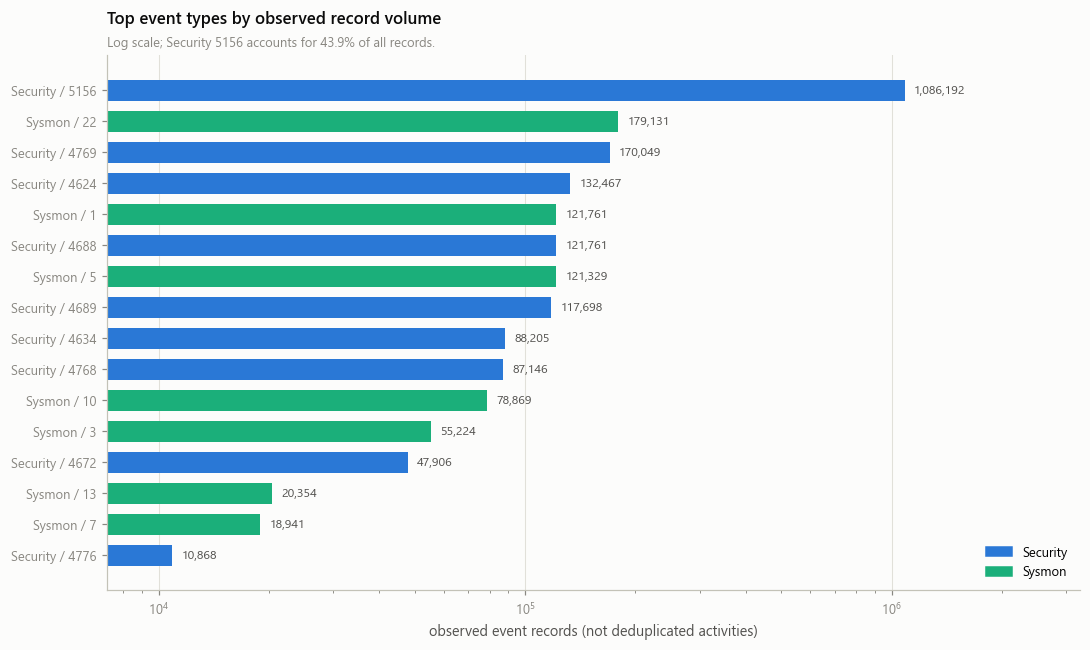

In [8]:
# Aggregate provider variants only for visualization.
# The detailed catalog above retains the provider dimension.
plot_counts = (
    event_catalog
    .groupby(
        ["event_family", "channel", "event_id"],
        dropna=False,
        observed=True,
    )["count"]
    .sum()
    .reset_index()
)

top = (
    plot_counts
    .sort_values("count", ascending=False, kind="stable")
    .head(16)
    .sort_values("count", ascending=True, kind="stable")
    .reset_index(drop=True)
)

family_colors = {
    "security": CAT[0],
    "sysmon": CAT[2],
    "other": MUTED,
    "provider_conflict": STATUS["critical"],
}

def event_plot_label(row):
    if row.event_family == "security":
        prefix = "Security"
    elif row.event_family == "sysmon":
        prefix = "Sysmon"
    else:
        prefix = f"{row.channel} [{row.event_family}]"
    return f"{prefix} / {int(row.event_id)}"

fig, ax = plt.subplots(figsize=(10, 6))

if top.empty:
    ax.text(
        0.5, 0.5, "No event records to display.",
        transform=ax.transAxes, ha="center", va="center",
    )
else:
    positions = np.arange(len(top))
    counts = top["count"].to_numpy(dtype=np.int64)

    ax.barh(
        positions,
        counts,
        color=[
            family_colors.get(family, MUTED)
            for family in top["event_family"]
        ],
        height=0.68,
    )

    ax.set_yticks(positions)
    ax.set_yticklabels(
        [event_plot_label(row) for row in top.itertuples(index=False)]
    )

    for y, count in zip(positions, counts):
        ax.text(
            count * 1.06, y, f"{count:,}",
            va="center", fontsize=8, color=INK2,
        )

    ax.set_xscale("log")
    ax.set_xlim(
        left=max(0.5, float(counts.min()) / 1.5),
        right=float(counts.max()) * 3,
    )

    present_families = set(top["event_family"])
    ax.legend(
        handles=[
            Patch(
                color=family_colors[family],
                label=family.replace("_", " ").title(),
            )
            for family in family_colors
            if family in present_families
        ],
        loc="lower right",
    )

fw_count = int(
    (
        raw["event_family"].eq("security")
        & raw["EventID"].eq(5156)
    ).sum()
)
fw_share = fw_count / len(raw) if len(raw) else 0.0

finish(
    ax,
    "Top event types by observed record volume",
    f"Log scale; Security 5156 accounts for {fw_share:.1%} of all records.",
    xlabel="observed event records (not deduplicated activities)",
    xgrid=True,
)

plt.tight_layout()
plt.show()

In [9]:
#cell8 ---- prerequisites -------------------------------------------------------------
if raw.empty:
    raise ValueError("No events are loaded.")

if not raw.index.is_unique:
    raise ValueError("raw must have a unique row index.")

if not isinstance(raw["timestamp"].dtype, pd.DatetimeTZDtype):
    raise TypeError("timestamp must be timezone-aware.")

window_delta = pd.Timedelta(WINDOW)
if window_delta != pd.Timedelta(minutes=WINDOW_MINUTES):
    raise ValueError("WINDOW and WINDOW_MINUTES disagree.")

# ---- timestamps and benchmark keys --------------------------------------------
# ts stays UTC for joins and event-time comparisons.
# hour/day_type describe local behavioral context, not benchmark date membership.
raw["ts_utc"] = raw["timestamp"].dt.tz_convert("UTC")
raw["ts"] = raw["ts_utc"]
raw["win"] = raw["ts_utc"].dt.floor(WINDOW)

raw["date"] = (
    raw["ts_utc"].dt.strftime("%Y-%m-%d").astype("category")
)

_local_ts = raw["ts_utc"].dt.tz_convert(BEHAVIOR_TZ)
raw["hour"] = _local_ts.dt.hour.astype("uint8")
raw["day_type"] = pd.Categorical(
    np.where(_local_ts.dt.dayofweek >= 5, "weekend", "weekday"),
    categories=["weekday", "weekend"],
)
del _local_ts

observed_days = sorted(raw["date"].dropna().unique().tolist())
outside_days = sorted(set(observed_days) - set(ALL_DATES))
if outside_days:
    raise ValueError(
        f"Events exist outside configured UTC dates: {outside_days}. "
        "Correct the configuration or explicitly filter the source; "
        "do not silently discard them."
    )

print(f"UTC days observed : {len(observed_days)}")
print(f"Configured dates  : {ALL_DATES[0]} -> {ALL_DATES[-1]}")
print(f"First event (UTC) : {raw.ts_utc.min()}")
print(f"Last event  (UTC) : {raw.ts_utc.max()}")
print(f"Behavioral hour   : {BEHAVIOR_TZ}")

# ---- complete UTC window index ------------------------------------------------
configured_start = pd.Timestamp(ALL_DATES[0], tz=SPLIT_TZ)
configured_end = (
    pd.Timestamp(ALL_DATES[-1], tz=SPLIT_TZ) + pd.Timedelta(days=1)
)

window_index = pd.date_range(
    start=configured_start,
    end=configured_end,
    freq=WINDOW,
    inclusive="left",
).tz_convert("UTC")

assert len(window_index) == len(ALL_DATES) * WINDOWS_PER_DAY
assert window_index.is_unique

# Observed envelope only. This is NOT an uptime measurement.
CAPTURE_START = raw["ts_utc"].min().floor(WINDOW)
CAPTURE_END = raw["ts_utc"].max().floor(WINDOW) + window_delta

# Explicit opt-in for a known continuously generated synthetic capture.
# Leave False unless uninterrupted collection over the envelope is confirmed.
ASSUME_CONTINUOUS_SYNTHETIC_CAPTURE = True

WINDOW_COVERAGE = pd.DataFrame({"win": window_index})

in_envelope = (
    WINDOW_COVERAGE["win"].ge(CAPTURE_START)
    & WINDOW_COVERAGE["win"].lt(CAPTURE_END)
)

WINDOW_COVERAGE["observed_records"] = (
    raw.groupby("win", observed=True).size()
    .reindex(window_index, fill_value=0)
    .to_numpy(dtype=np.int64)
)

WINDOW_COVERAGE["coverage_state"] = "unknown"
WINDOW_COVERAGE.loc[
    ~in_envelope, "coverage_state"
] = "outside_observed_envelope"

if ASSUME_CONTINUOUS_SYNTHETIC_CAPTURE:
    WINDOW_COVERAGE.loc[
        in_envelope, "coverage_state"
    ] = "assumed_continuous_synthetic"

# "has_telemetry" is eligibility under the declared coverage policy.
# Record presence alone does not establish complete collection.
WINDOW_COVERAGE["has_telemetry"] = (
    WINDOW_COVERAGE["coverage_state"]
    .eq("assumed_continuous_synthetic")
)

COVERAGE_POLICY = (
    "explicit_assumption_continuous_synthetic_envelope"
    if ASSUME_CONTINUOUS_SYNTHETIC_CAPTURE
    else "unknown_until_collection_coverage_is_supplied"
)

assert int(WINDOW_COVERAGE["observed_records"].sum()) == len(raw)

print("\nCapture envelope—not verified sensor uptime")
print(f"  start, inclusive : {CAPTURE_START}")
print(f"  end, exclusive   : {CAPTURE_END}")
print(f"  configured windows       : {len(window_index):,}")
print(
    "  windows with any records: "
    f"{int(WINDOW_COVERAGE.observed_records.gt(0).sum()):,}"
)
print(f"  coverage policy          : {COVERAGE_POLICY}")

display(
    WINDOW_COVERAGE.groupby("coverage_state", observed=True)
    .agg(
        windows=("win", "size"),
        records=("observed_records", "sum"),
    )
)

if not ASSUME_CONTINUOUS_SYNTHETIC_CAPTURE:
    print(
        "ACTION REQUIRED before baseline fitting: provide collection-coverage "
        "evidence, or explicitly confirm and enable the continuous synthetic "
        "capture assumption above. Unknown windows must not become quiet zeros."
    )

# ---- suspected duplicate records ----------------------------------------------
# Diagnostic only: no events are deleted.
# Use a narrow frame rather than copying/sorting all columns.
duplicate_key = [
    "Channel", "Provider", "Computer",
    "EventRecordID", "EventID", "ts_utc",
]
dup_input = raw.loc[:, duplicate_key].copy()

for col in ("Channel", "Provider", "Computer", "EventRecordID"):
    dup_input[col] = usable_text(dup_input[col])

# Missing record IDs cannot support this duplicate-key test.
valid_duplicate_key = dup_input["EventRecordID"].notna()
suspected_duplicates = int(
    dup_input.loc[valid_duplicate_key].duplicated().sum()
)
missing_record_ids = int((~valid_duplicate_key).sum())

print("\nDuplicate-key diagnostic")
print(f"  repeated keys beyond first occurrence : {suspected_duplicates:,}")
print(f"  rows without usable EventRecordID     : {missing_record_ids:,}")
print("  No records removed; matching keys alone do not prove identical payloads.")

del dup_input, valid_duplicate_key

UTC days observed : 30
Configured dates  : 2026-07-28 -> 2026-08-26
First event (UTC) : 2026-07-28 00:00:23.971389+00:00
Last event  (UTC) : 2026-08-26 23:59:41.108442+00:00
Behavioral hour   : Asia/Kolkata

Capture envelope—not verified sensor uptime
  start, inclusive : 2026-07-28 00:00:00+00:00
  end, exclusive   : 2026-08-27 00:00:00+00:00
  configured windows       : 4,320
  windows with any records: 4,320
  coverage policy          : explicit_assumption_continuous_synthetic_envelope


,windows,records
coverage_state,,
assumed_continuous_synthetic,4320,2473937



Duplicate-key diagnostic
  repeated keys beyond first occurrence : 0
  rows without usable EventRecordID     : 0
  No records removed; matching keys alone do not prove identical payloads.


In [10]:
#cell 9
#  ---- canonical identity rules --------------------------------------------------
# Populate only from verified environment metadata.
# Example, ONLY if confirmed:
 
#DOMAIN_ALIASES = {}
# Confirmed aliases for the same AD domain:
DOMAIN_ALIASES = {
    "corp.local": "corp",
}

# No automatic domain assignment for bare names.
# Their unresolved namespace is kept visible.
UNQUALIFIED_NAMESPACE = "[unqualified]"

def canonical_identity(names, domains=None):
    """
    Return canonical domain\\account strings.
    Supports DOMAIN\\name and name@domain.
    Bare names without domain information remain explicitly unqualified.
    """
    names = usable_text(names).str.casefold()

    if domains is None:
        domains = pd.Series(pd.NA, index=names.index, dtype="string")
    else:
        domains = usable_text(domains).str.casefold()

    account = names.copy()
    domain = domains.copy()

    slash_parts = names.str.partition("\\", expand=True)
    has_slash = names.str.contains("\\", regex=False, na=False)

    domain.loc[has_slash] = slash_parts.loc[has_slash, 0]
    account.loc[has_slash] = slash_parts.loc[has_slash, 2]

    upn_parts = names.str.rpartition("@", expand=True)
    has_upn = ~has_slash & names.str.contains("@", regex=False, na=False)

    domain.loc[has_upn] = upn_parts.loc[has_upn, 2]
    account.loc[has_upn] = upn_parts.loc[has_upn, 0]

    account = usable_text(account)
    domain = usable_text(domain)

    # Reject malformed identities rather than creating bogus inventory values.
    malformed = (
        account.str.contains(r"[\\@]", regex=True, na=False)
        | domain.str.contains(r"[\\@]", regex=True, na=False)
    )

    if DOMAIN_ALIASES:
        aliases = {
            str(k).strip().casefold(): str(v).strip().casefold()
            for k, v in DOMAIN_ALIASES.items()
        }
        domain = domain.replace(aliases)

    domain = domain.fillna(UNQUALIFIED_NAMESPACE)
    result = domain + "\\" + account
    return result.mask(account.isna() | malformed).astype("string")


# Compatibility helper: deliberately no longer strips domain namespaces.
# Subsequent corrected cells will call canonical_identity explicitly.
def strip_domain(series):
    return canonical_identity(series)


# Explicit string dtypes avoid large object-typed attribution columns.
raw["attr_user"] = pd.Series(pd.NA, index=raw.index, dtype="string")
raw["attr_method"] = pd.Series(pd.NA, index=raw.index, dtype="string")
raw["attr_role"] = pd.Series(pd.NA, index=raw.index, dtype="string")

def assign_direct_identity(mask, field, method, role, domain_field=None):
    """Fill unresolved records only, using a documented field mapping."""
    if field not in raw.columns:
        return

    mask = mask & raw["attr_user"].isna()
    idx = raw.index[mask]
    if len(idx) == 0:
        return

    domains = (
        raw.loc[idx, domain_field]
        if domain_field is not None and domain_field in raw.columns
        else None
    )

    identity = canonical_identity(raw.loc[idx, field], domains)
    good_idx = identity.index[identity.notna()]

    raw.loc[good_idx, "attr_user"] = identity.loc[good_idx]
    raw.loc[good_idx, "attr_method"] = method
    raw.loc[good_idx, "attr_role"] = role


# Recalculate masks from current raw rather than trusting stale global arrays.
sysmon_mask = raw["event_family"].eq("sysmon")
security_mask = raw["event_family"].eq("security")

# ---- Tier A1: Sysmon event-native identity -------------------------------------
for eid, field in SYSMON_ACTOR_FIELD.items():
    assign_direct_identity(
        mask=sysmon_mask & raw["EventID"].eq(eid),
        field=field,
        method=f"A1_sysmon_{field}",
        role="source process account" if eid in (8, 10) else "event user",
    )

# ---- Tier A2: Security identity by documented semantic role ---------------------
for eid, field in SECURITY_ACTOR_FIELD.items():
    domain_field = (
        "TargetDomainName" if field == "TargetUserName"
        else "SubjectDomainName"
    )

    assign_direct_identity(
        mask=security_mask & raw["EventID"].eq(eid),
        field=field,
        domain_field=domain_field,
        method=f"A2_security_{field}",
        role=SECURITY_IDENTITY_ROLE[eid],
    )

# Leave unresolved methods as NA for subsequent GUID/PID correlation.
# Final C_unattributed assignment occurs only after all correlation tiers.
attributed = raw["attr_user"].notna()

assert raw.loc[attributed, "attr_method"].notna().all()
assert raw.loc[attributed, "attr_role"].notna().all()
assert raw.loc[~attributed, "attr_method"].isna().all()

print(
    f"Direct identity assigned: {int(attributed.sum()):,} / "
    f"{len(raw):,} ({attributed.mean():.1%})"
)
print(f"Distinct canonical principals: {raw.attr_user.nunique():,}")

display(
    raw["attr_method"].value_counts()
    .rename("events")
    .to_frame()
)

unqualified_count = int(
    raw["attr_user"].str.startswith(
        UNQUALIFIED_NAMESPACE + "\\", na=False
    ).sum()
)
print(f"Records with unresolved identity namespace: {unqualified_count:,}")
print(
    "Direct assignment does not prove a human actor. Authentication targets, "
    "service identities, and machine accounts remain distinguishable for "
    "later scoping. No target/source identities have been substituted."
)

Direct identity assigned: 1,387,740 / 2,473,937 (56.1%)
Distinct canonical principals: 49


,events
attr_method,
A1_sysmon_User,519133
A2_security_TargetUserName,493328
A2_security_SubjectUserName,295273
A1_sysmon_SourceUser,80006


Records with unresolved identity namespace: 11,178
Direct assignment does not prove a human actor. Authentication targets, service identities, and machine accounts remain distinguishable for later scoping. No target/source identities have been substituted.


In [11]:
# cell10---- shared correlation-key helpers -------------------------------------------
def canonical_host(series):
    """Normalize spelling, preserving the full hostname/domain."""
    return usable_text(series).str.casefold().str.rstrip(".")

def canonical_guid(series):
    """Normalize valid nonzero GUID strings; reject placeholders/malformed GUIDs."""
    values = (
        usable_text(series)
        .str.casefold()
        .str.replace(r"^\{(.*)\}$", r"\1", regex=True)
    )
    valid = values.str.fullmatch(
        r"[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-"
        r"[0-9a-f]{4}-[0-9a-f]{12}",
        na=False,
    )
    valid &= values.ne("00000000-0000-0000-0000-000000000000").fillna(False)
    return values.where(valid)


# These fields must identify the initiating/owning process.
# Sysmon 6 (driver load) is deliberately excluded: it is not a process-GUID route.
SYSMON_GUID_FIELD = {
    eid: "ProcessGuid"
    for eid in (
        2, 3, 5, 7, 11, 12, 13, 14, 15,
        17, 18, 22, 23, 25,
    )
}
SYSMON_GUID_FIELD.update({
    8: "SourceProcessGuid",
    10: "SourceProcessGuid",
})

# Cell 3 already canonicalizes SourceProcessGUID -> SourceProcessGuid.
# Do not substitute target GUIDs or ordinary ProcessGuid for event 8/10.
anchor_mask = (
    raw["event_family"].eq("sysmon")
    & raw["EventID"].eq(1)
    & raw["attr_method"].eq("A1_sysmon_User").fillna(False)
    & raw["attr_user"].notna()
)

# Narrow projection: never copy the entire event table.
anchors = raw.loc[
    anchor_mask,
    ["Computer", "ProcessGuid", "ts_utc", "attr_user"],
].copy()

anchors["host"] = canonical_host(anchors["Computer"])
anchors["guid"] = canonical_guid(anchors["ProcessGuid"])
anchors = anchors.dropna(subset=["host", "guid", "attr_user", "ts_utc"])

# A key with conflicting owners or creation timestamps is unsafe.
anchor_summary = (
    anchors.groupby(["host", "guid"], observed=True, sort=False)
    .agg(
        n_users=("attr_user", "nunique"),
        n_start_times=("ts_utc", "nunique"),
        anchor_user=("attr_user", "first"),
        anchor_start=("ts_utc", "min"),
        anchor_records=("attr_user", "size"),
    )
    .reset_index()
)

conflicting = (
    anchor_summary["n_users"].ne(1)
    | anchor_summary["n_start_times"].ne(1)
)

safe_anchors = anchor_summary.loc[
    ~conflicting,
    ["host", "guid", "anchor_user", "anchor_start"],
].copy()

assert not safe_anchors.duplicated(["host", "guid"]).any()

print(f"Anchored process keys             : {len(anchor_summary):,}")
print(f"Conflicting keys excluded         : {int(conflicting.sum()):,}")
print(f"Unambiguous process keys available: {len(safe_anchors):,}")

n_fixed = 0
future_rejected = 0

for eid, guid_field in SYSMON_GUID_FIELD.items():
    if guid_field not in raw.columns:
        continue

    mask = (
        raw["event_family"].eq("sysmon")
        & raw["EventID"].eq(eid)
        & raw["attr_user"].isna()
    )
    idx = raw.index[mask]
    if len(idx) == 0 or safe_anchors.empty:
        continue

    candidates = pd.DataFrame({
        "row_id": idx,
        "host": canonical_host(raw.loc[idx, "Computer"]).to_numpy(),
        "guid": canonical_guid(raw.loc[idx, guid_field]).to_numpy(),
        "event_time": raw.loc[idx, "ts_utc"].to_numpy(),
    })
    candidates = candidates.dropna(subset=["host", "guid", "event_time"])

    matched = candidates.merge(
        safe_anchors,
        on=["host", "guid"],
        how="left",
        validate="many_to_one",
    )

    has_anchor = matched["anchor_user"].notna()
    past_anchor = matched["anchor_start"].le(matched["event_time"])
    future_rejected += int((has_anchor & ~past_anchor).sum())

    hits = matched.loc[has_anchor & past_anchor]
    if hits.empty:
        continue

    hit_idx = hits["row_id"].to_numpy()
    assert raw.loc[hit_idx, "attr_user"].isna().all()

    raw.loc[hit_idx, "attr_user"] = hits["anchor_user"].to_numpy()
    raw.loc[hit_idx, "attr_method"] = (
        f"A1b_sysmon_processguid_fallback_eid{eid}"
    )
    raw.loc[hit_idx, "attr_role"] = (
        "inferred source process account"
        if eid in (8, 10)
        else "inferred process account"
    )
    n_fixed += len(hits)

print(f"\nEvents recovered through GUID fallback: {n_fixed:,}")
print(f"Future-anchor matches rejected        : {future_rejected:,}")
print(
    f"Direct + GUID-attributed events       : "
    f"{raw.attr_user.notna().sum():,} / {len(raw):,}"
)
print(
    "Fallback identifies the anchored process account, not necessarily an "
    "impersonated thread token or a human operator. Direct identities were not overwritten."
)

assert raw.loc[raw.attr_user.notna(), "attr_method"].notna().all()
assert raw.loc[raw.attr_user.notna(), "attr_role"].notna().all()

# Keep safe_anchors for later diagnostics if needed.
del anchors, anchor_summary

Anchored process keys             : 121,761
Conflicting keys excluded         : 0
Unambiguous process keys available: 121,761

Events recovered through GUID fallback: 0
Future-anchor matches rejected        : 0
Direct + GUID-attributed events       : 1,387,740 / 2,473,937
Fallback identifies the anchored process account, not necessarily an impersonated thread token or a human operator. Direct identities were not overwritten.


In [12]:
#cell11 ---- numeric identifier normalization ------------------------------------------
def canonical_numeric_id(series, allow_zero=False):
    """
    Normalize decimal or 0x-prefixed unsigned 64-bit identifiers to decimal strings.
    Parse distinct values once; avoid float conversion and precision loss.
    """
    text = usable_text(series).str.casefold()

    def parse_one(value):
        try:
            if re.fullmatch(r"0x[0-9a-f]+", value):
                number = int(value, 16)
            elif re.fullmatch(r"[0-9]+", value):
                number = int(value, 10)
            else:
                return None

            if not 0 <= number <= (2**64 - 1):
                return None
            if number == 0 and not allow_zero:
                return None
            return str(number)
        except (ValueError, TypeError):
            return None

    lookup = {value: parse_one(value) for value in text.dropna().unique()}
    return text.map(lookup).astype("string")


# ---- retain individual 4624 records -------------------------------------------
session_cols = [
    "ts_utc", "Computer", "TargetUserName", "TargetDomainName",
    "TargetLogonId", "LogonType", "LogonGuid", "IpAddress",
    "WorkstationName", "ProcessName",
]

sess = raw.loc[
    raw["event_family"].eq("security") & raw["EventID"].eq(4624),
    session_cols,
].copy()

sess = sess.rename(columns={"ts_utc": "logon_time"})
sess["host"] = canonical_host(sess["Computer"])
sess["logon_id"] = canonical_numeric_id(sess["TargetLogonId"])
sess["user"] = canonical_identity(
    sess["TargetUserName"], sess["TargetDomainName"]
)
sess["logon_guid"] = canonical_guid(sess["LogonGuid"])

print(f"Security 4624 records: {len(sess):,}")
print(f"Usable LogonIds      : {sess.logon_id.notna().sum():,}")
display(
    pd.to_numeric(sess["LogonType"], errors="coerce")
    .value_counts(dropna=False)
    .rename("records")
    .to_frame()
)

# This summary diagnoses key reuse/conflict. It is NOT an attribution lookup.
valid_sessions = sess.dropna(
    subset=["host", "logon_id", "user", "logon_time"]
)

sess_key = (
    valid_sessions.groupby(["host", "logon_id"], observed=True, sort=False)
    .agg(
        n_users=("user", "nunique"),
        user=("user", "first"),
        first_logon=("logon_time", "min"),
        last_logon=("logon_time", "max"),
        n_logons=("user", "size"),
    )
    .reset_index()
)

ambiguous = int(sess_key["n_users"].gt(1).sum())
print(f"\nDistinct host/LogonId keys: {len(sess_key):,}")
print(f"Keys with multiple users : {ambiguous:,}")
print(
    "A zero conflict count does not prove uniqueness across reboots "
    "or establish session lifetime."
)

# ---- diagnostic: latest preceding candidate session -----------------------------
# This does NOT fill raw.attr_user. Boot/lifetime verification is not available here.
s1 = raw.loc[
    raw["event_family"].eq("sysmon") & raw["EventID"].eq(1),
    ["ts_utc", "Computer", "LogonId", "User"],
].copy()

s1["host"] = canonical_host(s1["Computer"])
s1["logon_id"] = canonical_numeric_id(s1["LogonId"])
s1["user_direct"] = canonical_identity(s1["User"])

# Exclude globally conflicting keys from this conservative diagnostic.
safe_session_keys = sess_key.loc[
    sess_key["n_users"].eq(1), ["host", "logon_id"]
]

session_candidates = valid_sessions[
    ["host", "logon_id", "logon_time", "user"]
].merge(
    safe_session_keys,
    on=["host", "logon_id"],
    how="inner",
    validate="many_to_one",
)

session_candidates = (
    session_candidates
    .rename(columns={"user": "session_user"})
    .drop_duplicates(["host", "logon_id", "logon_time"])
    .sort_values("logon_time", kind="stable")
)

process_candidates = (
    s1.dropna(subset=["host", "logon_id", "ts_utc", "user_direct"])
    .copy()
)
process_candidates["process_row"] = process_candidates.index

if not process_candidates.empty and not session_candidates.empty:
    # Use consistent key dtypes for merge_asof across pandas versions.
    for frame in (process_candidates, session_candidates):
        frame["host"] = frame["host"].astype(str)
        frame["logon_id"] = frame["logon_id"].astype(str)

    j = pd.merge_asof(
        process_candidates.sort_values("ts_utc", kind="stable"),
        session_candidates,
        left_on="ts_utc",
        right_on="logon_time",
        by=["host", "logon_id"],
        direction="backward",
        allow_exact_matches=True,
    )

    matched = j["session_user"].notna()
    n_matched = int(matched.sum())
    n_agree = int(
        j.loc[matched, "session_user"]
        .eq(j.loc[matched, "user_direct"])
        .sum()
    )

    assert (
        j.loc[matched, "logon_time"] <= j.loc[matched, "ts_utc"]
    ).all()

    print("\nPast-only candidate-match diagnostic")
    print(f"  Total Sysmon Event 1 records : {len(s1):,}")
    print(f"  Records with usable keys/user: {len(process_candidates):,}")
    print(f"  Matched candidate sessions   : {n_matched:,}")

    if n_matched:
        print(f"  Exact canonical-name agreement: {n_agree / n_matched:.2%}")
        print(f"  Disagreements                 : {n_matched - n_agree:,}")

        disagreements = j.loc[
            matched & j["session_user"].ne(j["user_direct"]),
            [
                "ts_utc", "host", "logon_id",
                "user_direct", "session_user", "logon_time",
            ],
        ]
        if not disagreements.empty:
            display(disagreements.head(10))
    else:
        print("  Agreement: unavailable; no candidate matches.")

    del j
else:
    print("\nSession-match diagnostic unavailable: no usable candidate population.")

print(
    "\nNo attribution was changed by this diagnostic. Exact-name disagreement "
    "may reflect unresolved domain aliases as well as genuine mismatches. "
    "A preceding logon alone does not prove a valid session across reboot/ID reuse."
)

del s1, process_candidates, session_candidates, valid_sessions

Security 4624 records: 132,467
Usable LogonIds      : 132,467


,records
LogonType,
3,85000
5,43848
10,2292
2,928
7,396
11,3



Distinct host/LogonId keys: 88,259
Keys with multiple users : 0
A zero conflict count does not prove uniqueness across reboots or establish session lifetime.

Past-only candidate-match diagnostic
  Total Sysmon Event 1 records : 121,761
  Records with usable keys/user: 121,761
  Matched candidate sessions   : 121,392
  Exact canonical-name agreement: 100.00%
  Disagreements                 : 0

No attribution was changed by this diagnostic. Exact-name disagreement may reflect unresolved domain aliases as well as genuine mismatches. A preceding logon alone does not prove a valid session across reboot/ID reuse.


In [13]:
# Cell 12 — Process-lifetime correlation for Security 5156
# Requires corrected Cells 1–11.
#
# Conservative policy:
# - require an observed, unambiguous termination;
# - use host + PID + time and host + GUID;
# - retain unsafe starts as barriers against matching older PID generations;
# - never overwrite source Image/Application fields.

FW_CORRELATION_CHUNK = 100_000


def normalized_windows_path(series):
    return (
        usable_text(series)
        .str.casefold()
        .str.replace("/", "\\", regex=False)
    )


def path_basename(series):
    return normalized_windows_path(series).str.rsplit("\\", n=1).str[-1]


def bool_mask(series):
    """Convert a possibly nullable boolean Series into a nonmissing bool mask."""
    return series.astype("boolean").fillna(False).astype(bool)


# ---- prerequisites -------------------------------------------------------------
required = {
    "event_family", "EventID", "ts_utc", "Computer",
    "ProcessId", "ProcessID", "ProcessGuid", "Image", "Application",
    "attr_user", "attr_method", "attr_role",
}
missing = sorted(required - set(raw.columns))
if missing:
    raise ValueError(f"Cell 12 prerequisites missing: {missing}")

if not raw.index.is_unique:
    raise ValueError("raw must have a unique index.")

if not isinstance(raw["ts_utc"].dtype, pd.DatetimeTZDtype):
    raise TypeError("raw.ts_utc must be timezone-aware.")

if raw["ts_utc"].isna().any():
    raise ValueError("Missing event timestamps are not permitted.")


# ---- rerun safety --------------------------------------------------------------
fw_mask = bool_mask(
    raw["event_family"].eq("security") & raw["EventID"].eq(5156)
)

# Clear only assignments created by this correlation tier.
# Preserve any attribution from other methods.
previous_b = bool_mask(
    fw_mask & raw["attr_method"].eq("B_5156_proc_lifetime")
)
for column in ("attr_user", "attr_method", "attr_role"):
    raw.loc[previous_b, column] = pd.NA

# Preserve diagnostic values on non-5156 records, if any.
for column in ("correlated_image", "fw_correlation_status"):
    if column not in raw.columns:
        raw[column] = pd.Series(pd.NA, index=raw.index, dtype="string")
    else:
        raw[column] = raw[column].astype("string")
    raw.loc[fw_mask, column] = pd.NA


# ---- process starts: narrow projection -----------------------------------------
start_mask = bool_mask(
    raw["event_family"].eq("sysmon") & raw["EventID"].eq(1)
)

starts = raw.loc[
    start_mask,
    ["ts_utc", "Computer", "ProcessId", "ProcessGuid", "Image", "attr_user"],
].copy()

starts = starts.rename(columns={
    "ts_utc": "proc_start",
    "attr_user": "process_user",
    "Image": "process_image",
})

starts["host"] = canonical_host(starts["Computer"])
starts["pid"] = canonical_numeric_id(starts["ProcessId"])
starts["guid"] = canonical_guid(starts["ProcessGuid"])

# Normalize image strings before detecting conflicts.
starts["process_image"] = normalized_windows_path(starts["process_image"])
starts["process_user"] = usable_text(starts["process_user"])

invalid_start_keys = int(
    starts[["host", "pid", "proc_start"]].isna().any(axis=1).sum()
)
starts = starts.dropna(subset=["host", "pid", "proc_start"])

# Keep starts without a user/GUID: they still block older PID generations.
guid_summary = (
    starts.dropna(subset=["guid"])
    .groupby(["host", "guid"], observed=True, sort=False)
    .agg(
        start_times=("proc_start", "nunique"),
        pids=("pid", "nunique"),
        users=("process_user", "nunique"),
        images=("process_image", "nunique"),
    )
)

bad_guid_mask = (
    guid_summary["start_times"].ne(1)
    | guid_summary["pids"].ne(1)
    | guid_summary["users"].gt(1)
    | guid_summary["images"].gt(1)
)
bad_guid_keys = guid_summary.index[bad_guid_mask]

start_guid_keys = pd.MultiIndex.from_frame(starts[["host", "guid"]])
starts["bad_guid"] = start_guid_keys.isin(bad_guid_keys)

# Collapse duplicate start records, recording ambiguity.
proc = (
    starts.groupby(
        ["host", "pid", "proc_start"],
        observed=True,
        sort=False,
    )
    .agg(
        guid=("guid", "first"),
        process_user=("process_user", "first"),
        process_image=("process_image", "first"),
        n_guids=("guid", "nunique"),
        n_users=("process_user", "nunique"),
        n_images=("process_image", "nunique"),
        bad_guid=("bad_guid", "max"),
    )
    .reset_index()
)

proc["ambiguous_start"] = bool_mask(
    proc["n_guids"].ne(1)
    | proc["n_users"].ne(1)
    | proc["n_images"].gt(1)
    | proc["bad_guid"]
)


# ---- process terminations: narrow projection -----------------------------------
end_mask = bool_mask(
    raw["event_family"].eq("sysmon") & raw["EventID"].eq(5)
)

ends = raw.loc[
    end_mask,
    ["ts_utc", "Computer", "ProcessGuid"],
].copy()

ends["host"] = canonical_host(ends["Computer"])
ends["guid"] = canonical_guid(ends["ProcessGuid"])
ends = ends.dropna(subset=["host", "guid", "ts_utc"])

end_summary = (
    ends.groupby(["host", "guid"], observed=True, sort=False)
    .agg(
        proc_end=("ts_utc", "min"),
        n_end_times=("ts_utc", "nunique"),
    )
    .reset_index()
)

proc = proc.merge(
    end_summary,
    on=["host", "guid"],
    how="left",
    validate="many_to_one",
)

proc = proc.sort_values(
    ["host", "pid", "proc_start"], kind="stable"
).reset_index(drop=True)

proc["next_start"] = (
    proc.groupby(["host", "pid"], observed=True, sort=False)["proc_start"]
    .shift(-1)
)

proc["valid_interval"] = bool_mask(
    ~proc["ambiguous_start"]
    & proc["process_user"].notna()
    & proc["guid"].notna()
    & proc["proc_end"].notna()
    & proc["n_end_times"].eq(1)
    & proc["proc_end"].gt(proc["proc_start"])
)

overlap_conflict = bool_mask(
    proc["next_start"].notna()
    & proc["proc_end"].gt(proc["next_start"])
)
proc.loc[overlap_conflict, "valid_interval"] = False

assert not proc.duplicated(["host", "pid", "proc_start"]).any()

print("Process correlation evidence")
print(f"  Invalid start keys excluded : {invalid_start_keys:,}")
print(f"  PID-generation rows         : {len(proc):,}")
print(f"  Ambiguous starts            : {int(proc.ambiguous_start.sum()):,}")
print(f"  Missing termination         : {int(proc.proc_end.isna().sum()):,}")
print(f"  Termination/reuse conflicts : {int(overlap_conflict.sum()):,}")
print(f"  Eligible observed lifetimes : {int(proc.valid_interval.sum()):,}")


# ---- correlation lookup --------------------------------------------------------
# Do not remove unsafe generations: they prevent matching an older process.
right = proc[
    [
        "host", "pid", "proc_start", "proc_end", "next_start",
        "process_user", "process_image", "valid_interval",
    ]
].copy()

right["host"] = right["host"].astype(str)
right["pid"] = right["pid"].astype(str)
right = right.sort_values("proc_start", kind="stable")

fw_all_idx = raw.index[fw_mask]
fw_idx = raw.index[fw_mask & raw["attr_user"].isna()]

raw.loc[fw_all_idx, "fw_correlation_status"] = "not_attempted"

existing_idx = raw.index[fw_mask & raw["attr_user"].notna()]
raw.loc[
    existing_idx, "fw_correlation_status"
] = "existing_attribution_preserved"

n_ok = 0

for offset in range(0, len(fw_idx), FW_CORRELATION_CHUNK):
    idx = fw_idx[offset:offset + FW_CORRELATION_CHUNK]

    # Reset the small frame's index, retaining the original row key separately.
    fw = raw.loc[
        idx, ["ts_utc", "Computer", "ProcessID", "Application"]
    ].copy()
    fw.insert(0, "row_id", fw.index)
    fw = fw.reset_index(drop=True)

    fw = fw.rename(columns={
        "ts_utc": "event_time",
        "Application": "application",
    })
    fw["host"] = canonical_host(fw["Computer"])
    fw["pid"] = canonical_numeric_id(fw["ProcessID"])

    valid_keys = fw["host"].notna() & fw["pid"].notna()

    invalid_idx = fw.loc[~valid_keys, "row_id"].to_numpy()
    raw.loc[
        invalid_idx, "fw_correlation_status"
    ] = "invalid_host_or_pid"

    fw = fw.loc[
        valid_keys,
        ["row_id", "event_time", "host", "pid", "application"],
    ].copy()

    if fw.empty:
        continue

    fw["host"] = fw["host"].astype(str)
    fw["pid"] = fw["pid"].astype(str)

    if right.empty:
        raw.loc[
            fw["row_id"].to_numpy(), "fw_correlation_status"
        ] = "no_process_start"
        continue

    matched = pd.merge_asof(
        fw.sort_values("event_time", kind="stable"),
        right,
        left_on="event_time",
        right_on="proc_start",
        by=["host", "pid"],
        direction="backward",
        allow_exact_matches=True,
    )

    has_start = matched["proc_start"].notna()

    # Important: cast nullable results BEFORE any boolean evaluation.
    valid_interval = bool_mask(matched["valid_interval"])

    in_interval = bool_mask(
        has_start
        & valid_interval
        & matched["event_time"].ge(matched["proc_start"])
        & matched["event_time"].lt(matched["proc_end"])
        & (
            matched["next_start"].isna()
            | matched["event_time"].lt(matched["next_start"])
        )
    )

    # Explicit string dtype prevents object-array comparisons involving pd.NA.
    app_path = normalized_windows_path(matched["application"])
    proc_path = normalized_windows_path(matched["process_image"])
    app_base = app_path.str.rsplit("\\", n=1).str[-1].astype("string")
    proc_base = proc_path.str.rsplit("\\", n=1).str[-1].astype("string")

    both_paths = app_path.notna() & proc_path.notna()

    basename_conflict = bool_mask(
        both_paths & app_base.ne(proc_base)
    )

    both_drive_paths = bool_mask(
        app_path.str.match(r"^[a-z]:\\", na=False)
        & proc_path.str.match(r"^[a-z]:\\", na=False)
    )

    full_path_conflict = bool_mask(
        both_drive_paths & app_path.ne(proc_path)
    )

    image_conflict = basename_conflict | full_path_conflict

    image_check_available = (
        both_paths
        & app_base.notna()
        & proc_base.notna()
        & app_base.ne("").fillna(False)
        & proc_base.ne("").fillna(False)
    )
    image_check_available = bool_mask(image_check_available)

    accepted = bool_mask(
        in_interval & image_check_available & ~image_conflict
    )
    exact_image = bool_mask(app_path.eq(proc_path))

    status = pd.Series(
        "no_process_start", index=matched.index, dtype="string"
    )
    status.loc[has_start] = "unsafe_or_incomplete_lifetime"
    status.loc[
        has_start & valid_interval & ~in_interval
    ] = "outside_lifetime"
    status.loc[
        in_interval & ~image_check_available
    ] = "missing_image_context"
    status.loc[
        in_interval & image_conflict
    ] = "image_conflict"
    status.loc[
        accepted & exact_image
    ] = "matched_exact_path"
    status.loc[
        accepted & ~exact_image
    ] = "matched_basename_path_mapping_unverified"

    raw.loc[
        matched["row_id"].to_numpy(), "fw_correlation_status"
    ] = status.to_numpy()

    hits = matched.loc[accepted]
    if not hits.empty:
        hit_idx = hits["row_id"].to_numpy()

        assert raw.loc[hit_idx, "attr_user"].isna().all()
        assert hits["process_user"].notna().all()
        assert hits["proc_start"].le(hits["event_time"]).all()
        assert hits["event_time"].lt(hits["proc_end"]).all()

        raw.loc[hit_idx, "attr_user"] = hits["process_user"].to_numpy()
        raw.loc[hit_idx, "attr_method"] = "B_5156_proc_lifetime"
        raw.loc[hit_idx, "attr_role"] = "inferred process account"
        raw.loc[
            hit_idx, "correlated_image"
        ] = hits["process_image"].to_numpy()

        n_ok += len(hits)


# ---- reconcile and report ------------------------------------------------------
b_mask = bool_mask(
    fw_mask & raw["attr_method"].eq("B_5156_proc_lifetime")
)

assert int(b_mask.sum()) == n_ok
assert raw.loc[b_mask, "attr_user"].notna().all()
assert raw.loc[b_mask, "correlated_image"].notna().all()
assert raw.loc[fw_all_idx, "fw_correlation_status"].notna().all()

print(
    f"\n5156 events attributed by this tier: "
    f"{n_ok:,} / {len(fw_idx):,} eligible unresolved records"
)

fw_report = (
    raw.loc[fw_all_idx, "fw_correlation_status"]
    .value_counts(dropna=False)
    .rename("events")
    .to_frame()
)

assert int(fw_report["events"].sum()) == len(fw_all_idx)
display(fw_report)

print(
    "Original Image/Application fields are unchanged. "
    "These are process-account inferences; incomplete collection or missing "
    "reboot evidence can still limit reliability. Nonidentical paths accepted "
    "by basename are explicitly marked as path-mapping-unverified."
)

del starts, ends, end_summary, guid_summary, right

Process correlation evidence
  Invalid start keys excluded : 0
  PID-generation rows         : 121,761
  Ambiguous starts            : 0
  Missing termination         : 513
  Termination/reuse conflicts : 0
  Eligible observed lifetimes : 121,248

5156 events attributed by this tier: 77,427 / 1,086,192 eligible unresolved records


,events
fw_correlation_status,
no_process_start,969635
matched_basename_path_mapping_unverified,77427
outside_lifetime,36381
unsafe_or_incomplete_lifetime,1893
image_conflict,856


Original Image/Application fields are unchanged. These are process-account inferences; incomplete collection or missing reboot evidence can still limit reliability. Nonidentical paths accepted by basename are explicitly marked as path-mapping-unverified.


In [14]:
#cell13 ---- DNS ownership policy ------------------------------------------------------
# Keep event-native or process-correlated identities.
# Do not overwrite service-account attribution with a presumed workstation owner.

if DNS_HOST_OWNER:
    raise ValueError(
        "DNS_HOST_OWNER must remain False in this pipeline. "
        "A dominant workstation user does not establish DNS request ownership."
    )

HOST_OWNER = {}  # compatibility only; no inferred identity replacements

dns_mask = (
    raw["event_family"].eq("sysmon")
    & raw["EventID"].eq(22)
)

dns_count = int(dns_mask.sum())
dns_attributed = int(raw.loc[dns_mask, "attr_user"].notna().sum())

print("DNS workstation-owner reassignment: disabled")
print(f"Sysmon DNS records               : {dns_count:,}")
print(f"Records with an attributed account: {dns_attributed:,}")
print(
    "An attributed service account remains a service account. "
    "Unresolved DNS remains unresolved; it is not assigned to a presumed person."
)

# Finalize unresolved methods AFTER direct, GUID, and PID correlation.
# This is intentionally outside every optional DNS block.
missing_identity = raw["attr_user"].isna()
raw.loc[missing_identity, "attr_method"] = "C_unattributed"
raw.loc[missing_identity, "attr_role"] = "unresolved"

assert raw["attr_method"].notna().all()
assert raw.loc[~missing_identity, "attr_role"].notna().all()
assert raw.loc[
    raw["attr_method"].eq("C_unattributed"), "attr_user"
].isna().all()

# Group a narrow table, not the complete event DataFrame.
attribution_report = (
    raw[["attr_method", "EventID"]]
    .groupby("attr_method", observed=True, sort=False)
    .agg(
        events=("EventID", "size"),
        distinct_event_ids=("EventID", "nunique"),
    )
    .sort_values("events", ascending=False)
)
attribution_report["pct"] = (
    100.0 * attribution_report["events"] / len(raw)
)

assert int(attribution_report["events"].sum()) == len(raw)

display(
    attribution_report.style.format({
        "events": "{:,.0f}",
        "pct": "{:.2f}%",
    })
)

print(
    "Unattributed events remain in raw for audit. They must not enter a "
    "principal-specific baseline under a guessed identity."
)

DNS workstation-owner reassignment: disabled
Sysmon DNS records               : 179,131
Records with an attributed account: 179,131
An attributed service account remains a service account. Unresolved DNS remains unresolved; it is not assigned to a presumed person.


,events,distinct_event_ids,pct
attr_method,,,
C_unattributed,"1,008,770",2,40.78%
A1_sysmon_User,"519,133",7,20.98%
A2_security_TargetUserName,"493,328",10,19.94%
A2_security_SubjectUserName,"295,273",8,11.94%
A1_sysmon_SourceUser,"80,006",2,3.23%
B_5156_proc_lifetime,"77,427",1,3.13%


Unattributed events remain in raw for audit. They must not enter a principal-specific baseline under a guessed identity.


In [15]:
# ---- finalize unresolved attribution -------------------------------------------
unresolved = raw["attr_user"].isna()

raw.loc[unresolved, "attr_method"] = "C_unattributed"
raw.loc[unresolved, "attr_role"] = "unresolved"

if raw.loc[~unresolved, "attr_method"].isna().any():
    raise ValueError("Some attributed records have no attribution method.")

if raw.loc[~unresolved, "attr_method"].eq("C_unattributed").any():
    raise ValueError("An attributed record is incorrectly marked C_unattributed.")

# Group only the required columns, not the entire raw table.
audit_input = raw[
    ["attr_method", "event_family", "Channel", "EventID"]
]

report = (
    audit_input.groupby("attr_method", observed=True, sort=False)
    .agg(
        events=("EventID", "size"),
        distinct_event_ids=("EventID", "nunique"),
    )
    .sort_values("events", ascending=False)
)
report["pct"] = 100.0 * report["events"] / len(raw)

assert int(report["events"].sum()) == len(raw)

display(
    report.style.format({
        "events": "{:,.0f}",
        "pct": "{:.2f}%",
    })
)

print("\nUNRESOLVED ATTRIBUTION")
print(
    "These records remain available for audit but cannot enter a "
    "principal-specific baseline under a guessed identity."
)

unresolved_catalog = (
    audit_input.loc[unresolved]
    .groupby(
        ["event_family", "Channel", "EventID"],
        observed=True,
        dropna=False,
    )
    .size()
    .rename("events")
    .reset_index()
    .sort_values("events", ascending=False)
)
unresolved_catalog["meaning"] = [
    event_meaning(family, eid)
    for family, eid in zip(
        unresolved_catalog["event_family"],
        unresolved_catalog["EventID"],
    )
]
display(unresolved_catalog)

# Explain actual 5156 correlation outcomes, not assumed causes.
unresolved_fw = (
    unresolved
    & raw["event_family"].eq("security")
    & raw["EventID"].eq(5156)
)

if unresolved_fw.any():
    print("\nUnresolved Security 5156 correlation outcomes:")
    display(
        raw.loc[unresolved_fw, "fw_correlation_status"]
        .fillna("not_recorded")
        .value_counts()
        .rename("events")
        .to_frame()
    )

    apps = (
        path_basename(raw.loc[unresolved_fw, "Application"])
        .fillna("[missing application]")
        .value_counts()
        .head(10)
        .rename("records")
    )
    print("Most frequent application basenames among unresolved 5156 records:")
    display(apps.to_frame())

print(
    "Unresolved does not mean benign. Missing starts/terminations, conflicting "
    "keys, image mismatches, or unavailable identity fields can all reduce "
    "attribution coverage."
)

del audit_input

,events,distinct_event_ids,pct
attr_method,,,
C_unattributed,"1,008,770",2,40.78%
A1_sysmon_User,"519,133",7,20.98%
A2_security_TargetUserName,"493,328",10,19.94%
A2_security_SubjectUserName,"295,273",8,11.94%
A1_sysmon_SourceUser,"80,006",2,3.23%
B_5156_proc_lifetime,"77,427",1,3.13%



UNRESOLVED ATTRIBUTION
These records remain available for audit but cannot enter a principal-specific baseline under a guessed identity.


,event_family,Channel,EventID,events,meaning
1,security,Security,5156,1008765,Filtering platform permitted a connection
0,provider_conflict,Security,1102,5,Unmapped event



Unresolved Security 5156 correlation outcomes:


,events
fw_correlation_status,
no_process_start,969635
outside_lifetime,36381
unsafe_or_incomplete_lifetime,1893
image_conflict,856


Most frequent application basenames among unresolved 5156 records:


,records
Application,
lsass.exe,408064
svchost.exe,234972
dns.exe,172536
system,154058
chrome.exe,20062
firefox.exe,9603
msedge.exe,2631
explorer.exe,2563
pbidesktop.exe,707


Unresolved does not mean benign. Missing starts/terminations, conflicting keys, image mismatches, or unavailable identity fields can all reduce attribution coverage.


In [16]:
# ---- explicit scope policy -----------------------------------------------------
# These are policy exclusions, not proof that every remaining account is human.
BUILTIN = {
    "system", "local service", "network service", "anonymous logon",
    "iusr", "mssqlserver",
}

# Add verified canonical service accounts here if they must be excluded.
# Do not automatically exclude every account whose name begins with "svc".
SERVICE_PRINCIPALS = set()

service_principals_normalized = {
    str(value).strip().casefold()
    for value in SERVICE_PRINCIPALS
}

def principal_scope_reason(principal):
    if pd.isna(principal):
        return "UNATTRIBUTED"

    principal = str(principal).strip().casefold()
    if not principal or "\\" not in principal:
        return "UNRESOLVED_NAMESPACE"

    namespace, account = principal.split("\\", 1)

    if not namespace or not account:
        return "UNRESOLVED_NAMESPACE"

    if account.endswith("$"):
        return "MACHINE_OR_MANAGED_SERVICE_ACCOUNT"

    if namespace in {
        "nt authority", "nt service", "builtin",
        "window manager", "font driver host",
    }:
        return "WINDOWS_SERVICE_OR_BUILTIN_NAMESPACE"

    if account.startswith(("dwm-", "umfd-")):
        return "WINDOWS_VIRTUAL_ACCOUNT"

    # Apply name-only built-in exclusions to unqualified identities.
    # Do not assume CORP\\mssqlserver, for example, is a built-in identity.
    if namespace == UNQUALIFIED_NAMESPACE.casefold():
        if account in BUILTIN:
            return "BUILTIN_NAME_POLICY"
        return "UNRESOLVED_NAMESPACE"

    if principal in service_principals_normalized:
        return "CONFIGURED_SERVICE_ACCOUNT"

    return "IN_SCOPE_CANDIDATE"


# Classify each distinct principal once, not millions of times.
distinct_principals = raw["attr_user"].dropna().unique()
scope_lookup = {
    principal: principal_scope_reason(principal)
    for principal in distinct_principals
}

raw["scope_reason"] = (
    raw["attr_user"]
    .map(scope_lookup)
    .fillna("UNATTRIBUTED")
    .astype("category")
)
raw["in_scope"] = raw["scope_reason"].eq("IN_SCOPE_CANDIDATE")

display(
    raw["scope_reason"].value_counts()
    .rename("events")
    .to_frame()
)

# ---- coverage eligibility ------------------------------------------------------
# Use Cell 8's explicit coverage policy; do not infer uptime from event presence.
if WINDOW_COVERAGE["win"].duplicated().any():
    raise ValueError("WINDOW_COVERAGE contains duplicate window keys.")

coverage_lookup = WINDOW_COVERAGE.set_index("win")["has_telemetry"]
if coverage_lookup.isna().any():
    raise ValueError("Coverage eligibility contains missing values.")

valid_training_windows = coverage_lookup.index[
    coverage_lookup.astype(bool)
]

# Narrow table for scoping statistics. No full-width raw[mask] copy.
scoped_all = raw.loc[
    raw["in_scope"],
    ["attr_user", "date", "win"],
].copy()

all_scoped_users = pd.Index(
    sorted(scoped_all["attr_user"].unique()),
    name="user",
)

principal_summary = pd.DataFrame(index=all_scoped_users)

principal_summary["total_events"] = (
    scoped_all.groupby("attr_user", observed=True).size()
    .reindex(all_scoped_users, fill_value=0)
)

train_event_mask = scoped_all["date"].isin(TRAIN_DATES)

# Raw observed training counts are diagnostic, not coverage-qualified counts.
principal_summary["observed_train_events"] = (
    scoped_all.loc[train_event_mask]
    .groupby("attr_user", observed=True).size()
    .reindex(all_scoped_users, fill_value=0)
)

eligible_train_mask = (
    train_event_mask
    & scoped_all["win"].isin(valid_training_windows)
)
eligible_train_events = scoped_all.loc[eligible_train_mask]

tr_counts = (
    eligible_train_events.groupby("attr_user", observed=True).size()
    .reindex(all_scoped_users, fill_value=0)
    .astype("int64")
)
principal_summary["eligible_train_events"] = tr_counts

,events
scope_reason,
UNATTRIBUTED,1008770
WINDOWS_SERVICE_OR_BUILTIN_NAMESPACE,765777
IN_SCOPE_CANDIDATE,366964
MACHINE_OR_MANAGED_SERVICE_ACCOUNT,325197
UNRESOLVED_NAMESPACE,7229


In [17]:
# cell15---- explicit scope policy -----------------------------------------------------
# These are policy exclusions, not proof that every remaining account is human.
BUILTIN = {
    "system", "local service", "network service", "anonymous logon",
    "iusr", "mssqlserver",
}

# Add verified canonical service accounts here if they must be excluded.
# Do not automatically exclude every account whose name begins with "svc".
SERVICE_PRINCIPALS = set()

service_principals_normalized = {
    str(value).strip().casefold()
    for value in SERVICE_PRINCIPALS
}

def principal_scope_reason(principal):
    if pd.isna(principal):
        return "UNATTRIBUTED"

    principal = str(principal).strip().casefold()
    if not principal or "\\" not in principal:
        return "UNRESOLVED_NAMESPACE"

    namespace, account = principal.split("\\", 1)

    if not namespace or not account:
        return "UNRESOLVED_NAMESPACE"

    if account.endswith("$"):
        return "MACHINE_OR_MANAGED_SERVICE_ACCOUNT"

    if namespace in {
        "nt authority", "nt service", "builtin",
        "window manager", "font driver host",
    }:
        return "WINDOWS_SERVICE_OR_BUILTIN_NAMESPACE"

    if account.startswith(("dwm-", "umfd-")):
        return "WINDOWS_VIRTUAL_ACCOUNT"

    # Apply name-only built-in exclusions to unqualified identities.
    # Do not assume CORP\\mssqlserver, for example, is a built-in identity.
    if namespace == UNQUALIFIED_NAMESPACE.casefold():
        if account in BUILTIN:
            return "BUILTIN_NAME_POLICY"
        return "UNRESOLVED_NAMESPACE"

    if principal in service_principals_normalized:
        return "CONFIGURED_SERVICE_ACCOUNT"

    return "IN_SCOPE_CANDIDATE"


# Classify each distinct principal once, not millions of times.
distinct_principals = raw["attr_user"].dropna().unique()
scope_lookup = {
    principal: principal_scope_reason(principal)
    for principal in distinct_principals
}

raw["scope_reason"] = (
    raw["attr_user"]
    .map(scope_lookup)
    .fillna("UNATTRIBUTED")
    .astype("category")
)
raw["in_scope"] = raw["scope_reason"].eq("IN_SCOPE_CANDIDATE")

display(
    raw["scope_reason"].value_counts()
    .rename("events")
    .to_frame()
)

# ---- coverage eligibility ------------------------------------------------------
# Use Cell 8's explicit coverage policy; do not infer uptime from event presence.
if WINDOW_COVERAGE["win"].duplicated().any():
    raise ValueError("WINDOW_COVERAGE contains duplicate window keys.")

coverage_lookup = WINDOW_COVERAGE.set_index("win")["has_telemetry"]
if coverage_lookup.isna().any():
    raise ValueError("Coverage eligibility contains missing values.")

valid_training_windows = coverage_lookup.index[
    coverage_lookup.astype(bool)
]

# Narrow table for scoping statistics. No full-width raw[mask] copy.
scoped_all = raw.loc[
    raw["in_scope"],
    ["attr_user", "date", "win"],
].copy()

all_scoped_users = pd.Index(
    sorted(scoped_all["attr_user"].unique()),
    name="user",
)

principal_summary = pd.DataFrame(index=all_scoped_users)

principal_summary["total_events"] = (
    scoped_all.groupby("attr_user", observed=True).size()
    .reindex(all_scoped_users, fill_value=0)
)

train_event_mask = scoped_all["date"].isin(TRAIN_DATES)

# Raw observed training counts are diagnostic, not coverage-qualified counts.
principal_summary["observed_train_events"] = (
    scoped_all.loc[train_event_mask]
    .groupby("attr_user", observed=True).size()
    .reindex(all_scoped_users, fill_value=0)
)

eligible_train_mask = (
    train_event_mask
    & scoped_all["win"].isin(valid_training_windows)
)
eligible_train_events = scoped_all.loc[eligible_train_mask]

tr_counts = (
    eligible_train_events.groupby("attr_user", observed=True).size()
    .reindex(all_scoped_users, fill_value=0)
    .astype("int64")
)
principal_summary["eligible_train_events"] = tr_counts

principal_summary["active_train_days"] = (
    eligible_train_events.groupby("attr_user", observed=True)["date"]
    .nunique()
    .reindex(all_scoped_users, fill_value=0)
    .astype("int64")
)

principal_summary["active_train_windows"] = (
    eligible_train_events.groupby("attr_user", observed=True)["win"]
    .nunique()
    .reindex(all_scoped_users, fill_value=0)
    .astype("int64")
)

principal_summary["eligible_principal"] = (
    principal_summary["eligible_train_events"].ge(MIN_TRAIN_EVENTS)
    & principal_summary["active_train_days"].ge(MIN_TRAIN_DAYS)
)

PRINCIPALS = principal_summary.index[
    principal_summary["eligible_principal"]
].tolist()

LOW_DATA = principal_summary.index[
    ~principal_summary["eligible_principal"]
].tolist()

principal_summary["baseline_status"] = np.where(
    principal_summary["eligible_principal"],
    "CANDIDATE_PENDING_HOURLY_SUPPORT",
    "INSUFFICIENT_HISTORY",
)

# Candidates have not been scored yet; neither zero nor NORMAL is appropriate.
principal_summary["risk_score"] = np.nan
principal_summary["risk_band"] = "UNRATED"

display(principal_summary)

print(f"Principal-level baseline candidates : {len(PRINCIPALS)}")
print(f"Insufficient eligible history      : {len(LOW_DATA)}")
print(f"Coverage policy                    : {COVERAGE_POLICY}")

if len(valid_training_windows) == 0:
    print(
        "\nBLOCKED: no windows are eligible under the current coverage policy. "
        "If uninterrupted synthetic collection is confirmed, set "
        "ASSUME_CONTINUOUS_SYNTHETIC_CAPTURE=True in Cell 8, rerun Cell 8, "
        "then rerun this cell. Otherwise supply verified collection coverage."
    )
elif not PRINCIPALS:
    print(
        "\nNo principal meets the configured event/day requirements. "
        "Inspect identity namespaces, coverage, and principal_summary "
        "before proceeding. Do not lower requirements using attack labels."
    )

print(
    "\nAccount names are not automatically merged across namespaces. "
    "Unresolved namespaces require verified identity metadata. "
    "Per-hour support will be checked separately during baseline fitting."
)

# Excluded identity counts remain available without copying the event table.
excluded = (
    raw.loc[
        raw["attr_user"].notna() & ~raw["in_scope"],
        "attr_user",
    ]
    .value_counts()
)
print("\nMost frequent excluded or unresolved principals:")
display(excluded.head(20).rename("events").to_frame())

del eligible_train_events

,events
scope_reason,
UNATTRIBUTED,1008770
WINDOWS_SERVICE_OR_BUILTIN_NAMESPACE,765777
IN_SCOPE_CANDIDATE,366964
MACHINE_OR_MANAGED_SERVICE_ACCOUNT,325197
UNRESOLVED_NAMESPACE,7229


,total_events,observed_train_events,eligible_train_events,active_train_days,active_train_windows,eligible_principal,baseline_status,risk_score,risk_band
user,,,,,,,,,
corp\aarav.malhotra,34459,7234,7234,7,665,True,CANDIDATE_PENDING_HOURLY_SUPPORT,NaN,UNRATED
corp\aditya.saxena,63154,12056,12056,7,860,True,CANDIDATE_PENDING_HOURLY_SUPPORT,NaN,UNRATED
corp\diya.singh,63349,12237,12237,7,770,True,CANDIDATE_PENDING_HOURLY_SUPPORT,NaN,UNRATED
corp\ishita.kapoor,26674,6031,6031,7,660,True,CANDIDATE_PENDING_HOURLY_SUPPORT,NaN,UNRATED
corp\kabir.chauhan,46372,9474,9474,7,883,True,CANDIDATE_PENDING_HOURLY_SUPPORT,NaN,UNRATED
corp\meera.bansal,32677,5714,5714,7,713,True,CANDIDATE_PENDING_HOURLY_SUPPORT,NaN,UNRATED
corp\pranav.joshi,136,32,32,6,32,False,INSUFFICIENT_HISTORY,NaN,UNRATED
corp\prerna.verma,37953,6954,6954,7,625,True,CANDIDATE_PENDING_HOURLY_SUPPORT,NaN,UNRATED
corp\svc-print-legacy,143,36,36,7,36,False,INSUFFICIENT_HISTORY,NaN,UNRATED


Principal-level baseline candidates : 8
Insufficient eligible history      : 4
Coverage policy                    : explicit_assumption_continuous_synthetic_envelope

Account names are not automatically merged across namespaces. Unresolved namespaces require verified identity metadata. Per-hour support will be checked separately during baseline fitting.

Most frequent excluded or unresolved principals:


,events
attr_user,
nt authority\system,517232
nt authority\local service,104898
nt authority\network service,101560
corp\file-01$,46866
nt authority\anonymous logon,42048
corp\sql-01$,41648
corp\app-01$,33759
corp\pc-007$,26284
corp\pc-001$,26089


In [18]:
%pip install tldextract

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
#cell16 ---- prerequisites -------------------------------------------------------------
if not PRINCIPALS:
    raise ValueError(
        "PRINCIPALS is empty. Resolve coverage/identity eligibility in "
        "Cells 8 and 15 before continuing."
    )

try:
    import tldextract
except ImportError as exc:
    raise ImportError(
        "Install the offline domain parser with %pip install tldextract, "
        "then rerun this cell."
    ) from exc

# No live suffix-list downloads.
_domain_extractor = tldextract.TLDExtract(
    suffix_list_urls=(),
    cache_dir=None,
    fallback_to_snapshot=True,
    include_psl_private_domains=True,
)

# Explicit synthetic benchmark setting—not learned from ground-truth labels.
# Documentation ranges are not Internet-routable public IP addresses.
SYNTHETIC_DOCUMENTATION_EXTERNAL = True
DOCUMENTATION_NETWORKS = tuple(
    ipaddress.ip_network(network)
    for network in (
        "192.0.2.0/24",
        "198.51.100.0/24",
        "203.0.113.0/24",
        "2001:db8::/32",
    )
)

# ---- narrow projection before filtering ----------------------------------------
# Retain fields needed by the upcoming feature registry, not every raw column.
source_columns = [
    "ts", "ts_utc", "date", "hour", "day_type", "win",
    "EventID", "Channel", "Provider", "event_family",
    "Computer", "attr_user", "attr_method", "attr_role",
    "Image", "correlated_image", "Application", "SourceImage",
    "ParentImage", "CommandLine",
    "DestinationIp", "DestinationPort", "SourceIp", "SourcePort",
    "DestAddress", "DestPort", "SourceAddress",
    "Direction", "Initiated", "Protocol",
    "IpAddress", "LogonType", "WorkstationName",
    "QueryName", "QueryStatus", "TargetFilename", "TargetObject",
    "TargetImage", "GrantedAccess", "Status", "SubStatus",
    "ProcessGuid", "ProcessId", "ProcessID",
    "TargetUserName", "TargetDomainName",
    "SubjectUserName", "SubjectDomainName",
    "ServiceName", "ServiceFileName", "TaskName",
]

missing_columns = sorted(set(source_columns) - set(raw.columns))
if missing_columns:
    raise ValueError(f"Required normalized-table columns missing: {missing_columns}")

import gc

# Release the previous normalized event table before rebuilding it.
if "ev" in globals():
    del ev
gc.collect()

event_selection = (
    raw["in_scope"]
    & raw["attr_user"].isin(PRINCIPALS)
).fillna(False)

event_positions = np.flatnonzero(
    event_selection.to_numpy(dtype=bool)
)

if len(event_positions) == 0:
    raise ValueError("No events belong to the eligible principals.")

# Filter each Series separately.
# Avoid selecting a wide DataFrame from raw, which can consolidate/copy
# large object blocks before applying the row selection.
selected_columns = {}

for column in source_columns:
    selected_columns[column] = (
        raw[column].iloc[event_positions].copy()
    )

ev = pd.DataFrame(selected_columns, copy=False)

if "attr_user" not in ev.columns:
    raise ValueError("attr_user is missing from source_columns.")

ev["user"] = ev["attr_user"].astype("string")

if ev["user"].isna().any():
    raise ValueError("Selected events contain missing attributed identities.")

assert "user" in ev.columns

del selected_columns, event_positions
gc.collect()
if ev.empty:
    raise ValueError("No events remain for eligible principals.")

def low(series):
    return usable_text(series).str.casefold()

sysmon = ev["event_family"].eq("sysmon")
security = ev["event_family"].eq("security")
is_fw = security & ev["EventID"].eq(5156)
is_sysmon_net = sysmon & ev["EventID"].eq(3)
is_source_process_event = sysmon & ev["EventID"].isin([8, 10])
is_auth = security & ev["EventID"].isin([
    4624, 4625, 4768, 4769, 4770, 4771, 4776,
])

# ---- process identity ----------------------------------------------------------
ev["image"] = normalized_windows_path(ev["Image"])

# For 5156, prefer the process image established by correlation.
# Application remains available unchanged as source evidence.
ev.loc[is_fw, "image"] = normalized_windows_path(
    ev.loc[is_fw, "correlated_image"]
).combine_first(
    normalized_windows_path(ev.loc[is_fw, "Application"])
)

# Event 8/10 actor-side image, never target image.
ev.loc[is_source_process_event, "image"] = normalized_windows_path(
    ev.loc[is_source_process_event, "SourceImage"]
)

# Do not map arbitrary HarddiskVolumeN paths onto C:.
ev["image_base"] = (
    ev["image"].str.rsplit("\\", n=1).str[-1].astype("string")
)
ev["parent_image"] = normalized_windows_path(ev["ParentImage"])
ev["parent_base"] = (
    ev["parent_image"].str.rsplit("\\", n=1).str[-1].astype("string")
)

valid_pair = ev["parent_base"].notna() & ev["image_base"].notna()
ev["pair"] = (
    ev["parent_base"] + ">" + ev["image_base"]
).where(valid_pair)

ev["cmd_low"] = low(ev["CommandLine"])

# ---- IP normalization ----------------------------------------------------------
_IP_CACHE = {}

def _normalize_ip_value(value):
    if value in _IP_CACHE:
        return _IP_CACHE[value]

    try:
        address = ipaddress.ip_address(value)
        if isinstance(address, ipaddress.IPv6Address):
            address = address.ipv4_mapped or address
        normalized = str(address)
    except ValueError:
        normalized = None

    _IP_CACHE[value] = normalized
    return normalized

def normalize_ip(series):
    text = usable_text(series)
    lookup = {
        value: _normalize_ip_value(value)
        for value in text.dropna().unique()
    }
    return text.map(lookup).astype("string")

def clean_ip(series):
    """Authentication-source IPs: exclude loopback and unspecified addresses."""
    normalized = normalize_ip(series)
    allowed = {}
    for value in normalized.dropna().unique():
        address = ipaddress.ip_address(value)
        allowed[value] = not (
            address.is_loopback or address.is_unspecified or address.is_multicast
        )
    return normalized.where(
        normalized.map(allowed).fillna(False).astype(bool)
    )

def ip_flags(series):
    """Separate genuinely global IPs from synthetic documentation endpoints."""
    normalized = normalize_ip(series)
    global_map, documentation_map = {}, {}

    for value in normalized.dropna().unique():
        address = ipaddress.ip_address(value)
        global_map[value] = bool(
            address.is_global
            and not address.is_multicast
            and not address.is_unspecified
            and not address.is_loopback
        )
        documentation_map[value] = any(
            address.version == network.version and address in network
            for network in DOCUMENTATION_NETWORKS
        )

    return pd.DataFrame({
        "is_global": normalized.map(global_map).fillna(False).astype(bool),
        "is_documentation": (
            normalized.map(documentation_map).fillna(False).astype(bool)
        ),
    }, index=series.index)

def external_ip_mask(series):
    flags = ip_flags(series)
    return (
        flags["is_global"]
        | (
            SYNTHETIC_DOCUMENTATION_EXTERNAL
            & flags["is_documentation"]
        )
    )

def clean_port(series):
    numeric = pd.to_numeric(usable_text(series), errors="coerce")
    valid = (
        numeric.notna()
        & numeric.between(0, 65535)
        & numeric.mod(1).eq(0)
    )
    return numeric.where(valid).astype("Int64")

# ---- network endpoints and direction ------------------------------------------
ev["dst_ip"] = normalize_ip(ev["DestinationIp"]).where(is_sysmon_net)
ev["dst_port"] = clean_port(ev["DestinationPort"]).where(is_sysmon_net)
ev["net_src_ip"] = normalize_ip(ev["SourceIp"]).where(is_sysmon_net)
ev["net_src_port"] = clean_port(ev["SourcePort"]).where(is_sysmon_net)

ev.loc[is_fw, "dst_ip"] = normalize_ip(ev.loc[is_fw, "DestAddress"])
ev.loc[is_fw, "dst_port"] = clean_port(ev.loc[is_fw, "DestPort"])
ev.loc[is_fw, "net_src_ip"] = normalize_ip(ev.loc[is_fw, "SourceAddress"])
ev.loc[is_fw, "net_src_port"] = clean_port(ev.loc[is_fw, "SourcePort"])

ev["net_direction"] = pd.Series(pd.NA, index=ev.index, dtype="string")

initiated = low(ev["Initiated"])
ev.loc[
    is_sysmon_net & initiated.isin(["true", "1"]),
    "net_direction",
] = "outbound"
ev.loc[
    is_sysmon_net & initiated.isin(["false", "0"]),
    "net_direction",
] = "inbound"

direction = low(ev["Direction"])
ev.loc[
    is_fw & direction.isin(["%%14593", "outbound"]),
    "net_direction",
] = "outbound"
ev.loc[
    is_fw & direction.isin(["%%14592", "inbound"]),
    "net_direction",
] = "inbound"

ev["network_source"] = pd.Series(pd.NA, index=ev.index, dtype="string")
ev.loc[is_sysmon_net, "network_source"] = "sysmon3"
ev.loc[is_fw, "network_source"] = "security5156"

# Preserve source/destination semantics; remote endpoint depends on direction.
ev["remote_ip"] = pd.Series(pd.NA, index=ev.index, dtype="string")
ev["remote_port"] = pd.Series(pd.NA, index=ev.index, dtype="Int64")

outbound = ev["net_direction"].eq("outbound").fillna(False)
inbound = ev["net_direction"].eq("inbound").fillna(False)

ev.loc[outbound, "remote_ip"] = ev.loc[outbound, "dst_ip"]
ev.loc[outbound, "remote_port"] = ev.loc[outbound, "dst_port"]
ev.loc[inbound, "remote_ip"] = ev.loc[inbound, "net_src_ip"]
ev.loc[inbound, "remote_port"] = ev.loc[inbound, "net_src_port"]

# The upcoming registry must not call combined Sysmon/5156 records
# "deduplicated connections". Source-specific masks remain available.

# ---- authentication ------------------------------------------------------------
ev["src_ip"] = clean_ip(ev["IpAddress"]).where(is_auth)

logon_numeric = pd.to_numeric(
    usable_text(ev["LogonType"]), errors="coerce"
)
valid_logon_type = (
    logon_numeric.between(0, 255)
    & logon_numeric.mod(1).eq(0)
)
ev["logon_type"] = logon_numeric.where(valid_logon_type).astype("Int64")
ev["workstation"] = canonical_host(ev["WorkstationName"])
ev["computer"] = canonical_host(ev["Computer"])

# ---- DNS -----------------------------------------------------------------------
def normalize_dns_name(value):
    if pd.isna(value):
        return None

    name = str(value).strip().rstrip(".").casefold()
    if not name or any(ch.isspace() for ch in name):
        return None

    # Preserve underscore labels for service discovery queries.
    try:
        labels = [label.encode("idna").decode("ascii") for label in name.split(".")]
    except UnicodeError:
        return None

    if any(not label or len(label) > 63 for label in labels):
        return None
    if any(re.fullmatch(r"[a-z0-9_-]+", label) is None for label in labels):
        return None

    name = ".".join(labels)
    return name if len(name) <= 253 else None

dns_values = usable_text(ev["QueryName"])
dns_map = {
    value: normalize_dns_name(value)
    for value in dns_values.dropna().unique()
}
is_dns = sysmon & ev["EventID"].eq(22)
ev["domain"] = dns_values.map(dns_map).astype("string").where(is_dns)

def registrable(value):
    if pd.isna(value):
        return None
    if value.endswith((".in-addr.arpa", ".ip6.arpa")):
        return None

    extracted = _domain_extractor(value)
    if extracted.domain and extracted.suffix:
        return f"{extracted.domain}.{extracted.suffix}"

    # Unknown/internal/synthetic suffix: preserve the full name rather than
    # pretending that a heuristic last-two-label result is a valid eTLD+1.
    return value

domain_map = {
    value: registrable(value)
    for value in ev["domain"].dropna().unique()
}
ev["reg_domain"] = ev["domain"].map(domain_map).astype("string")

# ---- file / registry -----------------------------------------------------------
ev["target_file"] = normalized_windows_path(ev["TargetFilename"])
ev["reg_path"] = low(ev["TargetObject"])

EVENT_TABLE_COLS = [
    "ts", "date", "hour", "win", "event_family", "EventID",
    "computer", "user", "attr_method",
    "logon_type", "src_ip", "image", "parent_image",
    "dst_ip", "dst_port", "net_direction", "remote_ip",
    "domain", "reg_domain", "target_file", "reg_path",
]

assert len(ev) == int(event_selection.sum())
assert ev["user"].notna().all()
assert ev["win"].isin(window_index).all()
assert ev["user"].isin(PRINCIPALS).all()

EXAMPLE_USER = PRINCIPALS[0]

print(f"Normalized eligible-principal events: {len(ev):,}")
print(
    "Documentation-range external handling:",
    SYNTHETIC_DOCUMENTATION_EXTERNAL,
    "(synthetic convention, not public routability)",
)
display(ev.groupby("user", observed=True).size().rename("events").to_frame())
display(ev[EVENT_TABLE_COLS].head(6))

C:\Users\Aarya.DAS\AppData\Local\Temp\ipykernel_13908\1752122526.py:187: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  normalized.map(allowed).fillna(False).astype(bool)


Normalized eligible-principal events: 366,334
Documentation-range external handling: True (synthetic convention, not public routability)


,events
user,
corp\aarav.malhotra,34459
corp\aditya.saxena,63154
corp\diya.singh,63349
corp\ishita.kapoor,26674
corp\kabir.chauhan,46372
corp\meera.bansal,32677
corp\prerna.verma,37953
corp\vivaan.sharma,61696


,ts,date,hour,win,event_family,EventID,computer,user,attr_method,logon_type,src_ip,image,parent_image,dst_ip,dst_port,net_direction,remote_ip,domain,reg_domain,target_file,reg_path
112,2026-07-28 00:05:22.564947+00:00,2026-07-28,5,2026-07-28 00:00:00+00:00,sysmon,13,pc-003.corp.local,corp\vivaan.sharma,A1_sysmon_User,<NA>,<NA>,c:\windows\explorer.exe,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,hku\s-1-5-21-1252548301-3008431191-2448967837-1003\software\micros...
122,2026-07-28 00:05:38.839724+00:00,2026-07-28,5,2026-07-28 00:00:00+00:00,sysmon,13,pc-001.corp.local,corp\ishita.kapoor,A1_sysmon_User,<NA>,<NA>,c:\windows\explorer.exe,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,hku\s-1-5-21-1252548301-3008431191-2448967837-1001\software\micros...
124,2026-07-28 00:05:45.184736+00:00,2026-07-28,5,2026-07-28 00:00:00+00:00,sysmon,7,dc-01.corp.local,corp\aditya.saxena,A1_sysmon_User,<NA>,<NA>,c:\windows\explorer.exe,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
250,2026-07-28 00:09:07.446985+00:00,2026-07-28,5,2026-07-28 00:00:00+00:00,sysmon,13,pc-007.corp.local,corp\aditya.saxena,A1_sysmon_User,<NA>,<NA>,c:\windows\explorer.exe,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,hku\s-1-5-21-1252548301-3008431191-2448967837-1007\software\micros...
303,2026-07-28 00:10:07.973443+00:00,2026-07-28,5,2026-07-28 00:10:00+00:00,sysmon,13,pc-005.corp.local,corp\kabir.chauhan,A1_sysmon_User,<NA>,<NA>,c:\windows\explorer.exe,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,hku\s-1-5-21-1252548301-3008431191-2448967837-1005\software\micros...
413,2026-07-28 00:13:11.937831+00:00,2026-07-28,5,2026-07-28 00:10:00+00:00,sysmon,13,pc-005.corp.local,corp\kabir.chauhan,A1_sysmon_User,<NA>,<NA>,c:\windows\explorer.exe,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,hku\s-1-5-21-1252548301-3008431191-2448967837-1005\software\micros...


In [86]:
# Event 1 field availability, using the normalized provider-qualified family.
proc_mask = (
    raw["event_family"].astype("string").str.casefold().eq("sysmon")
    & raw["EventID"].eq(1)
).fillna(False)

# If the configured family label differs, inspect it instead of silently
# treating the absence of matches as missing telemetry.
if not proc_mask.any():
    display(
        raw.loc[raw["EventID"].eq(1), "event_family"]
        .value_counts(dropna=False)
    )
    raise ValueError(
        "No Sysmon Event 1 rows matched. "
        "Use the displayed event_family label to correct proc_mask."
    )

fields = [
    "Computer", "User", "ProcessGuid",
    "Image", "OriginalFileName", "CommandLine",
    "ParentImage", "ParentProcessGuid",
]

rows = []
n = int(proc_mask.sum())

for field in fields:
    if field not in raw.columns:
        rows.append({
            "field": field,
            "present_in_raw": False,
            "populated_rows": 0,
            "coverage_pct": 0.0,
            "retained_in_ev": field in ev.columns,
        })
        continue

    values = usable_text(raw[field].loc[proc_mask])
    populated = int(values.notna().sum())

    rows.append({
        "field": field,
        "present_in_raw": True,
        "populated_rows": populated,
        "coverage_pct": 100 * populated / n,
        "retained_in_ev": field in ev.columns,
    })

print(f"Sysmon process-creation events: {n:,}")
display(pd.DataFrame(rows).round(2))

Sysmon process-creation events: 121,761


,field,present_in_raw,populated_rows,coverage_pct,retained_in_ev
0,Computer,True,121761,100.00,True
1,User,True,121761,100.00,False
2,ProcessGuid,True,121761,100.00,True
3,Image,True,121761,100.00,True
4,OriginalFileName,True,107970,88.67,False
5,CommandLine,True,121761,100.00,True
6,ParentImage,True,121761,100.00,True
7,ParentProcessGuid,True,121761,100.00,False


In [ ]:
# cell16A — Retain execution metadata for upcoming behavior features.
# Run immediately after Cell 16, before subsequent feature extraction.
# Does not change scores, labels, or thresholds.

required_raw = [
    "Computer", "ProcessGuid",
    "OriginalFileName", "ParentProcessGuid",
]

missing = sorted(set(required_raw) - set(raw.columns))
if missing:
    raise ValueError(f"Required raw fields are missing: {missing}")

if not raw.index.is_unique or not ev.index.is_unique:
    raise ValueError("raw and ev must have unique row indices.")

if not ev.index.isin(raw.index).all():
    raise ValueError("ev indices no longer refer to raw event rows.")

# Verify that index-based alignment refers to the same events.
# Missing values are compared explicitly, not treated as mismatches.
for field in ["Computer", "ProcessGuid"]:
    left = ev[field].astype("string")
    right = raw[field].reindex(ev.index).astype("string")

    same = (
        left.eq(right).fillna(False)
        | (left.isna() & right.isna())
    )
    if not same.all():
        raise ValueError(
            f"raw/ev alignment failed for {field}. "
            "Rerun Cell 16 before this cell."
        )

# Filter/reindex individual Series; avoid a wide raw DataFrame copy.
for field in ["OriginalFileName", "ParentProcessGuid"]:
    ev[field] = usable_text(
        raw[field].reindex(ev.index)
    )

# Explicit availability flags, not malicious/benign indicators.
ev["original_filename_available"] = ev["OriginalFileName"].notna()
ev["parent_process_guid_available"] = ev["ParentProcessGuid"].notna()

proc = ev["is_proc"].astype("boolean").fillna(False)

print(f"Attributed process-creation events: {int(proc.sum()):,}")

display(pd.DataFrame([
    {
        "field": field,
        "process_rows": int(proc.sum()),
        "populated_rows": int(ev.loc[proc, field].notna().sum()),
        "missing_rows": int(ev.loc[proc, field].isna().sum()),
    }
    for field in ["OriginalFileName", "ParentProcessGuid"]
]))

print(
    "Execution metadata retained. "
    "No scoring features or thresholds have changed."
)

In [20]:
#cell17
if not PRINCIPALS:
    raise ValueError("No eligible principals. Resolve Cell 15 first.")

if WINDOW_COVERAGE["win"].duplicated().any():
    raise ValueError("Duplicate coverage-window keys.")

coverage_table = WINDOW_COVERAGE[
    ["win", "has_telemetry", "coverage_state"]
].copy()

if coverage_table["has_telemetry"].isna().any():
    raise ValueError("Missing coverage eligibility.")

if not coverage_table["has_telemetry"].any():
    raise ValueError(
        "No coverage-eligible windows. Supply collection coverage, or explicitly "
        "confirm the synthetic continuous-capture assumption in Cell 8. "
        "Do not model unknown coverage as quiet-user zeros."
    )

# Complete configured grid, including quiet and unavailable windows.
grid = (
    pd.MultiIndex.from_product(
        [PRINCIPALS, window_index],
        names=["user", "win"],
    )
    .to_frame(index=False)
)

grid = grid.merge(
    coverage_table,
    on="win",
    how="left",
    validate="many_to_one",
    indicator=True,
)
if not grid["_merge"].eq("both").all():
    raise ValueError("Some configured windows have no coverage-policy entry.")
grid = grid.drop(columns="_merge")

grid["has_telemetry"] = grid["has_telemetry"].astype(bool)

# UTC dates govern train/test membership.
grid["date"] = (
    grid["win"].dt.tz_convert(SPLIT_TZ)
    .dt.strftime("%Y-%m-%d")
    .astype("category")
)
grid["is_train"] = grid["date"].isin(TRAIN_DATES)
grid["is_test"] = grid["date"].isin(TEST_DATES)

assert (grid["is_train"] ^ grid["is_test"]).all()

# IST hour, slot, and day type describe behavior.
local_win = grid["win"].dt.tz_convert(BEHAVIOR_TZ)
grid["hour"] = local_win.dt.hour.astype("uint8")
grid["slot"] = (local_win.dt.minute // WINDOW_MINUTES).astype("uint8")
grid["behavior_date"] = local_win.dt.strftime("%Y-%m-%d").astype("category")
grid["day_type"] = pd.Categorical(
    np.where(local_win.dt.dayofweek >= 5, "weekend", "weekday"),
    categories=["weekday", "weekend"],
)

# Validate UTC structure separately from IST behavioral-hour grouping.
utc_hour = grid["win"].dt.tz_convert("UTC").dt.hour
structure = (
    grid.assign(_utc_hour=utc_hour)
    .groupby(["user", "date", "_utc_hour"], observed=True)
    .size()
)
assert structure.eq(WINDOWS_PER_HOUR).all()
assert not grid.duplicated(["user", "win"]).any()
assert len(grid) == len(PRINCIPALS) * len(window_index)

# Check event-side and grid-side context agree for every observed window.
time_context = (
    grid[["win", "hour", "day_type"]]
    .drop_duplicates("win")
    .set_index("win")
)

expected_hour = ev["win"].map(time_context["hour"])
expected_day_type = ev["win"].map(time_context["day_type"])

assert ev["hour"].eq(expected_hour).all(), "Event/grid behavioral hours disagree."
assert (
    ev["day_type"].astype("string")
    .eq(expected_day_type.astype("string"))
    .all()
), "Event/grid day types disagree."

# Observation support includes covered quiet windows.
train_support = grid.loc[
    grid["is_train"] & grid["has_telemetry"],
    ["user", "hour", "win", "behavior_date"],
]

obs = (
    train_support.groupby(["user", "hour"], observed=True)
    .agg(
        n_obs=("win", "size"),
        n_behavior_days=("behavior_date", "nunique"),
    )
)

# Include zero-support cells explicitly.
all_cells = pd.MultiIndex.from_product(
    [PRINCIPALS, range(24)], names=["user", "hour"]
)
obs = obs.reindex(all_cells, fill_value=0).reset_index()

obs["meets_hour_support"] = (
    obs["n_obs"].ge(MIN_CELL_WINDOWS)
    & obs["n_behavior_days"].ge(MIN_CELL_DAYS)
)

print(
    f"Grid: {len(grid):,} rows = "
    f"{len(PRINCIPALS)} principals × {len(window_index):,} UTC windows"
)
print(f"Coverage-eligible rows: {int(grid.has_telemetry.sum()):,}")
print(f"Unavailable rows      : {int((~grid.has_telemetry).sum()):,}")
print(f"UTC windows/hour      : {WINDOWS_PER_HOUR}")
print(f"Behavioral context    : {BEHAVIOR_TZ}")
print(f"Coverage policy       : {COVERAGE_POLICY}")

print("\nTraining support by principal and IST hour:")
display(
    obs.pivot(index="user", columns="hour", values="n_obs")
    .reindex(columns=range(24))
)

print("\nCells meeting configured observation/day support:")
display(
    obs.groupby("user", observed=True)["meets_hour_support"]
    .sum()
    .rename("supported_hours")
    .to_frame()
)

print(
    "Quiet covered windows will receive zero feature counts during aggregation. "
    "Unavailable windows remain in the grid but are not baseline/scoring evidence. "
    "Hourly support must be recomputed inside each calibration fold."
)

del local_win, train_support, time_context

Grid: 34,560 rows = 8 principals × 4,320 UTC windows
Coverage-eligible rows: 34,560
Unavailable rows      : 0
UTC windows/hour      : 6
Behavioral context    : Asia/Kolkata
Coverage policy       : explicit_assumption_continuous_synthetic_envelope

Training support by principal and IST hour:


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
user,,,,,,,,,,,,,,,,,,,,,,,,
corp\aarav.malhotra,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42
corp\aditya.saxena,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42
corp\diya.singh,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42
corp\ishita.kapoor,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42
corp\kabir.chauhan,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42
corp\meera.bansal,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42
corp\prerna.verma,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42
corp\vivaan.sharma,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42,42



Cells meeting configured observation/day support:


,supported_hours
user,
corp\aarav.malhotra,24
corp\aditya.saxena,24
corp\diya.singh,24
corp\ishita.kapoor,24
corp\kabir.chauhan,24
corp\meera.bansal,24
corp\prerna.verma,24
corp\vivaan.sharma,24


Quiet covered windows will receive zero feature counts during aggregation. Unavailable windows remain in the grid but are not baseline/scoring evidence. Hourly support must be recomputed inside each calibration fold.


In [21]:
# ---- prerequisites -------------------------------------------------------------
if ev.empty:
    raise ValueError("Normalized event table is empty; resolve Cell 16 first.")

if not ev.index.is_unique:
    raise ValueError("ev must have a unique index.")

# ---- taxonomy: contextual indicators, not maliciousness verdicts ----------------
SHELLS = {"powershell.exe", "pwsh.exe", "cmd.exe"}
POWERSHELL = {"powershell.exe", "pwsh.exe"}
SCRIPT_HOSTS = {"wscript.exe", "cscript.exe", "mshta.exe", "jscript.exe"}

DISCOVERY = {
    "whoami.exe", "systeminfo.exe", "net.exe", "net1.exe", "nltest.exe",
    "dsquery.exe", "nbtstat.exe", "arp.exe", "route.exe", "quser.exe",
    "qwinsta.exe", "tasklist.exe", "netstat.exe", "ipconfig.exe",
    "hostname.exe", "wmic.exe", "setspn.exe", "adfind.exe",
}
LOLBIN = {
    "certutil.exe", "bitsadmin.exe", "regsvr32.exe", "rundll32.exe",
    "mshta.exe", "installutil.exe", "msbuild.exe", "cmstp.exe",
    "odbcconf.exe", "wmic.exe", "forfiles.exe", "pcalua.exe",
    "msiexec.exe", "curl.exe", "wget.exe", "esentutl.exe",
    "expand.exe", "extrac32.exe",
}
ADMIN_TOOL = {
    "sc.exe", "schtasks.exe", "at.exe", "reg.exe", "wevtutil.exe",
    "vssadmin.exe", "bcdedit.exe", "wbadmin.exe", "netsh.exe",
    "takeown.exe", "icacls.exe", "cacls.exe", "gpupdate.exe",
    "dsadd.exe", "ntdsutil.exe",
}
REMOTE_EXEC = {
    "psexec.exe", "psexec64.exe", "paexec.exe", "winrs.exe",
    "wmic.exe", "mstsc.exe", "putty.exe", "ssh.exe", "plink.exe",
}
TRANSFER = {
    "robocopy.exe", "xcopy.exe", "certutil.exe", "curl.exe",
    "wget.exe", "ftp.exe", "7z.exe", "winrar.exe", "rar.exe",
    "makecab.exe",
}
SCRIPT_LOLBIN = (
    SHELLS | SCRIPT_HOSTS | LOLBIN | DISCOVERY | ADMIN_TOOL | TRANSFER
)
REMOTE_PARENTS = {
    "svchost.exe", "services.exe", "wmiprvse.exe", "winrshost.exe",
    "wsmprovhost.exe", "psexesvc.exe", "taskeng.exe", "schtasks.exe",
}

ARCHIVE_EXT = (".zip", ".rar", ".7z", ".tar", ".gz", ".cab", ".b64")
SCRIPT_EXT = (".ps1", ".vbs", ".js", ".bat", ".cmd", ".hta", ".psm1", ".wsf")
EXE_EXT = (".exe", ".dll", ".sys", ".scr", ".com")
SENSITIVE_PORTS = {
    135, 139, 445, 1433, 3306, 5432, 3389,
    5985, 5986, 22, 23, 21, 5900,
}

def sm(eids):
    ids = [eids] if isinstance(eids, int) else list(eids)
    return bool_mask(
        ev["event_family"].eq("sysmon") & ev["EventID"].isin(ids)
    )

def sec(eids):
    ids = [eids] if isinstance(eids, int) else list(eids)
    return bool_mask(
        ev["event_family"].eq("security") & ev["EventID"].isin(ids)
    )

# ---- class masks ---------------------------------------------------------------
ev["is_proc"] = sm(1)
ev["is_net"] = sm(3)          # primary behavioral network source
ev["is_fw"] = sec(5156)      # separate diagnostic source
ev["is_dns"] = sm(22)
ev["is_file"] = sm(11)
ev["is_reg"] = sm([12, 13, 14])
ev["is_imgload"] = sm(7)
ev["is_pacc"] = sm(10)
ev["is_rthread"] = sm(8)
ev["f_logon_ok"] = sec(4624)

ib = usable_text(ev["image_base"]).fillna("")
pb = usable_text(ev["parent_base"]).fillna("")
cl = low(ev["cmd_low"]).fillna("")
tf = low(ev["target_file"]).fillna("")
rp = low(ev["reg_path"]).fillna("")
ti = normalized_windows_path(ev["TargetImage"]).fillna("")
target_base = ti.str.rsplit("\\", n=1).str[-1]

ALL = pd.Series(True, index=ev.index, dtype=bool)
is_script = ib.isin(SCRIPT_LOLBIN)
is_ps = ev["is_proc"] & ib.isin(POWERSHELL)

outbound = ev["net_direction"].eq("outbound").fillna(False)
inbound = ev["net_direction"].eq("inbound").fillna(False)
is_ext_dst = external_ip_mask(ev["dst_ip"])
is_ext_src = external_ip_mask(ev["src_ip"])
is_sens_pt = ev["dst_port"].isin(SENSITIVE_PORTS)

# Composite values exist only when both components exist.
ev["dst_port_s"] = ev["dst_port"].astype("Int64").astype("string")
ev["logon_type_s"] = ev["logon_type"].astype("Int64").astype("string")

# Brackets keep IPv6 address:port combinations unambiguous.
ev["dst_pair"] = (
    "[" + ev["dst_ip"] + "]:" + ev["dst_port_s"]
).where(ev["dst_ip"].notna() & ev["dst_port"].notna())

# ---- numeric status/access parsing ---------------------------------------------
def parse_unsigned_field(series):
    """
    Parse decimal, 0x-prefixed hex, or unprefixed hex containing A-F.
    Missing/unparseable values remain unknown.
    """
    text = usable_text(series).str.casefold()

    def parse(value):
        if re.fullmatch(r"0x[0-9a-f]+", value):
            number = int(value, 16)
        elif re.fullmatch(r"[0-9]+", value):
            number = int(value, 10)
        elif re.fullmatch(r"[0-9a-f]+", value):
            number = int(value, 16)
        else:
            return None
        return number if 0 <= number <= 2**64 - 1 else None

    lookup = {value: parse(value) for value in text.dropna().unique()}
    return text.map(lookup).astype("UInt64")

status_num = parse_unsigned_field(ev["Status"])
query_status_num = parse_unsigned_field(ev["QueryStatus"])
access_num = parse_unsigned_field(ev["GrantedAccess"])

# Contextual access-mask indicators, NOT proof of credential theft.
LSASS_ACCESS_INDICATORS = {
    0x1FFFFF, 0x1010, 0x143A, 0x1F3FFF, 0x1410,
}
lsass_target = target_base.eq("lsass.exe").fillna(False)

# Command-text heuristics, not complete Windows/PowerShell parsing.
encoded_indicator = cl.str.contains(
    r"(?:^|\s)-(?:e|ec|enc|encodedcommand)(?=\s|$)"
    r"|\bfrombase64string\s*\(",
    regex=True,
    na=False,
)
hidden_indicator = cl.str.contains(
    r"""(?:^|\s)-(?:w|windowstyle)\s+["']?hidden["']?(?=\s|$)""",
    regex=True,
    na=False,
)
noprofile_indicator = cl.str.contains(
    r"(?:^|\s)-(?:nop|noprofile)(?=\s|$)",
    regex=True,
    na=False,
)

# ---- registry helpers ----------------------------------------------------------
# Clear masks from an earlier execution of this cell.
old_mask_columns = [c for c in ev.columns if c.startswith("_m_")]
if old_mask_columns:
    ev.drop(columns=old_mask_columns, inplace=True)

FEATURE_REGISTRY = []
_registered_names = set()

def _register(name, group, meaning, how, mask, kind, value=None):
    if name in _registered_names:
        raise ValueError(f"Duplicate feature: {name}")
    if not isinstance(mask, pd.Series) or not mask.index.equals(ev.index):
        raise ValueError(f"Misaligned mask for feature {name}")
    if kind == "unique" and value not in ev.columns:
        raise ValueError(f"Missing value column {value!r} for {name}")

    ev["_m_" + name] = bool_mask(mask).to_numpy(dtype=bool)
    record = {
        "feature": name,
        "group": group,
        "meaning": meaning,
        "computed_from": how,
        "kind": kind,
    }
    if value is not None:
        record["value"] = value

    FEATURE_REGISTRY.append(record)
    _registered_names.add(name)

def count(name, group, meaning, how, mask):
    _register(name, group, meaning, how, mask, "count")

def unique(name, group, meaning, how, mask, value):
    _register(name, group, meaning, how, mask, "unique", value)

# ---- volume --------------------------------------------------------------------
count(
    "event_count", "volume", "attributed event records",
    "Every included attributed record; not deduplicated real-world actions", ALL,
)

# ---- process -------------------------------------------------------------------
count("proc_count", "process", "process creations", "Sysmon 1", ev.is_proc)

process_categories = [
    ("ps_count", "PowerShell launches", POWERSHELL),
    ("cmd_count", "cmd.exe launches", {"cmd.exe"}),
    ("scripthost_count", "script-host launches", SCRIPT_HOSTS),
    ("discovery_count", "discovery-tool launches", DISCOVERY),
    ("lolbin_count", "LOLBin launches", LOLBIN),
    ("admin_count", "administrative-tool launches", ADMIN_TOOL),
    ("remoteexec_count", "remote administration/tool launches", REMOTE_EXEC),
    ("transfer_count", "transfer/archive-tool launches", TRANSFER),
]
for name, meaning, images in process_categories:
    count(
        name, "process", meaning,
        "Sysmon 1 with initiating executable basename in the configured set",
        ev.is_proc & ib.isin(images),
    )

count(
    "temp_proc_count", "process", "process launches from temp/appdata paths",
    r"Sysmon 1 whose image contains a \temp\ or \appdata\ component",
    ev.is_proc & ev["image"].fillna("").str.contains(
        r"\\(?:temp|appdata)\\", regex=True, na=False,
    ),
)
count(
    "encoded_count", "process", "PowerShell encoded-content indicators",
    "PowerShell Sysmon 1; encoded-command switch or FromBase64String heuristic",
    is_ps & encoded_indicator,
)
count(
    "hidden_ps_count", "process", "PowerShell hidden-window launches",
    "PowerShell Sysmon 1; -w/-windowstyle hidden text heuristic",
    is_ps & hidden_indicator,
)
count(
    "noprofile_ps_count", "process", "PowerShell no-profile launches",
    "PowerShell Sysmon 1; -nop/-noprofile text heuristic",
    is_ps & noprofile_indicator,
)
count(
    "remote_spawn_count", "process", "tool launches under service/task/WMI parents",
    "Sysmon 1; configured parent and child sets; not proof of remote execution",
    ev.is_proc & pb.isin(REMOTE_PARENTS) & is_script,
)
for name, meaning, value in [
    ("proc_unique", "distinct executable paths", "image"),
    ("parent_unique", "distinct parent executable paths", "parent_image"),
    ("pair_unique", "distinct parent/child basename pairs", "pair"),
]:
    unique(name, "process", meaning, "Sysmon 1; nonmissing values", ev.is_proc, value)

# ---- network -------------------------------------------------------------------
count(
    "net_conn_count", "network", "Sysmon network event records",
    "Sysmon 3 only; not a count of deduplicated sessions", ev.is_net,
)
count(
    "fw_record_count", "network diagnostic", "attributed firewall records",
    "Security 5156; separate from the primary Sysmon network feature", ev.is_fw,
)
count(
    "inbound_net_count", "network", "inbound Sysmon network records",
    "Sysmon 3 with Initiated=false", ev.is_net & inbound,
)
count(
    "unknown_direction_net_count", "network diagnostic",
    "Sysmon network records with unknown direction",
    "Sysmon 3 without a recognized Initiated value",
    ev.is_net & ev["net_direction"].isna(),
)
for name, meaning, mask in [
    ("ext_dst_count", "outbound records to external destinations",
     outbound & is_ext_dst),
    ("sens_port_count", "outbound records to configured infrastructure ports",
     outbound & is_sens_pt),
    ("script_net_count", "outbound records from configured tool executables",
     outbound & is_script),
    ("script_ext_net_count", "outbound tool records to external destinations",
     outbound & is_script & is_ext_dst),
    ("script_sens_port_count", "outbound tool records to infrastructure ports",
     outbound & is_script & is_sens_pt),
]:
    count(
        name, "network", meaning,
        "Sysmon 3; direction-aware; external uses the explicit IP policy",
        ev.is_net & mask,
    )

for name, meaning, value in [
    ("dst_ip_unique", "distinct outbound destination IPs", "dst_ip"),
    ("dst_port_unique", "distinct outbound destination ports", "dst_port"),
    ("dst_pair_unique", "distinct outbound IP/port pairs", "dst_pair"),
]:
    unique(
        name, "network", meaning,
        "Outbound Sysmon 3; nonmissing values",
        ev.is_net & outbound, value,
    )

# ---- DNS -----------------------------------------------------------------------
count("dns_count", "dns", "DNS query records", "Sysmon 22", ev.is_dns)
count(
    "srv_lookup_count", "dns", "service-prefixed DNS queries",
    "Sysmon 22; query starts with underscore (not verified DNS record type)",
    ev.is_dns & ev["domain"].fillna("").str.startswith("_"),
)
count(
    "dns_fail_count", "dns", "DNS queries with nonzero status",
    "Sysmon 22; parsed QueryStatus is known and nonzero",
    ev.is_dns & query_status_num.notna() & query_status_num.ne(0),
)
count(
    "dns_status_unknown_count", "dns diagnostic", "DNS records with unknown status",
    "Sysmon 22; missing/unparseable QueryStatus",
    ev.is_dns & query_status_num.isna(),
)
unique(
    "domain_unique", "dns", "distinct normalized DNS domain keys",
    "Sysmon 22; offline PSL where recognized, full name otherwise; PTR excluded",
    ev.is_dns, "reg_domain",
)

# ---- file ----------------------------------------------------------------------
count("file_create_count", "file", "file creation records", "Sysmon 11", ev.is_file)
for name, meaning, extensions in [
    ("exe_create_count", "executable/module files created", EXE_EXT),
    ("script_create_count", "script files created", SCRIPT_EXT),
    ("archive_create_count", "archive-like files created", ARCHIVE_EXT),
]:
    count(
        name, "file", meaning,
        "Sysmon 11; normalized target filename extension",
        ev.is_file & tf.str.endswith(extensions),
    )
count(
    "temp_create_count", "file", "files created under temp paths",
    r"Sysmon 11; target contains a \temp\ component",
    ev.is_file & tf.str.contains("\\temp\\", regex=False),
)

# ---- registry ------------------------------------------------------------------
count(
    "reg_count", "registry", "registry event records",
    "Sysmon 12/13/14; includes create/delete/set/rename operations", ev.is_reg,
)
count(
    "run_key_count", "registry", "Run/RunOnce key activity",
    "Sysmon 12/13/14; exact Run or RunOnce path component",
    ev.is_reg & rp.str.contains(
        r"\\currentversion\\run(?:once)?(?:\\|$)", regex=True, na=False,
    ),
)
count(
    "svc_key_count", "registry", "service registry-path activity",
    "Sysmon 12/13/14; CurrentControlSet/ControlSetNNN Services subtree",
    ev.is_reg & rp.str.contains(
        r"\\(?:currentcontrolset|controlset\d{3})\\services(?:\\|$)",
        regex=True, na=False,
    ),
)
unique(
    "reg_path_unique", "registry", "distinct registry target paths",
    "Sysmon 12/13/14; nonmissing TargetObject", ev.is_reg, "reg_path",
)

# ---- process access / remote threads ------------------------------------------
count(
    "image_load_count", "injection", "image-load records",
    "Sysmon 7", ev.is_imgload,
)
count(
    "proc_access_count", "injection", "process-access records",
    "Sysmon 10", ev.is_pacc,
)
count(
    "lsass_acc_count", "injection", "LSASS-target process accesses",
    "Sysmon 10; exact target basename lsass.exe",
    ev.is_pacc & lsass_target,
)
count(
    "lsass_hi_count", "injection", "LSASS access-mask indicators",
    "Sysmon 10; LSASS target and numeric mask in configured indicator set",
    ev.is_pacc & lsass_target & access_num.isin(LSASS_ACCESS_INDICATORS),
)
count(
    "remote_thread_count", "injection", "remote-thread creation records",
    "Sysmon 8; no antivirus-name exclusion", ev.is_rthread,
)
# Compatibility name retained, but its definition is now explicit and narrower.
count(
    "rthread_ext_count", "injection", "LSASS-target remote-thread records",
    "Sysmon 8; exact target basename lsass.exe; no antivirus-name exclusion",
    ev.is_rthread & lsass_target,
)

# ---- authentication ------------------------------------------------------------
authentication_counts = [
    ("logon_ok_count", "successful logons", 4624),
    ("logon_fail_count", "failed logons", 4625),
    ("priv_count", "special-privilege assignments", 4672),
    ("explicit_count", "explicit-credential attempts by subject", 4648),
    ("tgt_count", "Kerberos TGT requests", 4768),
    ("tgs_count", "Kerberos service-ticket requests", 4769),
    ("krb_fail_count", "Kerberos preauthentication failures", 4771),
    ("ntlm_count", "credential-validation records", 4776),
    ("logoff_count", "logoff records", 4634),
    ("unlock_count", "workstation unlocks", 4801),
    ("lock_count", "workstation locks", 4800),
]
for name, meaning, eid in authentication_counts:
    count(name, "authentication", meaning, f"Security {eid}", sec(eid))

for logon_type in (2, 3, 5, 10):
    count(
        f"lt{logon_type}_count", "authentication",
        f"successful type-{logon_type} logons",
        f"Security 4624; LogonType={logon_type}",
        ev.f_logon_ok & ev["logon_type"].eq(logon_type),
    )

count(
    "ext_src_count", "authentication", "successful logons from external sources",
    "Security 4624; explicit IP policy",
    ev.f_logon_ok & is_ext_src,
)
count(
    "ext_fail_count", "authentication", "failed logons from external sources",
    "Security 4625; explicit IP policy; attributed to attempted target account",
    sec(4625) & is_ext_src,
)
count(
    "ntlm_fail_count", "authentication", "failed credential validations",
    "Security 4776; parsed Status is known and nonzero",
    sec(4776) & status_num.notna() & status_num.ne(0),
)
count(
    "ntlm_status_unknown_count", "authentication diagnostic",
    "credential validations with unknown status",
    "Security 4776; missing/unparseable Status",
    sec(4776) & status_num.isna(),
)

for name, meaning, value in [
    ("src_ip_unique", "distinct successful-logon source IPs", "src_ip"),
    ("workstation_unique", "distinct successful-logon workstation names", "workstation"),
    ("logon_type_unique", "distinct successful-logon types", "logon_type"),
]:
    unique(
        name, "authentication", meaning,
        "Security 4624; nonmissing values", ev.f_logon_ok, value,
    )

# ---- account / persistence-related activity ------------------------------------
count(
    "acct_mgmt_count", "directory change", "account-management records",
    "Security account lifecycle/password/lockout family; subject attribution",
    sec([4720, 4722, 4723, 4724, 4725, 4726, 4738, 4740, 4767, 4781]),
)
count(
    "group_mgmt_count", "directory change", "security-group management records",
    "Security global/local/universal group lifecycle and membership family",
    sec([
        4727, 4728, 4729, 4730, 4731, 4732, 4733, 4734,
        4735, 4737, 4754, 4755, 4756, 4757, 4758,
    ]),
)
count(
    "svc_install_count", "directory change", "service installation audit records",
    "Security 4697 only; System 7045 is not silently treated as Security",
    sec(4697),
)
count(
    "task_count", "directory change", "scheduled-task management records",
    "Security 4698/4699/4700/4701/4702",
    sec([4698, 4699, 4700, 4701, 4702]),
)
count(
    "logclear_count", "directory change", "Security audit-log clear records",
    "Security 1102 only; event 104 requires a separate provider-specific rule",
    sec(1102),
)

unique(
    "computer_unique", "spread", "distinct event-host identities",
    "Any included attributed record; full canonical Computer hostname",
    ALL, "computer",
)

# ---- single source of truth ----------------------------------------------------
FEATS = [record["feature"] for record in FEATURE_REGISTRY]
FEATURE_TEXT = {r["feature"]: r["meaning"] for r in FEATURE_REGISTRY}
FEATURE_GROUP = {r["feature"]: r["group"] for r in FEATURE_REGISTRY}
FEATURE_HOW = {r["feature"]: r["computed_from"] for r in FEATURE_REGISTRY}

# Diagnostic counts remain available, but must not automatically enter
# statistical/capability scoring as threat signals.
DIAGNOSTIC_FEATURES = [
    r["feature"] for r in FEATURE_REGISTRY
    if r["group"].endswith("diagnostic")
]

def feat_text(feature):
    return FEATURE_TEXT.get(
        feature, feature.replace("_count", "").replace("_", " ")
    )

assert len(FEATS) == len(set(FEATS))
assert all(ev["_m_" + feature].dtype == bool for feature in FEATS)

print(f"{len(FEATS)} numeric window features registered")
print("Primary network source: Sysmon 3; 5156 retained separately.")
print("Command/path/access-mask indicators are contextual, not attack verdicts.")
print("Diagnostic features:", DIAGNOSTIC_FEATURES)

with pd.option_context("display.max_rows", 120, "display.max_colwidth", 90):
    display(pd.DataFrame(FEATURE_REGISTRY)[
        ["group", "feature", "kind", "meaning", "computed_from"]
    ])

C:\Users\Aarya.DAS\AppData\Local\Temp\ipykernel_13908\1752122526.py:209: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  "is_global": normalized.map(global_map).fillna(False).astype(bool),
C:\Users\Aarya.DAS\AppData\Local\Temp\ipykernel_13908\1752122526.py:211: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  normalized.map(documentation_map).fillna(False).astype(bool)
C:\Users\Aarya.DAS\AppData\Local\Temp\ipykernel_13908\1752122526.py:209: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future vers

78 numeric window features registered
Primary network source: Sysmon 3; 5156 retained separately.
Command/path/access-mask indicators are contextual, not attack verdicts.
Diagnostic features: ['fw_record_count', 'unknown_direction_net_count', 'dns_status_unknown_count', 'ntlm_status_unknown_count']


C:\Users\Aarya.DAS\AppData\Local\Temp\ipykernel_13908\1351104651.py:175: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ev["_m_" + name] = bool_mask(mask).to_numpy(dtype=bool)
C:\Users\Aarya.DAS\AppData\Local\Temp\ipykernel_13908\1351104651.py:175: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ev["_m_" + name] = bool_mask(mask).to_numpy(dtype=bool)
C:\Users\Aarya.DAS\AppData\Local\Temp\ipykernel_13908\1351104651.py:175: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many 

,group,feature,kind,meaning,computed_from
0,volume,event_count,count,attributed event records,Every included attributed record; not deduplicated real-world actions
1,process,proc_count,count,process creations,Sysmon 1
2,process,ps_count,count,PowerShell launches,Sysmon 1 with initiating executable basename in the configured set
3,process,cmd_count,count,cmd.exe launches,Sysmon 1 with initiating executable basename in the configured set
4,process,scripthost_count,count,script-host launches,Sysmon 1 with initiating executable basename in the configured set
5,process,discovery_count,count,discovery-tool launches,Sysmon 1 with initiating executable basename in the configured set
6,process,lolbin_count,count,LOLBin launches,Sysmon 1 with initiating executable basename in the configured set
7,process,admin_count,count,administrative-tool launches,Sysmon 1 with initiating executable basename in the configured set
8,process,remoteexec_count,count,remote administration/tool launches,Sysmon 1 with initiating executable basename in the configured set
9,process,transfer_count,count,transfer/archive-tool launches,Sysmon 1 with initiating executable basename in the configured set


In [22]:
CMDSIG_IMGS = (
    SHELLS | SCRIPT_HOSTS | DISCOVERY | LOLBIN
    | ADMIN_TOOL | TRANSFER | REMOTE_EXEC
)

# Recognize complete quoted spans before unquoted tokens.
# This is a behavioral heuristic, not CommandLineToArgvW/PowerShell parsing.
CMD_TOKEN_RE = re.compile(
    r'''"(?:\\.|[^"\\])*"|'(?:\\.|[^'\\])*'|[^\s"']+'''
)

PS_SWITCH_ALIASES = {
    "-e": "-encodedcommand",
    "-ec": "-encodedcommand",
    "-enc": "-encodedcommand",
    "-encodedcommand": "-encodedcommand",
    "-c": "-command",
    "-command": "-command",
    "-f": "-file",
    "-file": "-file",
    "-nop": "-noprofile",
    "-noprofile": "-noprofile",
    "-w": "-windowstyle",
    "-windowstyle": "-windowstyle",
    "-ep": "-executionpolicy",
    "-exec": "-executionpolicy",
    "-executionpolicy": "-executionpolicy",
    "-noni": "-noninteractive",
    "-noninteractive": "-noninteractive",
}
PS_VALUE_SWITCHES = {
    "-windowstyle", "-executionpolicy", "-inputformat", "-outputformat",
    "-configurationname", "-version", "-workingdirectory",
}
PS_TERMINATORS = {"-command", "-encodedcommand", "-file"}

def cmd_signature(img_base, cmd):
    if not isinstance(img_base, str) or img_base not in CMDSIG_IMGS:
        return None
    if not isinstance(cmd, str) or not cmd.strip():
        return None

    tokens = CMD_TOKEN_RE.findall(cmd)
    if not tokens:
        return None

    flags = []
    skip_next_value = False

    for token in tokens:
        # Skip the value belonging to a recognized value-taking switch.
        if skip_next_value:
            skip_next_value = False
            continue

        # Quoted content is not mined for embedded flag-like strings.
        if token.startswith(('"', "'")):
            continue

        token = token.casefold()

        if img_base == "cmd.exe":
            if token in {"/c", "/k"}:
                flags.append(token)
                break
            if re.fullmatch(r"/[a-z?]+", token):
                flags.append(token)
            continue

        if img_base in POWERSHELL:
            if not re.fullmatch(r"-[a-z][a-z0-9_-]*", token):
                continue

            flag = PS_SWITCH_ALIASES.get(token, token)
            flags.append(flag)

            if flag in PS_TERMINATORS:
                break
            if flag in PS_VALUE_SWITCHES:
                skip_next_value = True
            continue

        # For non-shell tools preserve flag names, discarding colon/= values.
        match = re.fullmatch(
            r"([-/][a-z][a-z0-9_?-]*)(?:[:=].*)?", token
        )
        if match:
            flags.append(match.group(1))

    if img_base not in SHELLS:
        flags = sorted(set(flags))[:8]

    # No flags is a genuine observed signature only if command text exists.
    return img_base + "|" + " ".join(flags)


# ---- generate signatures only where command text exists ------------------------
ev["cmd_sig"] = pd.Series(pd.NA, index=ev.index, dtype="string")

signature_mask = (
    ev["is_proc"]
    & ev["image_base"].isin(CMDSIG_IMGS)
    & ev["cmd_low"].notna()
)

pairs = ev.loc[
    signature_mask, ["image_base", "cmd_low"]
].drop_duplicates()

signature_lookup = {
    (image, command): cmd_signature(image, command)
    for image, command in pairs.itertuples(index=False, name=None)
}

signature_idx = ev.index[signature_mask]
ev.loc[signature_idx, "cmd_sig"] = pd.array(
    [
        signature_lookup[(image, command)]
        for image, command in ev.loc[
            signature_idx, ["image_base", "cmd_low"]
        ].itertuples(index=False, name=None)
    ],
    dtype="string",
)

# ---- authentication composites ------------------------------------------------
ev["auth_path"] = (
    ev["src_ip"] + ">" + ev["computer"]
).where(
    ev["f_logon_ok"]
    & ev["src_ip"].notna()
    & ev["computer"].notna()
).astype("string")

ev["logon_type_s"] = ev["logon_type"].astype("Int64").astype("string")
ev["dst_port_s"] = ev["dst_port"].astype("Int64").astype("string")

ev["logon_host_type"] = (
    ev["computer"] + "/" + ev["logon_type_s"]
).where(
    ev["f_logon_ok"]
    & ev["computer"].notna()
    & ev["logon_type"].notna()
).astype("string")

# ---- checks --------------------------------------------------------------------
assert ev.loc[ev["cmd_low"].isna(), "cmd_sig"].isna().all()

assert ev.loc[
    ev["src_ip"].isna() | ev["computer"].isna(), "auth_path"
].isna().all()

assert ev.loc[
    ev["computer"].isna() | ev["logon_type"].isna(), "logon_host_type"
].isna().all()

# Small deterministic signature checks.
assert cmd_signature("powershell.exe", None) is None
assert cmd_signature(
    "powershell.exe", 'powershell.exe -NoProfile -Command "whoami /all"'
) == "powershell.exe|-noprofile -command"
assert cmd_signature(
    "cmd.exe", "cmd.exe /c powershell.exe -enc payload"
) == "cmd.exe|/c"

print(
    f"Observed training signatures for {EXAMPLE_USER} "
    "(not a fitted novelty inventory yet):"
)

covered_windows = WINDOW_COVERAGE.loc[
    WINDOW_COVERAGE["has_telemetry"], "win"
]
example_mask = (
    ev["user"].eq(EXAMPLE_USER)
    & ev["date"].isin(TRAIN_DATES)
    & ev["win"].isin(covered_windows)
    & ev["cmd_sig"].notna()
)

example_signatures = sorted(ev.loc[example_mask, "cmd_sig"].unique())
for signature in example_signatures[:40]:
    print(" ", signature)

if len(example_signatures) > 40:
    print(f"  ... {len(example_signatures) - 40} additional signatures")
elif not example_signatures:
    print("  No eligible observed signatures.")

print(
    "Missing command lines remain unavailable. Composite keys require all "
    "components. Novelty inventories will be fitted on training windows only."
)

del pairs, signature_lookup

C:\Users\Aarya.DAS\AppData\Local\Temp\ipykernel_13908\1041647275.py:98: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ev["cmd_sig"] = pd.Series(pd.NA, index=ev.index, dtype="string")
C:\Users\Aarya.DAS\AppData\Local\Temp\ipykernel_13908\1041647275.py:127: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ev["auth_path"] = (
C:\Users\Aarya.DAS\AppData\Local\Temp\ipykernel_13908\1041647275.py:138: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor perfor

Observed training signatures for corp\aarav.malhotra (not a fitted novelty inventory yet):
  cmd.exe|/c
  mstsc.exe|/v
  powershell.exe|-command
  powershell.exe|-encodedcommand
  powershell.exe|-executionpolicy -file
  powershell.exe|-noninteractive -command
  powershell.exe|-windowstyle -command
Missing command lines remain unavailable. Composite keys require all components. Novelty inventories will be fitted on training windows only.


In [23]:
#ell20 ---- prerequisites -------------------------------------------------------------
# ---- prerequisites -------------------------------------------------------------
if not FEATS or not FEATURE_REGISTRY:
    raise ValueError("Run the corrected feature-registry cell first.")

if grid.duplicated(["user", "win"]).any():
    raise ValueError("Duplicate principal/window keys in grid.")

if ev[["user", "win"]].isna().any().any():
    raise ValueError("Events contain missing principal/window keys.")

if grid["has_telemetry"].isna().any():
    raise ValueError("Grid contains unknown coverage eligibility values.")

# Verify that every included event belongs to the configured grid.
grid_keys = pd.MultiIndex.from_frame(grid[["user", "win"]])
event_window_keys = ev[["user", "win"]].drop_duplicates()
observed_keys = pd.MultiIndex.from_frame(event_window_keys)

outside = ~observed_keys.isin(grid_keys)
if outside.any():
    display(event_window_keys.loc[outside].head(10))
    raise ValueError("Included events exist outside the principal/window grid.")

# Base index contains all observed principal/window combinations.
base_index = pd.MultiIndex.from_frame(event_window_keys)
feature_columns = {}

for definition in FEATURE_REGISTRY:
    feature = definition["feature"]
    mask_column = "_m_" + feature

    if mask_column not in ev.columns:
        raise ValueError(f"Missing feature mask: {mask_column}")
    if ev[mask_column].isna().any():
        raise ValueError(f"Missing values in feature mask: {mask_column}")

    mask = ev[mask_column].astype(bool)

    if definition["kind"] == "count":
        # Narrow projection only: no full-width filtered copy.
        selected = ev.loc[mask, ["user", "win"]]
        values = selected.groupby(
            ["user", "win"], observed=True, sort=False
        ).size()

    elif definition["kind"] == "unique":
        value_column = definition["value"]
        if value_column not in ev.columns:
            raise ValueError(f"Missing value column: {value_column}")

        selected = ev.loc[
            mask & ev[value_column].notna(),
            ["user", "win", value_column],
        ]
        values = selected.groupby(
            ["user", "win"], observed=True, sort=False
        )[value_column].nunique(dropna=True)

    else:
        raise ValueError(f"Unknown feature kind: {definition['kind']}")

    feature_columns[feature] = (
        values.reindex(base_index, fill_value=0)
        .astype("int64")
        .rename(feature)
    )

# Build all numeric columns together rather than repeatedly inserting columns.
agg = pd.concat(
    [feature_columns[feature] for feature in FEATS], axis=1
).reset_index()

assert list(agg.columns) == ["user", "win"] + FEATS
assert not agg.duplicated(["user", "win"]).any()
assert int(agg["event_count"].sum()) == len(ev)

aggregate_values = agg[FEATS].to_numpy()
assert np.isfinite(aggregate_values).all()
assert (aggregate_values >= 0).all()

# ---- complete grid join --------------------------------------------------------
W = (
    grid.merge(
        agg,
        on=["user", "win"],
        how="left",
        validate="one_to_one",
        indicator="_feature_join",
    )
    .sort_values(["user", "win"], kind="stable")
    .reset_index(drop=True)
)

# All missing aggregate rows represent no included event records.
# Preserve this audit count even where coverage makes modeling unavailable.
W["observed_event_count"] = (
    W["event_count"].fillna(0).astype("int64")
)

assert int(W["observed_event_count"].sum()) == len(ev)
assert (
    W["_feature_join"].eq("both")
    == W["observed_event_count"].gt(0)
).all()

# Covered quiet windows -> 0.
# Unavailable windows -> NaN, never behavioral zero.
numeric_features = W[FEATS].fillna(0).astype("float64")
numeric_features.loc[~W["has_telemetry"], :] = np.nan
W[FEATS] = numeric_features

W = W.drop(columns="_feature_join")

# Stable only for this deterministically ordered build.
# Persistent joins should continue to use (user, win).
W["wid"] = np.arange(len(W), dtype=np.int64)

assert W["wid"].is_unique
assert not W.duplicated(["user", "win"]).any()

covered = W["has_telemetry"].astype(bool)
covered_values = W.loc[covered, FEATS].to_numpy()

assert np.isfinite(covered_values).all()
assert (covered_values >= 0).all()
assert np.equal(covered_values, np.floor(covered_values)).all()
assert W.loc[~covered, FEATS].isna().all().all()

# Reconcile coverage-eligible event counts.
coverage_by_window = WINDOW_COVERAGE.set_index("win")["has_telemetry"]
event_covered = (
    ev["win"].map(coverage_by_window)
    .astype("boolean")
    .fillna(False)
    .astype(bool)
)
assert int(W.loc[covered, "event_count"].sum()) == int(event_covered.sum())

n_covered = int(covered.sum())
n_active = int((covered & W["observed_event_count"].gt(0)).sum())
n_quiet = int((covered & W["observed_event_count"].eq(0)).sum())

print(f"Feature frame: {len(W):,} windows × {len(FEATS)} numeric features")
print(f"  Coverage-eligible windows             : {n_covered:,}")
print(f"  With attributed in-scope records      : {n_active:,}")
print(f"  Without attributed in-scope records   : {n_quiet:,}")
print(f"  Unavailable windows                   : {int((~covered).sum()):,}")
print(
    "  Observed records in unavailable windows: "
    f"{int(W.loc[~covered, 'observed_event_count'].sum()):,}"
)
print(
    "Quiet means no included attributed records—not proof that the person "
    "performed no activity."
)

display(
    W[
        [
            "user", "date", "hour", "win", "coverage_state",
            "has_telemetry", "observed_event_count", "event_count",
            "proc_count", "proc_unique", "logon_ok_count",
            "net_conn_count", "fw_record_count", "dns_count", "reg_count",
        ]
    ].head(8)
)

del feature_columns, numeric_features, aggregate_values, covered_values
del selected, values

Feature frame: 34,560 windows × 78 numeric features
  Coverage-eligible windows             : 34,560
  With attributed in-scope records      : 26,597
  Without attributed in-scope records   : 7,963
  Unavailable windows                   : 0
  Observed records in unavailable windows: 0
Quiet means no included attributed records—not proof that the person performed no activity.


,user,date,hour,win,coverage_state,has_telemetry,observed_event_count,event_count,proc_count,proc_unique,logon_ok_count,net_conn_count,fw_record_count,dns_count,reg_count
0,corp\aarav.malhotra,2026-07-28,5,2026-07-28 00:00:00+00:00,assumed_continuous_synthetic,True,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,corp\aarav.malhotra,2026-07-28,5,2026-07-28 00:10:00+00:00,assumed_continuous_synthetic,True,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,corp\aarav.malhotra,2026-07-28,5,2026-07-28 00:20:00+00:00,assumed_continuous_synthetic,True,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,corp\aarav.malhotra,2026-07-28,6,2026-07-28 00:30:00+00:00,assumed_continuous_synthetic,True,2,2.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
4,corp\aarav.malhotra,2026-07-28,6,2026-07-28 00:40:00+00:00,assumed_continuous_synthetic,True,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5,corp\aarav.malhotra,2026-07-28,6,2026-07-28 00:50:00+00:00,assumed_continuous_synthetic,True,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,corp\aarav.malhotra,2026-07-28,6,2026-07-28 01:00:00+00:00,assumed_continuous_synthetic,True,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,corp\aarav.malhotra,2026-07-28,6,2026-07-28 01:10:00+00:00,assumed_continuous_synthetic,True,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [24]:
#cell21 ---- categorical dimensions ---------------------------------------------------
# No executable basename establishes trust.
# "trusted" is retained as False only for compatibility with later code;
# the corrected scorer must not apply the old 0.06 basename-based suppression.

INTERACTIVE_TYPES = {"2", "10", "11", "12"}

SUSPICIOUS_DIR = (
    r"\\(?:windows\\temp|programdata|users\\public|perflogs|"
    r"appdata\\local\\temp)\\"
)

# Global path grouping only. This does NOT establish identical binary content.
USERDIR_RE = re.compile(r"^([a-z]:\\users\\)[^\\]+\\", re.IGNORECASE)

ITEM_DEF = [
    ("process", lambda e: e["is_proc"], "image"),
    ("cmd_sig", lambda e: e["is_proc"], "cmd_sig"),
    ("pair", lambda e: e["is_proc"], "pair"),
    ("src_ip", lambda e: e["f_logon_ok"], "src_ip"),
    ("auth_path", lambda e: e["f_logon_ok"], "auth_path"),
    ("logon_host_type", lambda e: e["f_logon_ok"], "logon_host_type"),
    ("logon_type", lambda e: e["f_logon_ok"], "logon_type_s"),

    # Match Cell 18's primary network source and outbound semantics.
    ("dst_ip",
     lambda e: e["is_net"] & e["net_direction"].eq("outbound"),
     "dst_ip"),
    ("dst_port",
     lambda e: e["is_net"] & e["net_direction"].eq("outbound"),
     "dst_port_s"),

    ("domain", lambda e: e["is_dns"], "reg_domain"),
    ("computer", lambda e: pd.Series(True, index=e.index), "computer"),
]

ITEM_LABEL = {
    "process": "executable path",
    "cmd_sig": "approximate command-line style",
    "pair": "parent/child basename pair",
    "src_ip": "successful-logon source IP",
    "auth_path": "successful-logon source/host path",
    "logon_host_type": "host/logon-type",
    "logon_type": "successful-logon type",
    "dst_ip": "outbound destination IP",
    "dst_port": "outbound destination port",
    "domain": "normalized DNS domain key",
    "computer": "event host",
}

def empty_items():
    return pd.DataFrame({
        "user": pd.Series(dtype="string"),
        "win": pd.Series(dtype="datetime64[ns, UTC]"),
        "date": pd.Series(dtype="string"),
        "itype": pd.Series(dtype="string"),
        "value": pd.Series(dtype="string"),
        "trusted": pd.Series(dtype=bool),
        "is_public": pd.Series(dtype=bool),
        "is_documentation": pd.Series(dtype=bool),
        "is_external": pd.Series(dtype=bool),
        "susp_dir": pd.Series(dtype=bool),
        "sens_port": pd.Series(dtype=bool),
        "interactive": pd.Series(dtype=bool),
        "gvalue": pd.Series(dtype="string"),
        "has_telemetry": pd.Series(dtype=bool),
    })

def build_items(events):
    coverage = WINDOW_COVERAGE.set_index("win")["has_telemetry"]
    if not coverage.index.is_unique:
        raise ValueError("Duplicate coverage keys.")

    mapped_coverage = events["win"].map(coverage)
    if mapped_coverage.isna().any():
        raise ValueError("Categorical events contain windows absent from coverage.")

    eligible = mapped_coverage.astype(bool)
    parts = []

    for item_type, mask_function, column in ITEM_DEF:
        if column not in events.columns:
            raise ValueError(f"Missing categorical source column: {column}")

        values = usable_text(events[column])
        mask = bool_mask(
            mask_function(events) & eligible & values.notna()
        )
        if not mask.any():
            continue

        # Project only four columns; do not copy full-width event rows.
        part = events.loc[mask, ["user", "win", "date"]].copy()
        part["date"] = part["date"].astype("string")
        part["itype"] = item_type
        part["value"] = values.loc[mask]
        parts.append(part)

    if not parts:
        return empty_items()

    items = pd.concat(parts, ignore_index=True)
    items["user"] = items["user"].astype("string")
    items["itype"] = items["itype"].astype("string")
    items["value"] = items["value"].astype("string")

    # Each value contributes at most once per user/window/dimension.
    items = items.drop_duplicates(
        ["user", "win", "itype", "value"]
    ).reset_index(drop=True)

    items["trusted"] = False
    items["has_telemetry"] = True

    # Separate public routability from the synthetic external convention.
    items["is_public"] = False
    items["is_documentation"] = False
    items["is_external"] = False

    ip_items = items["itype"].isin(["src_ip", "dst_ip"])
    if ip_items.any():
        flags = ip_flags(items.loc[ip_items, "value"])
        items.loc[ip_items, "is_public"] = flags["is_global"].to_numpy()
        items.loc[ip_items, "is_documentation"] = (
            flags["is_documentation"].to_numpy()
        )
        items.loc[ip_items, "is_external"] = (
            flags["is_global"]
            | (
                SYNTHETIC_DOCUMENTATION_EXTERNAL
                & flags["is_documentation"]
            )
        ).to_numpy()

    items["susp_dir"] = bool_mask(
        items["itype"].eq("process")
        & items["value"].str.contains(
            SUSPICIOUS_DIR, regex=True, na=False
        )
    )
    items["sens_port"] = (
        items["itype"].eq("dst_port")
        & items["value"].isin({str(port) for port in SENSITIVE_PORTS})
    )
    items["interactive"] = (
        items["itype"].eq("logon_host_type")
        & items["value"].str.rsplit("/", n=1).str[-1].isin(INTERACTIVE_TYPES)
    )

    # Preserve original per-user values.
    # Canonicalize user-directory paths only in process global-reference keys.
    items["gvalue"] = items["value"].copy()
    process_items = items["itype"].eq("process")
    items.loc[process_items, "gvalue"] = (
        items.loc[process_items, "value"].str.replace(
            USERDIR_RE,
            lambda match: match.group(1) + "*" + "\\",
            regex=True,
        )
    )

    assert not items.duplicated(
        ["user", "win", "itype", "value"]
    ).any()
    assert items[["user", "win", "itype", "value", "gvalue"]].notna().all().all()
    assert not items["trusted"].any()

    return items


ITEMS = build_items(ev)

print(f"Categorical user/window/value observations: {len(ITEMS):,}")
print("Only coverage-eligible windows are included.")
print("No process-name trust exemption is applied.")

if ITEMS.empty:
    print("No usable categorical observations.")
else:
    summ = (
        ITEMS.groupby("itype", observed=True)
        .agg(
            observations=("value", "size"),
            distinct_values=("value", "nunique"),
        )
        .sort_values("observations", ascending=False)
    )
    summ["label"] = summ.index.map(ITEM_LABEL)
    display(summ[["label", "observations", "distinct_values"]])

print(
    "ITEMS contains eligible training and test observations, but is not a fitted "
    "inventory. Known values and global frequencies must be learned separately "
    "inside each training/calibration fold."
)

Categorical user/window/value observations: 215,377
Only coverage-eligible windows are included.
No process-name trust exemption is applied.


,label,observations,distinct_values
itype,,,
computer,event host,52937,12
pair,parent/child basename pair,24573,137
domain,normalized DNS domain key,23640,193
process,executable path,23251,136
auth_path,successful-logon source/host path,19202,136
src_ip,successful-logon source IP,18535,15
logon_host_type,host/logon-type,16511,46
logon_type,successful-logon type,14700,5
dst_ip,outbound destination IP,9388,293


ITEMS contains eligible training and test observations, but is not a fitted inventory. Known values and global frequencies must be learned separately inside each training/calibration fold.


In [25]:
# cell22---- training-only validation population ---------------------------------------
required_columns = {
    "user", "win", "date", "is_train", "is_test", "has_telemetry",
    *FEATS,
}
missing = sorted(required_columns - set(W.columns))
if missing:
    raise ValueError(f"Missing window-table columns: {missing}")

training_mask = W["is_train"] & W["has_telemetry"]

# Narrow projection; no full-table grouping/copy.
Wtr = W.loc[
    training_mask, ["user", "win", "date"] + FEATS
].copy()

if Wtr.empty:
    raise ValueError("No coverage-eligible training windows.")

if not Wtr["date"].isin(TRAIN_DATES).all():
    raise ValueError("Training diagnostics contain nontraining dates.")

X_validation = Wtr[FEATS].to_numpy(dtype="float64")
if not np.isfinite(X_validation).all():
    raise ValueError("Eligible training features contain NaN or infinity.")
if (X_validation < 0).any():
    raise ValueError("Negative training feature values.")
if not np.equal(X_validation, np.floor(X_validation)).all():
    raise ValueError("Count features contain noninteger values.")
del X_validation

# All covered quiet windows stay in the denominator.
nz = Wtr[FEATS].gt(0).mean().sort_values(
    ascending=False, kind="stable"
)

val = pd.DataFrame({
    "nonzero_rate_train": nz,
    "train_mean": Wtr[FEATS].mean().reindex(nz.index),
    "train_p95": Wtr[FEATS].quantile(0.95).reindex(nz.index),
    "train_max": Wtr[FEATS].max().reindex(nz.index),
})
val["constant_in_train"] = (
    Wtr[FEATS].nunique().le(1).reindex(nz.index)
)

DENSITY_DISPLAY_CUTOFF = 0.001

# These names are retained for compatibility, but describe density only.
DENSE_FEATURES = nz.index[nz.ge(DENSITY_DISPLAY_CUTOFF)].tolist()
SPARSE_FEATURES = nz.index[nz.lt(DENSITY_DISPLAY_CUTOFF)].tolist()

# Fixed-schema candidates—not selected using test data or full-training density.
# Final numeric/activation handling will be defined in the fitting/scoring cells.
STAT_CANDIDATE_FEATURES = [
    feature for feature in FEATS
    if feature not in DIAGNOSTIC_FEATURES
]

print(f"Eligible training windows: {len(Wtr):,}")
print(f"Features at/above 0.1% nonzero density: {len(DENSE_FEATURES)}")
print(f"Features below 0.1% nonzero density  : {len(SPARSE_FEATURES)}")
print(
    "Density is descriptive, not proof of a usable hourly distribution. "
    "Sparse features are NOT automatically routed to activation."
)
print(
    "Fold-specific baselines must recompute their own support/statistics. "
    "DENSE_FEATURES must not drive held-out-fold feature selection."
)

print("\nTraining feature validation — highest/lowest nonzero rates:")
display(
    pd.concat([val.head(12), val.tail(10)])
    .loc[lambda frame: ~frame.index.duplicated()]
    .round(4)
)

# ---- feature dictionary --------------------------------------------------------
FEATURE_DICT = pd.DataFrame(FEATURE_REGISTRY)[
    ["group", "feature", "kind", "meaning", "computed_from"]
].copy()

FEATURE_DICT["nonzero_rate_train"] = FEATURE_DICT["feature"].map(nz)
FEATURE_DICT["baseline_p95"] = FEATURE_DICT["feature"].map(val["train_p95"])
FEATURE_DICT["baseline_max"] = FEATURE_DICT["feature"].map(val["train_max"])
FEATURE_DICT["constant_in_train"] = FEATURE_DICT["feature"].map(
    val["constant_in_train"]
)
FEATURE_DICT["scoring_role"] = np.where(
    FEATURE_DICT["feature"].isin(DIAGNOSTIC_FEATURES),
    "diagnostic only",
    "candidate; scoring rules defined in baseline/scorer",
)
FEATURE_DICT = FEATURE_DICT.sort_values(
    ["group", "feature"], kind="stable"
).reset_index(drop=True)

with pd.option_context("display.max_rows", 120, "display.max_colwidth", 85):
    display(
        FEATURE_DICT.style.format({
            "nonzero_rate_train": "{:.2%}",
            "baseline_p95": "{:.2f}",
            "baseline_max": "{:.0f}",
        })
    )

# ---- redundancy: descriptive only ----------------------------------------------
# Remove constant columns because their correlations are undefined.
correlation_features = [
    feature for feature in DENSE_FEATURES
    if feature in STAT_CANDIDATE_FEATURES
    and Wtr[feature].nunique() > 1
]

if len(correlation_features) >= 2:
    corr = Wtr[correlation_features].corr()
    upper_triangle = np.triu(
        np.ones(corr.shape, dtype=bool), k=1
    )
    correlation_pairs = (
        corr.abs().where(upper_triangle)
        .stack()
        .sort_values(ascending=False)
        .head(10)
    )

    print("\nLargest absolute training correlations:")
    for (left, right), value in correlation_pairs.items():
        print(f"  {value:.3f}  {left:26s} ~ {right}")

    print(
        "Correlated features may reflect the same activity. "
        "This report does not automatically remove or reweight them."
    )
else:
    corr = pd.DataFrame()
    correlation_pairs = pd.Series(dtype="float64")
    print("\nNot enough nonconstant features for a correlation comparison.")

Eligible training windows: 8,064
Features at/above 0.1% nonzero density: 46
Features below 0.1% nonzero density  : 32
Density is descriptive, not proof of a usable hourly distribution. Sparse features are NOT automatically routed to activation.
Fold-specific baselines must recompute their own support/statistics. DENSE_FEATURES must not drive held-out-fold feature selection.

Training feature validation — highest/lowest nonzero rates:


,nonzero_rate_train,train_mean,train_p95,train_max,constant_in_train
event_count,0.7320,8.5264,38.0,334.0,False
computer_unique,0.7320,1.3982,4.0,7.0,False
reg_count,0.4475,0.6084,2.0,6.0,False
reg_path_unique,0.4475,0.5844,2.0,5.0,False
logoff_count,0.3404,0.6745,3.0,14.0,False
logon_ok_count,0.3251,0.6819,3.0,18.0,False
logon_type_unique,0.3251,0.3930,2.0,4.0,False
src_ip_unique,0.3116,0.4665,2.0,9.0,False
lt3_count,0.2762,0.5552,3.0,14.0,False
workstation_unique,0.2438,0.3207,2.0,8.0,False


,group,feature,kind,meaning,computed_from,nonzero_rate_train,baseline_p95,baseline_max,constant_in_train,scoring_role
0,authentication,explicit_count,count,explicit-credential attempts by subject,Security 4648,1.07%,0.00,7,False,candidate; scoring rules defined in baseline/scorer
1,authentication,ext_fail_count,count,failed logons from external sources,Security 4625; explicit IP policy; attributed to attempted target account,0.00%,0.00,0,True,candidate; scoring rules defined in baseline/scorer
2,authentication,ext_src_count,count,successful logons from external sources,Security 4624; explicit IP policy,0.00%,0.00,0,True,candidate; scoring rules defined in baseline/scorer
3,authentication,krb_fail_count,count,Kerberos preauthentication failures,Security 4771,0.00%,0.00,0,True,candidate; scoring rules defined in baseline/scorer
4,authentication,lock_count,count,workstation locks,Security 4800,0.87%,0.00,1,False,candidate; scoring rules defined in baseline/scorer
5,authentication,logoff_count,count,logoff records,Security 4634,34.04%,3.00,14,False,candidate; scoring rules defined in baseline/scorer
6,authentication,logon_fail_count,count,failed logons,Security 4625,2.83%,0.00,8,False,candidate; scoring rules defined in baseline/scorer
7,authentication,logon_ok_count,count,successful logons,Security 4624,32.51%,3.00,18,False,candidate; scoring rules defined in baseline/scorer
8,authentication,logon_type_unique,unique,distinct successful-logon types,Security 4624; nonmissing values,32.51%,2.00,4,False,candidate; scoring rules defined in baseline/scorer
9,authentication,lt10_count,count,successful type-10 logons,Security 4624; LogonType=10,6.35%,1.00,4,False,candidate; scoring rules defined in baseline/scorer



Largest absolute training correlations:
  0.995  proc_unique                ~ pair_unique
  0.988  dst_ip_unique              ~ dst_pair_unique
  0.978  reg_count                  ~ reg_path_unique
  0.968  dns_count                  ~ domain_unique
  0.961  net_conn_count             ~ dst_pair_unique
  0.957  proc_count                 ~ pair_unique
  0.954  net_conn_count             ~ dst_ip_unique
  0.948  logon_ok_count             ~ lt3_count
  0.942  proc_count                 ~ proc_unique
  0.927  logoff_count               ~ lt3_count
Correlated features may reflect the same activity. This report does not automatically remove or reweight them.


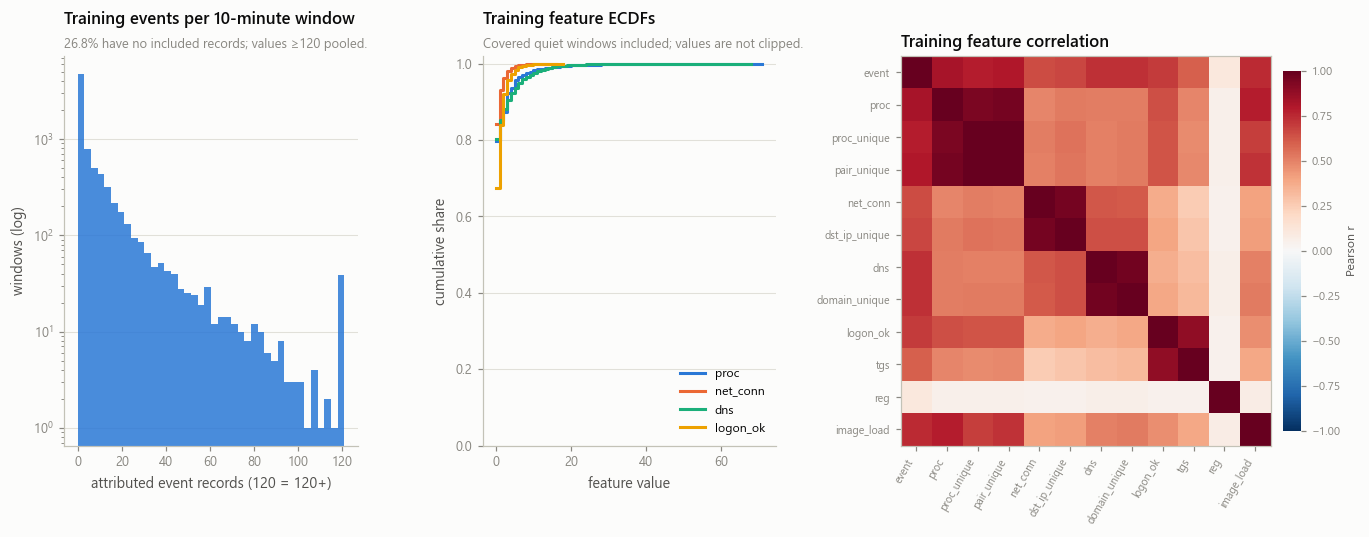

In [26]:

#cell23
if Wtr.empty:
    raise ValueError("Run Cell 22 with a nonempty training population first.")

fig = plt.figure(figsize=(14.5, 4.6))
gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1.1, 1.1, 1.5],
    wspace=0.38,
)

# ---- activity distribution -----------------------------------------------------
ax = fig.add_subplot(gs[0, 0])

empty_share = float(Wtr["event_count"].eq(0).mean())
activity_cap = 120

activity = Wtr["event_count"].clip(upper=activity_cap)
ax.hist(
    activity,
    bins=np.linspace(0, activity_cap + 1, 41),
    color=CAT[0],
    alpha=0.85,
)
ax.set_yscale("log")

finish(
    ax,
    "Training events per 10-minute window",
    f"{empty_share:.1%} have no included records; values ≥120 pooled.",
    xlabel="attributed event records (120 = 120+)",
    ylabel="windows (log)",
)

# ---- empirical CDFs ------------------------------------------------------------
ax = fig.add_subplot(gs[0, 1])

show = [
    feature for feature in
    ["proc_count", "net_conn_count", "dns_count", "logon_ok_count"]
    if feature in Wtr.columns
]

for i, feature in enumerate(show):
    # True ECDF: aggregate ties; no misleading linear line through repeated zeros.
    frequencies = Wtr[feature].value_counts().sort_index()
    x = frequencies.index.to_numpy(dtype=float)
    y = frequencies.cumsum().to_numpy(dtype=float) / len(Wtr)

    ax.step(
        x, y,
        where="post",
        color=CAT[i % len(CAT)],
        label=feature.replace("_count", ""),
    )

finish(
    ax,
    "Training feature ECDFs",
    "Covered quiet windows included; values are not clipped.",
    xlabel="feature value",
    ylabel="cumulative share",
)
ax.set_ylim(0, 1.02)
if show:
    ax.legend(loc="lower right", fontsize=8)

# ---- signed correlation heatmap ------------------------------------------------
ax = fig.add_subplot(gs[0, 2])

requested = [
    "event_count", "proc_count", "proc_unique", "pair_unique",
    "net_conn_count", "dst_ip_unique", "dns_count", "domain_unique",
    "logon_ok_count", "tgs_count", "reg_count", "image_load_count",
]
selected = [
    feature for feature in requested
    if feature in Wtr.columns and Wtr[feature].nunique() > 1
]

if len(selected) >= 2:
    correlation = Wtr[selected].corr()
    matrix = np.ma.masked_invalid(correlation.to_numpy(dtype=float))

    cmap = plt.get_cmap("RdBu_r").copy()
    cmap.set_bad("#dddddd")

    im = ax.imshow(
        matrix, cmap=cmap, vmin=-1, vmax=1, aspect="auto"
    )
    labels = [feature.replace("_count", "") for feature in selected]

    ax.set_xticks(range(len(selected)))
    ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(len(selected)))
    ax.set_yticklabels(labels, fontsize=7)
    ax.grid(False)

    cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03)
    cb.outline.set_visible(False)
    cb.set_label("Pearson r", fontsize=8)
    cb.ax.tick_params(labelsize=7.5)
else:
    ax.text(
        0.5, 0.5,
        "Insufficient nonconstant features",
        transform=ax.transAxes,
        ha="center", va="center",
    )
    ax.set_xticks([])
    ax.set_yticks([])

ax.set_title(
    "Training feature correlation",
    loc="left", color=INK, fontsize=11,
)

plt.show()

In [27]:
# cell25Aggregate only a narrow diagnostic table.
split_audit = W[
    ["date", "is_train", "is_test", "has_telemetry", "coverage_state"]
].copy()

print(f"Total principal/window rows: {len(W):,}")
print(f"Distinct principals        : {W['user'].nunique():,}")
print(f"Distinct UTC windows       : {W['win'].nunique():,}")
print(f"Coverage policy            : {COVERAGE_POLICY}")

split_summary = pd.DataFrame([
    {
        "split": label,
        "grid_rows": int(W[flag].sum()),
        "eligible_rows": int((W[flag] & W["has_telemetry"]).sum()),
        "unavailable_rows": int((W[flag] & ~W["has_telemetry"]).sum()),
        "eligible_user_days": (
            (W[flag] & W["has_telemetry"]).sum() / WINDOWS_PER_DAY
        ),
    }
    for label, flag in [("training", "is_train"), ("testing", "is_test")]
]).set_index("split")

assert int(split_summary["grid_rows"].sum()) == len(W)
assert (
    split_summary["eligible_rows"] + split_summary["unavailable_rows"]
).eq(split_summary["grid_rows"]).all()

print("\nSplit summary:")
display(split_summary.round({"eligible_user_days": 3}))

daily_audit = (
    split_audit.groupby("date", observed=True)
    .agg(
        grid_rows=("is_train", "size"),
        training_rows=("is_train", "sum"),
        testing_rows=("is_test", "sum"),
        eligible_rows=("has_telemetry", "sum"),
    )
    .reindex(ALL_DATES, fill_value=0)
)
daily_audit["unavailable_rows"] = (
    daily_audit["grid_rows"] - daily_audit["eligible_rows"]
)
daily_audit["split"] = [
    "training" if day in TRAIN_DATES else "testing"
    for day in daily_audit.index
]

expected_daily_rows = len(PRINCIPALS) * WINDOWS_PER_DAY
assert daily_audit["grid_rows"].eq(expected_daily_rows).all(), (
    "Incomplete configured principal/window grid."
)
assert (
    daily_audit["training_rows"] + daily_audit["testing_rows"]
).eq(daily_audit["grid_rows"]).all()

print("\nUTC date-wise grid and coverage eligibility:")
display(daily_audit)

print("\nCoverage-state counts:")
display(
    split_audit.groupby(
        ["date", "coverage_state"], observed=True, dropna=False
    )
    .size()
    .rename("principal_window_rows")
    .reset_index()
)

print(
    "Eligible user-days are exposure equivalents: eligible principal/window "
    "rows divided by 144. They are not a count of distinct calendar days, "
    "and assumed synthetic coverage remains an assumption."
)

del split_audit

Total principal/window rows: 34,560
Distinct principals        : 8
Distinct UTC windows       : 4,320
Coverage policy            : explicit_assumption_continuous_synthetic_envelope

Split summary:


,grid_rows,eligible_rows,unavailable_rows,eligible_user_days
split,,,,
training,8064,8064,0,56.0
testing,26496,26496,0,184.0



UTC date-wise grid and coverage eligibility:


,grid_rows,training_rows,testing_rows,eligible_rows,unavailable_rows,split
date,,,,,,
2026-07-28,1152,1152,0,1152,0,training
2026-07-29,1152,1152,0,1152,0,training
2026-07-30,1152,1152,0,1152,0,training
2026-07-31,1152,1152,0,1152,0,training
2026-08-01,1152,1152,0,1152,0,training
2026-08-02,1152,1152,0,1152,0,training
2026-08-03,1152,1152,0,1152,0,training
2026-08-04,1152,0,1152,1152,0,testing
2026-08-05,1152,0,1152,1152,0,testing



Coverage-state counts:


,date,coverage_state,principal_window_rows
0,2026-07-28,assumed_continuous_synthetic,1152
1,2026-07-29,assumed_continuous_synthetic,1152
2,2026-07-30,assumed_continuous_synthetic,1152
3,2026-07-31,assumed_continuous_synthetic,1152
4,2026-08-01,assumed_continuous_synthetic,1152
5,2026-08-02,assumed_continuous_synthetic,1152
6,2026-08-03,assumed_continuous_synthetic,1152
7,2026-08-04,assumed_continuous_synthetic,1152
8,2026-08-05,assumed_continuous_synthetic,1152
9,2026-08-06,assumed_continuous_synthetic,1152


Eligible user-days are exposure equivalents: eligible principal/window rows divided by 144. They are not a count of distinct calendar days, and assumed synthetic coverage remains an assumption.


In [28]:
if raw.empty:
    raise ValueError("No events are loaded.")

timestamps = raw["timestamp"]

if not isinstance(timestamps.dtype, pd.DatetimeTZDtype):
    raise TypeError("Event timestamps must be timezone-aware.")
if timestamps.isna().any():
    raise ValueError("Event timestamps contain missing values.")

print("Actual event range (UTC):")
print("  first:", timestamps.min().tz_convert("UTC"))
print("  last :", timestamps.max().tz_convert("UTC"))

# Operate on one Series—not raw.assign(), which can copy the wide event table.
event_dates_utc = (
    timestamps.dt.tz_convert(SPLIT_TZ).dt.strftime("%Y-%m-%d")
)
actual_daily_counts = (
    event_dates_utc.value_counts()
    .sort_index()
    .rename("observed_records")
)

assert int(actual_daily_counts.sum()) == len(raw)

outside_dates = sorted(set(actual_daily_counts.index) - set(ALL_DATES))
if outside_dates:
    raise ValueError(
        f"Observed events outside the configured split: {outside_dates}"
    )

actual_daily_counts = actual_daily_counts.reindex(
    ALL_DATES, fill_value=0
).astype("int64")

daily_event_audit = actual_daily_counts.to_frame()
daily_event_audit["split"] = [
    "training" if day in TRAIN_DATES else "testing"
    for day in daily_event_audit.index
]
daily_event_audit.index.name = "utc_date"

display(daily_event_audit)

print(
    "These are counts of source records before principal scoping. "
    "Zero observed records do not establish verified sensor downtime or inactivity."
)

del event_dates_utc

Actual event range (UTC):
  first: 2026-07-28 00:00:23.971389+00:00
  last : 2026-08-26 23:59:41.108442+00:00


,observed_records,split
utc_date,,
2026-07-28,88387,training
2026-07-29,82255,training
2026-07-30,87854,training
2026-07-31,80219,training
2026-08-01,57371,training
2026-08-02,57690,training
2026-08-03,83483,training
2026-08-04,86138,testing
2026-08-05,83866,testing


These are counts of source records before principal scoping. Zero observed records do not establish verified sensor downtime or inactivity.


In [29]:
# ---- configured populations ----------------------------------------------------
# W is the small aggregated window table, not the multi-million-row raw table.
# Preserve its index and wid for later debug-array alignment.

TRAIN_GRID = W.loc[W["is_train"]].copy()
TEST_GRID = W.loc[W["is_test"]].copy()

TRAIN_W = TRAIN_GRID.loc[TRAIN_GRID["has_telemetry"]].copy()
TEST_W = TEST_GRID.loc[TEST_GRID["has_telemetry"]].copy()

if TRAIN_GRID.empty or TEST_GRID.empty:
    raise ValueError("A configured train/test grid is empty.")

if TRAIN_W.empty:
    raise ValueError(
        "No coverage-eligible training windows. Resolve coverage policy first."
    )
if TEST_W.empty:
    raise ValueError(
        "No coverage-eligible testing windows. Resolve coverage policy first."
    )

# ---- split invariants ----------------------------------------------------------
assert set(TRAIN_DATES).isdisjoint(TEST_DATES)

assert TRAIN_GRID["date"].isin(TRAIN_DATES).all()
assert TEST_GRID["date"].isin(TEST_DATES).all()
assert TRAIN_W["date"].isin(TRAIN_DATES).all()
assert TEST_W["date"].isin(TEST_DATES).all()

assert len(TRAIN_GRID) + len(TEST_GRID) == len(W)
assert not set(TRAIN_GRID["wid"]).intersection(TEST_GRID["wid"])

for label, frame in [
    ("TRAIN_GRID", TRAIN_GRID),
    ("TEST_GRID", TEST_GRID),
    ("TRAIN_W", TRAIN_W),
    ("TEST_W", TEST_W),
]:
    assert frame["wid"].is_unique, f"Duplicate wid in {label}"
    assert not frame.duplicated(["user", "win"]).any(), (
        f"Duplicate principal/window key in {label}"
    )
    assert frame.index.equals(W.loc[frame.index].index)
    assert frame["wid"].equals(W.loc[frame.index, "wid"])

# Exclusive interval boundaries—not a hard-coded last window time.
train_start = pd.Timestamp(min(TRAIN_DATES), tz=SPLIT_TZ)
train_end_exclusive = (
    pd.Timestamp(max(TRAIN_DATES), tz=SPLIT_TZ)
    + pd.Timedelta(days=1)
)
test_start = pd.Timestamp(min(TEST_DATES), tz=SPLIT_TZ)
test_end_exclusive = (
    pd.Timestamp(max(TEST_DATES), tz=SPLIT_TZ)
    + pd.Timedelta(days=1)
)

assert train_end_exclusive <= test_start
assert TRAIN_GRID["win"].ge(train_start).all()
assert TRAIN_GRID["win"].lt(train_end_exclusive).all()
assert TEST_GRID["win"].ge(test_start).all()
assert TEST_GRID["win"].lt(test_end_exclusive).all()

# ---- feature validity ----------------------------------------------------------
for label, frame in [("TRAIN_W", TRAIN_W), ("TEST_W", TEST_W)]:
    values = frame[FEATS].to_numpy(dtype="float64")

    if not np.isfinite(values).all():
        raise ValueError(f"{label} contains missing/nonfinite eligible features.")
    if (values < 0).any():
        raise ValueError(f"{label} contains negative feature counts.")
    if not np.equal(values, np.floor(values)).all():
        raise ValueError(f"{label} contains noninteger count features.")

    del values

# Unavailable windows must remain unavailable—not zero-filled behavioral evidence.
assert TRAIN_GRID.loc[
    ~TRAIN_GRID["has_telemetry"], FEATS
].isna().all().all()

assert TEST_GRID.loc[
    ~TEST_GRID["has_telemetry"], FEATS
].isna().all().all()

# ---- reconcile source-event exposure -------------------------------------------
event_coverage = (
    ev["win"]
    .map(WINDOW_COVERAGE.set_index("win")["has_telemetry"])
)
if event_coverage.isna().any():
    raise ValueError("Event windows missing from coverage lookup.")

event_coverage = event_coverage.astype(bool)

expected_train_events = int(
    (ev["date"].isin(TRAIN_DATES) & event_coverage).sum()
)
expected_test_events = int(
    (ev["date"].isin(TEST_DATES) & event_coverage).sum()
)

assert int(TRAIN_W["event_count"].sum()) == expected_train_events
assert int(TEST_W["event_count"].sum()) == expected_test_events

print(f"Configured training: [{train_start}, {train_end_exclusive})")
print(f"Configured testing : [{test_start}, {test_end_exclusive})")
print(f"Behavioral context : {BEHAVIOR_TZ}")
print(f"Coverage policy    : {COVERAGE_POLICY}")

split_population = pd.DataFrame([
    {
        "split": "training",
        "grid_windows": len(TRAIN_GRID),
        "eligible_windows": len(TRAIN_W),
        "unavailable_windows": len(TRAIN_GRID) - len(TRAIN_W),
        "included_event_records": int(TRAIN_W["event_count"].sum()),
        "eligible_user_days": len(TRAIN_W) / WINDOWS_PER_DAY,
    },
    {
        "split": "testing",
        "grid_windows": len(TEST_GRID),
        "eligible_windows": len(TEST_W),
        "unavailable_windows": len(TEST_GRID) - len(TEST_W),
        "included_event_records": int(TEST_W["event_count"].sum()),
        "eligible_user_days": len(TEST_W) / WINDOWS_PER_DAY,
    },
]).set_index("split")

display(split_population.round({"eligible_user_days": 3}))

# ---- training support, including covered quiet windows --------------------------
cell_support = (
    TRAIN_W[
        ["user", "hour", "behavior_date", "win", "event_count"]
    ]
    .groupby(["user", "hour"], observed=True)
    .agg(
        n_obs=("win", "size"),
        n_behavior_days=("behavior_date", "nunique"),
        observed_events=("event_count", "sum"),
    )
)

all_hour_cells = pd.MultiIndex.from_product(
    [PRINCIPALS, range(24)],
    names=["user", "hour"],
)
cell_support = cell_support.reindex(all_hour_cells, fill_value=0)

cell_support["supported"] = (
    cell_support["n_obs"].ge(MIN_CELL_WINDOWS)
    & cell_support["n_behavior_days"].ge(MIN_CELL_DAYS)
)
cell_support["observed_quiet"] = (
    cell_support["n_obs"].gt(0)
    & cell_support["observed_events"].eq(0)
)

print("\nTraining user × IST-hour support:")
display(
    cell_support.groupby(level="user").agg(
        supported_hours=("supported", "sum"),
        observed_quiet_hours=("observed_quiet", "sum"),
        minimum_hour_observations=("n_obs", "min"),
        maximum_hour_observations=("n_obs", "max"),
    )
)

print(
    "Covered quiet windows remain in training. An hour without observations "
    "is not a historically quiet hour. Baseline support will be recomputed "
    "inside each calibration fold."
)

del event_coverage

Configured training: [2026-07-28 00:00:00+00:00, 2026-08-04 00:00:00+00:00)
Configured testing : [2026-08-04 00:00:00+00:00, 2026-08-27 00:00:00+00:00)
Behavioral context : Asia/Kolkata
Coverage policy    : explicit_assumption_continuous_synthetic_envelope


,grid_windows,eligible_windows,unavailable_windows,included_event_records,eligible_user_days
split,,,,,
training,8064,8064,0,68757,56.0
testing,26496,26496,0,297577,184.0



Training user × IST-hour support:


,supported_hours,observed_quiet_hours,minimum_hour_observations,maximum_hour_observations
user,,,,
corp\aarav.malhotra,24,0,42,42
corp\aditya.saxena,24,0,42,42
corp\diya.singh,24,0,42,42
corp\ishita.kapoor,24,0,42,42
corp\kabir.chauhan,24,0,42,42
corp\meera.bansal,24,0,42,42
corp\prerna.verma,24,0,42,42
corp\vivaan.sharma,24,0,42,42


Covered quiet windows remain in training. An hour without observations is not a historically quiet hour. Baseline support will be recomputed inside each calibration fold.


In [30]:
#cell28 ---- fixed feature definitions -------------------------------------------------
# Do not select features using full-training density before cross-validation.
STAT_FEATURES = [
    feature for feature in STAT_CANDIDATE_FEATURES
    if feature not in DIAGNOSTIC_FEATURES
]

if not STAT_FEATURES:
    raise ValueError("No statistical candidate features.")

ACT_WEIGHTS = {
    "encoded_count": 2.0,
    "hidden_ps_count": 0.8,
    "scripthost_count": 1.5,
    "discovery_count": 1.2,
    "lolbin_count": 1.2,
    "admin_count": 1.2,
    "transfer_count": 1.0,
    "temp_proc_count": 1.5,
    "remoteexec_count": 0.8,
    "lsass_acc_count": 1.5,
    "lsass_hi_count": 2.5,
    "rthread_ext_count": 2.5,       # now explicitly LSASS-target remote threads
    "remote_thread_count": 1.0,
    "exe_create_count": 1.0,
    "script_create_count": 1.2,
    "archive_create_count": 1.2,
    "temp_create_count": 1.0,
    "run_key_count": 1.5,
    "svc_key_count": 1.0,
    "acct_mgmt_count": 2.5,
    "group_mgmt_count": 2.5,
    "svc_install_count": 2.5,
    "task_count": 2.0,
    "logclear_count": 3.0,
    "explicit_count": 1.2,
    "ext_src_count": 2.0,
    "ext_fail_count": 2.5,
    "sens_port_count": 0.8,
    "srv_lookup_count": 0.5,
    "dns_fail_count": 0.5,
    "krb_fail_count": 0.8,
    "ntlm_fail_count": 0.8,
    "lt10_count": 0.8,
    "lt2_count": 0.6,
    "script_net_count": 0.8,
    "script_ext_net_count": 1.5,
    "script_sens_port_count": 1.5,
    "remote_spawn_count": 1.5,
}

missing_activation = sorted(set(ACT_WEIGHTS) - set(FEATS))
if missing_activation:
    raise ValueError(f"Activation features missing: {missing_activation}")

ACT_FEATURES = list(ACT_WEIGHTS)
assert not set(ACT_FEATURES).intersection(DIAGNOSTIC_FEATURES)
assert all(np.isfinite(weight) and weight > 0 for weight in ACT_WEIGHTS.values())

# Validated event families already incorporate channel/provider checks.
EID_KEY = ["event_family", "EventID"]

# Explicit index preservation is required by later scoring/debug arrays.
LOGW = pd.DataFrame(
    np.log1p(W[STAT_FEATURES].to_numpy(dtype="float64")),
    index=W.index,
    columns=STAT_FEATURES,
)
for column in ("user", "hour", "date"):
    LOGW[column] = W[column]
LOGW["has_tel"] = W["has_telemetry"]

assert LOGW.index.equals(W.index)


# ---- common fold population ----------------------------------------------------
def validate_fit_dates(train_dates):
    dates = list(train_dates)

    if not dates or len(dates) != len(set(dates)):
        raise ValueError("Fit dates must be nonempty and unique.")

    dates = sorted(dates)
    if not set(dates).issubset(TRAIN_DATES):
        raise ValueError(
            "Baseline fitting is restricted to configured TRAIN_DATES."
        )
    return dates


def make_fit_context(train_dates):
    dates = validate_fit_dates(train_dates)

    columns = list(dict.fromkeys(
        [
            "user", "win", "date", "hour", "behavior_date",
            "day_type", "event_count",
        ]
        + STAT_FEATURES
        + ACT_FEATURES
    ))

    t = W.loc[
        W["date"].isin(dates) & W["has_telemetry"],
        columns,
    ].copy()

    if t.empty:
        raise ValueError(f"No eligible windows for fit dates {dates}.")

    users = pd.Index(PRINCIPALS, name="user")

    support = (
        t.groupby("user", observed=True)
        .agg(
            n_windows=("win", "size"),
            train_events=("event_count", "sum"),
        )
        .reindex(users, fill_value=0)
    )

    # Active UTC training dates—not an assumption that every covered day was active.
    active_days = (
        t.loc[t["event_count"].gt(0)]
        .groupby("user", observed=True)["date"]
        .nunique()
        .reindex(users, fill_value=0)
    )
    support["active_train_days"] = active_days
    support["eligible"] = (
        support["train_events"].ge(MIN_TRAIN_EVENTS)
        & support["active_train_days"].ge(MIN_TRAIN_DAYS)
    )

    eligible_users = support.index[support["eligible"]].tolist()
    if not eligible_users:
        raise ValueError(
            f"No principals meet support requirements in fit dates {dates}."
        )

    # All components use precisely these users and covered windows.
    t = t.loc[t["user"].isin(eligible_users)].copy()

    values = t[STAT_FEATURES].to_numpy(dtype=float)
    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError("Invalid feature values in eligible fitting windows.")

    return {
        "dates": dates,
        "windows": t,
        "user_support": support,
        "eligible_users": eligible_users,
        "window_keys": pd.MultiIndex.from_frame(t[["user", "win"]]),
    }


def _context(train_dates, context):
    dates = validate_fit_dates(train_dates)
    if context is None:
        return make_fit_context(dates)
    if context["dates"] != dates:
        raise ValueError("Fit context dates do not match requested dates.")
    return context


# ---- numeric baseline ----------------------------------------------------------
def fit_numeric_baseline(train_dates, context=None):
    ctx = _context(train_dates, context)
    t = ctx["windows"]

    x = np.log1p(t[STAT_FEATURES].astype("float64"))
    numeric = pd.concat(
        [t[["user", "hour", "behavior_date"]], x], axis=1
    )

    gh = numeric.groupby(["user", "hour"], observed=True, sort=False)
    gu = numeric.groupby("user", observed=True, sort=False)

    med_h = gh[STAT_FEATURES].median()
    med_u = gu[STAT_FEATURES].median()

    # transform preserves row alignment, including repeated user/hour keys.
    hourly_deviation = (
        x - gh[STAT_FEATURES].transform("median")
    ).abs()
    user_deviation = (
        x - gu[STAT_FEATURES].transform("median")
    ).abs()

    mad_h = hourly_deviation.groupby(
        [numeric["user"], numeric["hour"]],
        observed=True, sort=False,
    ).median()
    mad_u = user_deviation.groupby(
        numeric["user"], observed=True, sort=False
    ).median()

    cells = pd.MultiIndex.from_product(
        [PRINCIPALS, range(24)], names=["user", "hour"]
    )
    users = pd.Index(PRINCIPALS, name="user")

    n = gh.size().reindex(cells, fill_value=0).rename("n_obs")
    n_days = (
        gh["behavior_date"].nunique()
        .reindex(cells, fill_value=0)
        .rename("n_behavior_days")
    )
    supported = (
        n.ge(MIN_CELL_WINDOWS)
        & n_days.ge(MIN_CELL_DAYS)
    ).rename("supported")

    result = {
        "med_h": med_h.reindex(cells),
        "mad_h": mad_h.reindex(cells),
        "med_u": med_u.reindex(users),
        "mad_u": mad_u.reindex(users),
        "n": n,
        "n_days": n_days,
        "supported": supported,
        "user_supported": ctx["user_support"]["eligible"].copy(),
    }

    for name, quantile in [
        ("p05_h", 0.05), ("p25_h", 0.25),
        ("p75_h", 0.75), ("p95_h", 0.95),
    ]:
        result[name] = gh[STAT_FEATURES].quantile(quantile).reindex(cells)

    result["max_h"] = gh[STAT_FEATURES].max().reindex(cells)

    # Retain observed descriptive statistics, but mark eligibility separately.
    # The scorer MUST use supported/user_supported and must not nan_to_num them.
    return result


# ---- categorical inventories ---------------------------------------------------
def fit_inventories(train_dates, context=None):
    ctx = _context(train_dates, context)

    item_keys = pd.MultiIndex.from_frame(ITEMS[["user", "win"]])
    mask = (
        ITEMS["date"].isin(ctx["dates"])
        & item_keys.isin(ctx["window_keys"])
    )
    tr = ITEMS.loc[
        mask, ["user", "itype", "value", "gvalue"]
    ]

    known = tr[["user", "itype", "value"]].drop_duplicates().copy()
    known["known"] = True

    # Frequency unit: one deduplicated user/window/value observation.
    # User-directory normalization can merge multiple values into one global key.
    gcnt = (
        tr.groupby(["itype", "gvalue"], observed=True, sort=False)
        .size()
        .rename("gcnt")
        .reset_index()
    )

    assert not known.duplicated(["user", "itype", "value"]).any()
    assert not gcnt.duplicated(["itype", "gvalue"]).any()
    return known, gcnt


# ---- event-type rarity ---------------------------------------------------------
def fit_eid_rarity(train_dates, context=None):
    ctx = _context(train_dates, context)

    event_keys = pd.MultiIndex.from_frame(ev[["user", "win"]])
    mask = (
        ev["date"].isin(ctx["dates"])
        & event_keys.isin(ctx["window_keys"])
    )
    tr = ev.loc[mask, ["user"] + EID_KEY]

    ucnt = (
        tr.groupby(["user"] + EID_KEY, observed=True, sort=False)
        .size().rename("ucnt").reset_index()
    )
    utot = (
        tr.groupby("user", observed=True, sort=False)
        .size().rename("utot").reset_index()
    )
    gcnt = (
        tr.groupby(EID_KEY, observed=True, sort=False)
        .size().rename("gcnt").reset_index()
    )

    total = len(tr)
    assert int(utot["utot"].sum()) == total
    assert int(gcnt["gcnt"].sum()) == total
    assert total == int(ctx["windows"]["event_count"].sum())

    return ucnt, utot, gcnt, total


# ---- capability activation -----------------------------------------------------
def fit_activation(train_dates, context=None):
    ctx = _context(train_dates, context)

    maxima = (
        ctx["windows"]
        .groupby("user", observed=True)[ACT_FEATURES]
        .max()
        .reindex(pd.Index(PRINCIPALS, name="user"))
    )

    # Unsupported users remain NaN—not historically zero.
    return maxima


# ---- temporal activity profile -------------------------------------------------
def fit_temporal_profile(train_dates, alpha=None, context=None):
    ctx = _context(train_dates, context)
    alpha = TEMP_ALPHA if alpha is None else float(alpha)

    if not np.isfinite(alpha) or alpha <= 0:
        raise ValueError("Temporal smoothing alpha must be finite and positive.")

    t = ctx["windows"][
        ["user", "day_type", "hour", "event_count"]
    ].copy()
    t["active"] = t["event_count"].gt(0).astype("float64")

    user_prior = (
        t.groupby("user", observed=True)["active"]
        .mean()
        .rename("prior")
    )
    profile = (
        t.groupby(["user", "day_type", "hour"], observed=True)
        .agg(
            active_windows=("active", "sum"),
            n_windows=("active", "size"),
        )
        .reset_index()
        .merge(
            user_prior.reset_index(),
            on="user", how="left", validate="many_to_one",
        )
    )

    profile["p_active"] = (
        (
            profile["active_windows"] + alpha * profile["prior"]
        )
        / (profile["n_windows"] + alpha)
    ).clip(0, 1)

    profile.attrs["train_dates"] = ctx["dates"]
    profile.attrs["alpha"] = alpha
    profile.attrs["behavior_timezone"] = BEHAVIOR_TZ

    return profile


# ---- complete fitted artifact --------------------------------------------------
def fit_baseline(train_dates):
    ctx = make_fit_context(train_dates)

    known, gcnt = fit_inventories(ctx["dates"], ctx)
    ucnt, utot, eid_gcnt, eid_total = fit_eid_rarity(ctx["dates"], ctx)
    temporal = fit_temporal_profile(ctx["dates"], context=ctx)

    fit_metadata = {
        "train_dates": ctx["dates"],
        "behavior_timezone": BEHAVIOR_TZ,
        "split_timezone": SPLIT_TZ,
        "window": WINDOW,
        "coverage_policy": COVERAGE_POLICY,
        "stat_features": STAT_FEATURES,
        "activation_weights": ACT_WEIGHTS,
        "min_train_events": MIN_TRAIN_EVENTS,
        "min_train_days": MIN_TRAIN_DAYS,
        "min_cell_windows": MIN_CELL_WINDOWS,
        "min_cell_days": MIN_CELL_DAYS,
        "source_sha256": raw.attrs.get(
            "ingest_manifest", {}
        ).get("source_sha256"),
    }
    fit_id = hashlib.sha256(
        json.dumps(fit_metadata, sort_keys=True).encode("utf-8")
    ).hexdigest()[:16]

    return {
        "num": fit_numeric_baseline(ctx["dates"], ctx),
        "known": known,
        "gcnt": gcnt,
        "eid_ucnt": ucnt,
        "eid_utot": utot,
        "eid_gcnt": eid_gcnt,
        "eid_gtot": eid_total,
        "act_max": fit_activation(ctx["dates"], ctx),
        "temp_profile": temporal,
        "user_support": ctx["user_support"],
        "eligible_users": ctx["eligible_users"],
        "train_dates": ctx["dates"],
        "metadata": fit_metadata,
        "fit_id": fit_id,
    }


BASELINE = fit_baseline(TRAIN_DATES)

# Reporting alias only. Scoring must use the profile inside its supplied baseline.
TEMP_PROFILE = BASELINE["temp_profile"]

print(f"Baseline fit ID: {BASELINE['fit_id']}")
print(f"Training dates: {BASELINE['train_dates']}")
print(f"Eligible principals in this fit: {len(BASELINE['eligible_users'])}")
print(f"Numeric features: {len(STAT_FEATURES)}")
print(
    "Supported user/hour cells: "
    f"{int(BASELINE['num']['supported'].sum())} / "
    f"{len(BASELINE['num']['supported'])}"
)
print(f"Known user/dimension/value entries: {len(BASELINE['known']):,}")
print(f"Global-reference item keys: {len(BASELINE['gcnt']):,}")
print(f"Reference event records: {BASELINE['eid_gtot']:,}")

display(BASELINE["user_support"])

print(
    "Capability activation means absent from this fitted user's baseline, "
    "not unusual-hour activity. Temporal context is a separate component. "
    "Global frequencies describe eligible scoped principals—not the whole estate."
)

Baseline fit ID: 1a48ba3a54b0e8d7
Training dates: ['2026-07-28', '2026-07-29', '2026-07-30', '2026-07-31', '2026-08-01', '2026-08-02', '2026-08-03']
Eligible principals in this fit: 8
Numeric features: 74
Supported user/hour cells: 192 / 192
Known user/dimension/value entries: 2,490
Global-reference item keys: 739
Reference event records: 68,757


,n_windows,train_events,active_train_days,eligible
user,,,,
corp\aarav.malhotra,1008,7234.0,7,True
corp\aditya.saxena,1008,12056.0,7,True
corp\diya.singh,1008,12237.0,7,True
corp\ishita.kapoor,1008,6031.0,7,True
corp\kabir.chauhan,1008,9474.0,7,True
corp\meera.bansal,1008,5714.0,7,True
corp\prerna.verma,1008,6954.0,7,True
corp\vivaan.sharma,1008,9057.0,7,True


Capability activation means absent from this fitted user's baseline, not unusual-hour activity. Temporal context is a separate component. Global frequencies describe eligible scoped principals—not the whole estate.


In [31]:
profile = BASELINE["temp_profile"]
#cell29
assert profile.attrs.get("train_dates") == BASELINE["train_dates"]
assert not profile.duplicated(["user", "day_type", "hour"]).any()
assert profile["p_active"].between(0, 1).all()
assert profile["n_windows"].gt(0).all()

print("Temporal activity profile")
print("P(active | user, local day type, local hour)")
print(f"Behavioral timezone: {BEHAVIOR_TZ}")
print(f"Fit dates: {BASELINE['train_dates']}")
print(f"Smoothing alpha: {profile.attrs['alpha']}")
print(f"Observed user/day-type/hour cells: {len(profile):,}")

display(
    profile.sort_values(
        ["user", "day_type", "hour"], kind="stable"
    ).head(40).style.format({
        "prior": "{:.3f}",
        "p_active": "{:.3f}",
        "active_windows": "{:.0f}",
        "n_windows": "{:.0f}",
    })
)

print(
    "This is a smoothed descriptive activity rate, not a probability of attack. "
    "Unobserved contexts are not inserted as zero-activity contexts. "
    "The scorer will use the supported user's prior where appropriate, "
    "and leave unsupported users unrated."
)

Temporal activity profile
P(active | user, local day type, local hour)
Behavioral timezone: Asia/Kolkata
Fit dates: ['2026-07-28', '2026-07-29', '2026-07-30', '2026-07-31', '2026-08-01', '2026-08-02', '2026-08-03']
Smoothing alpha: 4.0
Observed user/day-type/hour cells: 384


,user,day_type,hour,active_windows,n_windows,prior,p_active
0,corp\aarav.malhotra,weekday,0,23,30,0.660,0.754
1,corp\aarav.malhotra,weekday,1,19,30,0.660,0.636
2,corp\aarav.malhotra,weekday,2,16,30,0.660,0.548
3,corp\aarav.malhotra,weekday,3,10,30,0.660,0.372
4,corp\aarav.malhotra,weekday,4,13,30,0.660,0.460
5,corp\aarav.malhotra,weekday,5,10,30,0.660,0.372
6,corp\aarav.malhotra,weekday,6,14,30,0.660,0.489
7,corp\aarav.malhotra,weekday,7,13,30,0.660,0.460
8,corp\aarav.malhotra,weekday,8,19,30,0.660,0.636
9,corp\aarav.malhotra,weekday,9,15,30,0.660,0.519


This is a smoothed descriptive activity rate, not a probability of attack. Unobserved contexts are not inserted as zero-activity contexts. The scorer will use the supported user's prior where appropriate, and leave unsupported users unrated.


In [32]:
#cell30
# ---- fitted-baseline prerequisites ---------------------------------------------
num = BASELINE["num"]

if BASELINE["train_dates"] != sorted(TRAIN_DATES):
    raise ValueError("BASELINE does not match the configured full training dates.")

cell_index = num["med_h"].index
expected_rows = len(cell_index) * len(STAT_FEATURES)

# melt preserves missing statistics explicitly, including unsupported users.
# Do not use stack()'s default behavior, which can drop missing cells.
stat_frames = {
    "median": num["med_h"],
    "mad": num["mad_h"],          # raw MAD in log1p space
    "p05": num["p05_h"],
    "p25": num["p25_h"],
    "p75": num["p75_h"],
    "p95": num["p95_h"],
    "max": num["max_h"],
}

BASELINE_TABLE = None
table_keys = ["user", "hour", "feature"]

for stat, frame in stat_frames.items():
    aligned = frame.reindex(
        index=cell_index,
        columns=STAT_FEATURES,
    )
    long_frame = (
        aligned.reset_index()
        .melt(
            id_vars=["user", "hour"],
            value_vars=STAT_FEATURES,
            var_name="feature",
            value_name=stat,
        )
    )

    if BASELINE_TABLE is None:
        BASELINE_TABLE = long_frame
    else:
        BASELINE_TABLE = BASELINE_TABLE.merge(
            long_frame,
            on=table_keys,
            how="outer",
            validate="one_to_one",
        )

# Use this fit's support—not the external full-grid `obs` table.
support_table = pd.concat(
    [
        num["n"].rename("n_obs"),
        num["n_days"].rename("n_behavior_days"),
        num["supported"].rename("supported"),
    ],
    axis=1,
).reset_index()

BASELINE_TABLE = BASELINE_TABLE.merge(
    support_table,
    on=["user", "hour"],
    how="left",
    validate="many_to_one",
)

assert len(BASELINE_TABLE) == expected_rows
assert not BASELINE_TABLE.duplicated(table_keys).any()
assert BASELINE_TABLE["supported"].notna().all()

# Inverse-transform model summaries for readability.
# Do not round stored data; round only the displayed table.
for stat in ("median", "p05", "p25", "p75", "p95", "max"):
    BASELINE_TABLE[stat + "_events"] = np.expm1(BASELINE_TABLE[stat])

BASELINE_TABLE["fit_id"] = BASELINE["fit_id"]

print(f"Baseline table: {len(BASELINE_TABLE):,} rows")
print(f"Fit ID: {BASELINE['fit_id']}")
print(f"Behavioral hours: {BEHAVIOR_TZ}")
print(
    "mad is unscaled MAD in log1p space. The scorer applies scaling and "
    "the floor. Inverse-transformed interpolated quantiles/medians need not "
    "equal summaries calculated directly in raw-count space."
)

example_features = [
    feature for feature in [
        "event_count", "proc_count", "proc_unique",
        "logon_ok_count", "net_conn_count", "dns_count",
    ]
    if feature in STAT_FEATURES
]

print(f"\nExample: {EXAMPLE_USER}, hour 21 ({BEHAVIOR_TZ})")
display(
    BASELINE_TABLE.loc[
        BASELINE_TABLE["user"].eq(EXAMPLE_USER)
        & BASELINE_TABLE["hour"].eq(21)
        & BASELINE_TABLE["feature"].isin(example_features),
        [
            "user", "hour", "feature", "n_obs",
            "n_behavior_days", "supported",
            "median_events", "p75_events", "p95_events", "max_events", "mad",
        ],
    ].round(3)
)

# ---- inventory sizes from the fitted artifact ----------------------------------
inventory_types = [item_type for item_type, _, _ in ITEM_DEF]

if BASELINE["known"].empty:
    inv_sizes = pd.DataFrame(
        0,
        index=pd.Index(PRINCIPALS, name="user"),
        columns=inventory_types,
    )
else:
    inv_sizes = (
        BASELINE["known"]
        .groupby(["user", "itype"], observed=True)
        .size()
        .unstack(fill_value=0)
        .reindex(
            index=pd.Index(PRINCIPALS, name="user"),
            columns=inventory_types,
            fill_value=0,
        )
        .fillna(0)
        .astype("int64")
    )

print("\nDistinct fitted baseline values per principal/dimension:")
display(inv_sizes)

# ---- hourly profile helper -----------------------------------------------------
def hourly_profile(user, features, stat="median", supported_only=True):
    if user not in PRINCIPALS:
        raise ValueError(f"Unknown baseline principal: {user}")

    available_stats = {"median", "p05", "p25", "p75", "p95", "max"}
    if stat not in available_stats:
        raise ValueError(f"stat must be one of {sorted(available_stats)}")

    features = list(features)
    if len(features) != len(set(features)):
        raise ValueError("Duplicate features requested.")

    missing = sorted(set(features) - set(STAT_FEATURES))
    if missing:
        raise ValueError(f"Features not in this numeric baseline: {missing}")

    selected = BASELINE_TABLE.loc[
        BASELINE_TABLE["user"].eq(user)
        & BASELINE_TABLE["feature"].isin(features)
    ]

    values = (
        selected.pivot(
            index="hour", columns="feature", values=stat + "_events"
        )
        .reindex(index=range(24), columns=features)
    )

    support = (
        support_table.loc[support_table["user"].eq(user)]
        .set_index("hour")
        .reindex(range(24))
    )

    if supported_only:
        values.loc[~support["supported"].fillna(False).astype(bool), :] = np.nan

    result = support[
        ["n_obs", "n_behavior_days", "supported"]
    ].join(values)

    return result.round(2)


PROFILE_FEATURES = [
    feature for feature in [
        "event_count", "proc_count", "proc_unique",
        "logon_ok_count", "net_conn_count", "dst_ip_unique",
        "dns_count", "reg_count",
    ]
    if feature in STAT_FEATURES
]

print(f"\nHourly median profile: {EXAMPLE_USER} ({BEHAVIOR_TZ})")
display(hourly_profile(EXAMPLE_USER, PROFILE_FEATURES, "median"))

print("\nHourly fitted P95 — a descriptive upper quantile, not an alert threshold:")
display(hourly_profile(EXAMPLE_USER, PROFILE_FEATURES, "p95"))

# ---- fit-consistent descriptive event summaries --------------------------------
# Same eligible users, dates, and coverage-qualified windows as this fit.
report_context = make_fit_context(BASELINE["train_dates"])
report_event_keys = pd.MultiIndex.from_frame(ev[["user", "win"]])
report_event_mask = (
    ev["date"].isin(BASELINE["train_dates"])
    & report_event_keys.isin(report_context["window_keys"])
)

report_users = pd.Index(BASELINE["eligible_users"], name="user")

process_records = ev.loc[
    report_event_mask & ev["is_proc"],
    ["user", "image"],
].dropna(subset=["image"])

process_counts = (
    process_records.groupby(["user", "image"], observed=True)
    .size()
    .rename("records")
    .reset_index()
    .sort_values(
        ["user", "records", "image"],
        ascending=[True, False, True],
        kind="stable",
    )
)

process_report = pd.DataFrame(index=report_users)
process_report["distinct_executable_paths"] = (
    process_counts.groupby("user", observed=True).size()
    .reindex(report_users, fill_value=0)
)

top_paths = {}
for user, rows in process_counts.groupby("user", observed=True, sort=False):
    top_paths[user] = ", ".join(
        f"{image} ({records})"
        for image, records in rows[["image", "records"]]
        .head(8).itertuples(index=False, name=None)
    )

process_report["top_8_paths_by_records"] = (
    pd.Series(top_paths, dtype="string")
    .reindex(report_users)
    .fillna("[none observed]")
)

print("\nTraining process paths observed—not a list of approved software:")
with pd.option_context("display.max_colwidth", 150):
    display(process_report)

auth_records = ev.loc[
    report_event_mask & ev["f_logon_ok"],
    ["user", "computer", "logon_type", "src_ip"],
]

auth_rows = []
for user in report_users:
    records = auth_records.loc[auth_records["user"].eq(user)]
    auth_rows.append({
        "user": user,
        "successful_logon_records": len(records),
        "hosts": ", ".join(sorted(records["computer"].dropna().unique())),
        "logon_types": ", ".join(
            str(int(value))
            for value in sorted(records["logon_type"].dropna().unique())
        ),
        "distinct_source_ips": int(records["src_ip"].nunique()),
    })

print("\nObserved training authentication footprint:")
with pd.option_context("display.max_colwidth", 150):
    display(pd.DataFrame(auth_rows).set_index("user"))

del report_event_keys, report_context
del process_records, auth_records

Baseline table: 14,208 rows
Fit ID: 1a48ba3a54b0e8d7
Behavioral hours: Asia/Kolkata
mad is unscaled MAD in log1p space. The scorer applies scaling and the floor. Inverse-transformed interpolated quantiles/medians need not equal summaries calculated directly in raw-count space.

Example: corp\aarav.malhotra, hour 21 (Asia/Kolkata)


,user,hour,feature,n_obs,n_behavior_days,supported,median_events,p75_events,p95_events,max_events,mad
1560,corp\aarav.malhotra,21,dns_count,42,7,True,0.000,2.722,12.000,16.0,0.00
1567,corp\aarav.malhotra,21,event_count,42,7,True,4.477,15.195,65.794,99.0,1.07
1583,corp\aarav.malhotra,21,logon_ok_count,42,7,True,0.000,1.000,2.000,5.0,0.00
1592,corp\aarav.malhotra,21,net_conn_count,42,7,True,0.000,0.000,3.000,3.0,0.00
1600,corp\aarav.malhotra,21,proc_count,42,7,True,0.000,1.000,4.880,9.0,0.00
1601,corp\aarav.malhotra,21,proc_unique,42,7,True,0.000,1.000,3.874,7.0,0.00



Distinct fitted baseline values per principal/dimension:


itype,process,cmd_sig,pair,src_ip,auth_path,logon_host_type,logon_type,dst_ip,dst_port,domain,computer
user,,,,,,,,,,,
corp\aarav.malhotra,16,7,18,12,30,23,4,60,3,92,12
corp\aditya.saxena,47,17,65,12,26,25,5,68,6,84,12
corp\diya.singh,38,8,60,12,21,17,4,94,4,95,12
corp\ishita.kapoor,30,9,36,12,32,21,4,70,3,91,11
corp\kabir.chauhan,31,7,38,12,25,19,4,63,6,84,8
corp\meera.bansal,25,6,30,12,15,16,5,55,3,86,9
corp\prerna.verma,22,7,28,12,22,18,4,72,3,83,10
corp\vivaan.sharma,34,13,46,12,21,16,4,65,4,96,11



Hourly median profile: corp\aarav.malhotra (Asia/Kolkata)


...

,n_obs,n_behavior_days,supported,event_count,proc_count,proc_unique,logon_ok_count,net_conn_count,dst_ip_unique,dns_count,reg_count
hour,,,,,,,,,,,
0,42,7,True,28.54,1.00,1.00,2.00,2.94,1.94,11.89,1.94
1,42,7,True,28.16,0.00,0.00,2.94,1.00,1.00,8.76,2.00
2,42,7,True,3.00,0.00,0.00,1.00,0.00,0.00,0.00,2.00
3,42,7,True,2.94,0.00,0.00,0.00,0.00,0.00,0.00,2.00
4,42,7,True,2.94,0.00,0.00,0.00,0.00,0.00,0.00,2.00
5,42,8,True,3.87,0.00,0.00,0.00,0.00,0.00,0.00,1.00
6,42,7,True,4.00,0.00,0.00,0.93,0.00,0.00,0.00,2.00
7,42,7,True,2.94,0.00,0.00,0.00,0.00,0.00,0.00,1.00
8,42,7,True,6.00,0.00,0.00,0.93,0.00,0.00,0.00,2.00



Training process paths observed—not a list of approved software:


,distinct_executable_paths,top_8_paths_by_records
user,,
corp\aarav.malhotra,16,"c:\windows\explorer.exe (51), c:\windows\system32\userinit.exe (51), c:\program files (x86)\microsoft\edge\application\msedge.exe (45), c:\users\a..."
corp\aditya.saxena,47,"c:\windows\explorer.exe (266), c:\windows\system32\userinit.exe (266), c:\windows\system32\mstsc.exe (204), c:\program files\google\chrome\applica..."
corp\diya.singh,38,"c:\windows\explorer.exe (159), c:\windows\system32\userinit.exe (159), c:\program files\microsoft sql server\client sdk\odbc\170\tools\binn\sqlcmd..."
corp\ishita.kapoor,30,"c:\program files\google\chrome\application\chrome.exe (65), c:\program files\microsoft sql server\client sdk\odbc\170\tools\binn\sqlcmd.exe (53), ..."
corp\kabir.chauhan,31,"c:\windows\explorer.exe (231), c:\windows\system32\userinit.exe (231), c:\windows\system32\mstsc.exe (186), c:\program files\google\chrome\applica..."
corp\meera.bansal,25,"c:\program files\google\chrome\application\chrome.exe (81), c:\windows\explorer.exe (46), c:\windows\system32\userinit.exe (46), c:\users\meera.ba..."
corp\prerna.verma,22,"c:\program files\google\chrome\application\chrome.exe (173), c:\windows\explorer.exe (61), c:\windows\system32\userinit.exe (61), c:\users\prerna...."
corp\vivaan.sharma,34,"c:\program files\microsoft power bi desktop\bin\pbidesktop.exe (107), c:\program files\microsoft sql server\client sdk\odbc\170\tools\binn\sqlcmd...."



Observed training authentication footprint:


,successful_logon_records,hosts,logon_types,distinct_source_ips
user,,,,
corp\aarav.malhotra,517,"app-01.corp.local, dc-01.corp.local, file-01.corp.local, pc-001.corp.local, pc-002.corp.local, pc-003.corp.local, pc-004.corp.local, pc-005.corp.l...","2, 3, 7, 10",12
corp\aditya.saxena,1176,"app-01.corp.local, dc-01.corp.local, file-01.corp.local, pc-001.corp.local, pc-002.corp.local, pc-003.corp.local, pc-004.corp.local, pc-005.corp.l...","2, 3, 7, 10, 11",12
corp\diya.singh,794,"app-01.corp.local, dc-01.corp.local, file-01.corp.local, pc-001.corp.local, pc-002.corp.local, pc-003.corp.local, pc-004.corp.local, pc-005.corp.l...","2, 3, 7, 10",12
corp\ishita.kapoor,445,"app-01.corp.local, dc-01.corp.local, file-01.corp.local, pc-001.corp.local, pc-002.corp.local, pc-003.corp.local, pc-004.corp.local, pc-005.corp.l...","2, 3, 7, 10",12
corp\kabir.chauhan,965,"app-01.corp.local, dc-01.corp.local, file-01.corp.local, pc-004.corp.local, pc-005.corp.local, pc-007.corp.local, pc-008.corp.local, sql-01.corp.l...","2, 3, 7, 10",12
corp\meera.bansal,497,"app-01.corp.local, dc-01.corp.local, file-01.corp.local, pc-002.corp.local, pc-003.corp.local, pc-004.corp.local, pc-006.corp.local, pc-008.corp.l...","2, 3, 7, 10, 11",12
corp\prerna.verma,489,"app-01.corp.local, dc-01.corp.local, file-01.corp.local, pc-002.corp.local, pc-004.corp.local, pc-005.corp.local, pc-006.corp.local, pc-007.corp.l...","2, 3, 7, 10",12
corp\vivaan.sharma,616,"file-01.corp.local, pc-001.corp.local, pc-002.corp.local, pc-003.corp.local, pc-004.corp.local, pc-005.corp.local, pc-006.corp.local, pc-007.corp....","2, 3, 7, 10",12


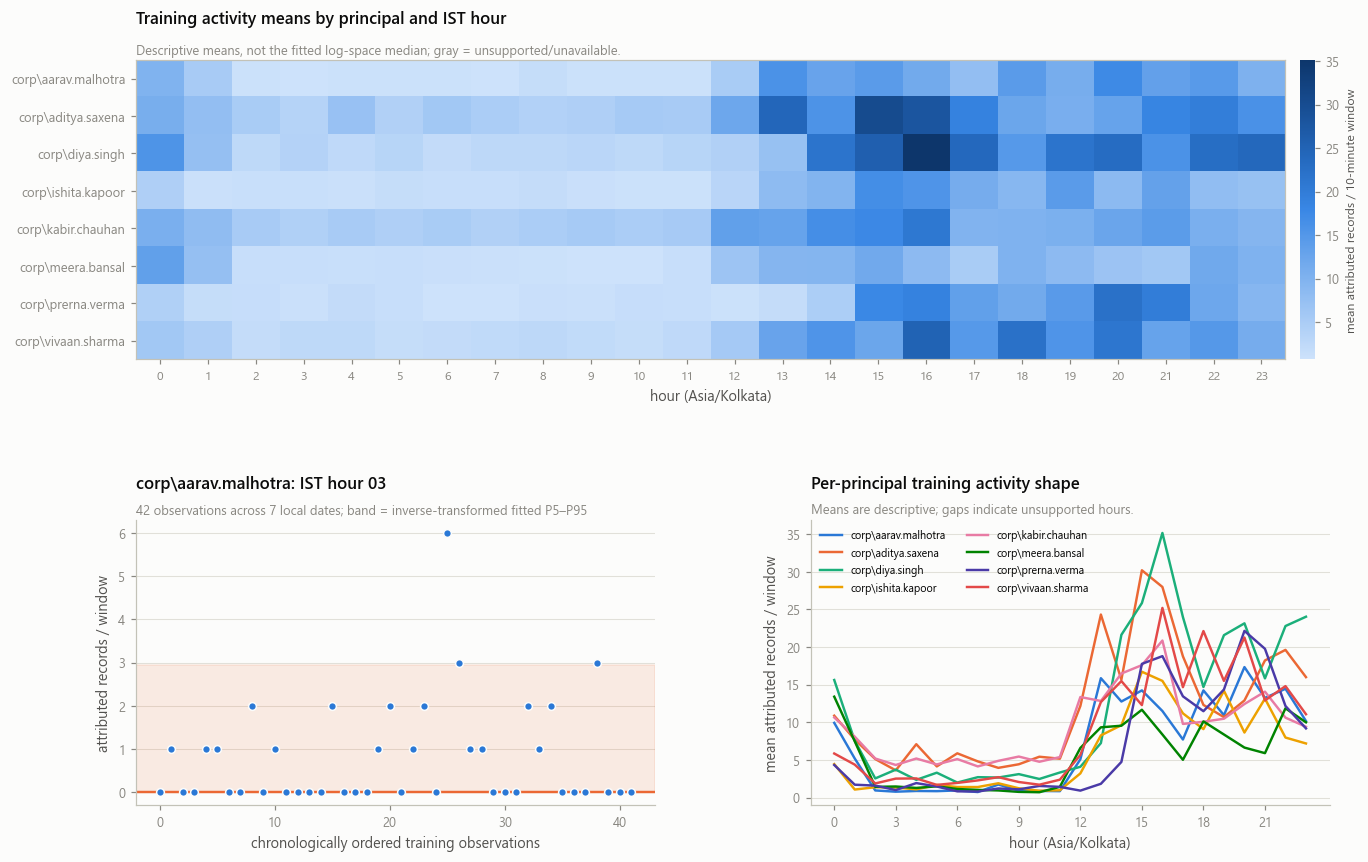

In [33]:
#cell31
# Match the population used by BASELINE—not every original training candidate.
fit_training_mask = (
    W["date"].isin(BASELINE["train_dates"])
    & W["has_telemetry"]
    & W["user"].isin(BASELINE["eligible_users"])
)

activity_input = W.loc[
    fit_training_mask,
    ["user", "hour", "win", "behavior_date", "event_count"],
]

# Missing/unsupported hours stay NaN rather than appearing as quiet zeros.
hm = (
    activity_input.groupby(["user", "hour"], observed=True)["event_count"]
    .mean()
    .unstack()
    .reindex(index=PRINCIPALS, columns=range(24))
)

supported_hours = (
    num["supported"]
    .unstack()
    .reindex(index=PRINCIPALS, columns=range(24))
    .fillna(False)
    .astype(bool)
)
hm = hm.where(supported_hours)

fig = plt.figure(figsize=(14, 8.8))
gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.05, 1],
    hspace=0.55,
    wspace=0.30,
)

# ---- descriptive mean activity -------------------------------------------------
ax = fig.add_subplot(gs[0, :])

cmap = BLUES.copy()
cmap.set_bad("#dddddd")

im = ax.imshow(
    np.ma.masked_invalid(hm.to_numpy(dtype=float)),
    aspect="auto",
    cmap=cmap,
)
ax.set_yticks(range(len(hm)))
ax.set_yticklabels(hm.index, fontsize=8.5)
ax.set_xticks(range(24))
ax.set_xticklabels(range(24), fontsize=8)
ax.grid(False)

cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.012)
cb.outline.set_visible(False)
cb.set_label("mean attributed records / 10-minute window", fontsize=8)

ax.set_title(
    "Training activity means by principal and IST hour",
    loc="left", color=INK, pad=24,
)
ax.text(
    0, 1.02,
    "Descriptive means, not the fitted log-space median; "
    "gray = unsupported/unavailable.",
    transform=ax.transAxes, color=MUTED, fontsize=8.5,
)
ax.set_xlabel(f"hour ({BEHAVIOR_TZ})")

# ---- observations behind one user/hour ----------------------------------------
ax = fig.add_subplot(gs[1, 0])
u, h = EXAMPLE_USER, 3

cell = activity_input.loc[
    activity_input["user"].eq(u) & activity_input["hour"].eq(h)
].sort_values("win", kind="stable")

summary_row = BASELINE_TABLE.loc[
    BASELINE_TABLE["user"].eq(u)
    & BASELINE_TABLE["hour"].eq(h)
    & BASELINE_TABLE["feature"].eq("event_count")
]

if not cell.empty:
    ax.scatter(
        np.arange(len(cell)),
        cell["event_count"].to_numpy(),
        s=26, color=CAT[0],
        edgecolor=SURFACE, linewidth=1.0, zorder=3,
    )

if (
    len(summary_row) == 1
    and bool(summary_row["supported"].iloc[0])
):
    row = summary_row.iloc[0]
    ax.axhline(row["median_events"], color=CAT[1], lw=1.6)
    ax.axhspan(
        row["p05_events"], row["p95_events"],
        color=CAT[1], alpha=0.12,
    )
    band_note = "band = inverse-transformed fitted P5–P95"
else:
    band_note = "insufficient support; no scoring baseline shown"
    if cell.empty:
        ax.text(
            0.5, 0.5, "No eligible observations",
            transform=ax.transAxes, ha="center", va="center",
        )

actual_behavior_days = int(cell["behavior_date"].nunique())

finish(
    ax,
    f"{u}: IST hour {h:02d}",
    f"{len(cell)} observations across {actual_behavior_days} local dates; "
    f"{band_note}",
    xlabel="chronologically ordered training observations",
    ylabel="attributed records / window",
)

# ---- per-principal descriptive hourly shape ------------------------------------
ax = fig.add_subplot(gs[1, 1])

for i, user in enumerate(PRINCIPALS):
    values = hm.loc[user]
    if values.notna().any():
        ax.plot(
            range(24), values.to_numpy(dtype=float),
            color=CAT[i % len(CAT)],
            lw=1.6,
            label=user,
        )

finish(
    ax,
    "Per-principal training activity shape",
    "Means are descriptive; gaps indicate unsupported hours.",
    xlabel=f"hour ({BEHAVIOR_TZ})",
    ylabel="mean attributed records / window",
)
ax.set_xticks(range(0, 24, 3))

handles, labels = ax.get_legend_handles_labels()
if handles:
    ax.legend(ncols=2, loc="upper left", fontsize=7)

plt.show()

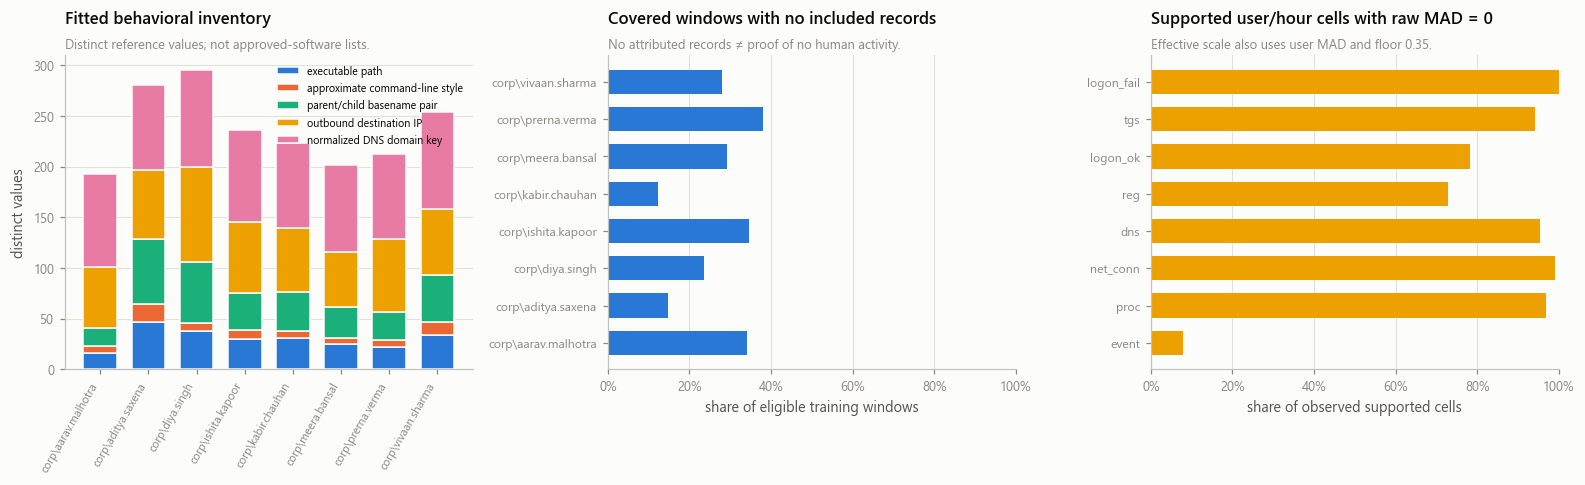

In [ ]:
#cell32
num = BASELINE["num"]
report_users = BASELINE["eligible_users"]

if not report_users:
    raise ValueError("The baseline has no eligible principals.")

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.5))

# ---- inventory sizes -----------------------------------------------------------
ax = axes[0]
dimensions = ["process", "cmd_sig", "pair", "dst_ip", "domain"]

iv = (
    inv_sizes.reindex(
        index=report_users, columns=dimensions, fill_value=0
    )
    .fillna(0)
)
bottom = np.zeros(len(iv), dtype=float)

for i, dimension in enumerate(dimensions):
    values = iv[dimension].to_numpy(dtype=float)
    ax.bar(
        np.arange(len(iv)), values,
        bottom=bottom, color=CAT[i % len(CAT)], width=0.7,
        label=ITEM_LABEL[dimension],
        linewidth=1, edgecolor=SURFACE,
    )
    bottom += values

ax.set_xticks(range(len(iv)))
ax.set_xticklabels(iv.index, rotation=60, ha="right", fontsize=7.5)
finish(
    ax, "Fitted behavioral inventory",
    "Distinct reference values; not approved-software lists.",
    ylabel="distinct values",
)
ax.legend(fontsize=7, loc="best")

# ---- quiet-window share: same fitted population --------------------------------
ax = axes[1]

activity_mask = (
    W["date"].isin(BASELINE["train_dates"])
    & W["has_telemetry"]
    & W["user"].isin(report_users)
)
quiet_input = W.loc[
    activity_mask, ["user", "event_count"]
].copy()
quiet_input["quiet"] = quiet_input["event_count"].eq(0)

quiet_share = (
    quiet_input.groupby("user", observed=True)["quiet"]
    .mean()
    .reindex(report_users)
)

ax.barh(
    range(len(quiet_share)),
    quiet_share.to_numpy(),
    color=CAT[0], height=0.65,
)
ax.set_yticks(range(len(quiet_share)))
ax.set_yticklabels(quiet_share.index, fontsize=8)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
finish(
    ax, "Covered windows with no included records",
    "No attributed records ≠ proof of no human activity.",
    xlabel="share of eligible training windows", xgrid=True,
)

# ---- raw MAD=0 among supported cells only --------------------------------------
ax = axes[2]
supported = num["supported"].reindex(num["mad_h"].index).fillna(False)
supported_mad = num["mad_h"].loc[supported.astype(bool)]

requested = [
    "event_count", "proc_count", "net_conn_count", "dns_count",
    "reg_count", "logon_ok_count", "tgs_count", "logon_fail_count",
]
pick = [feature for feature in requested if feature in supported_mad.columns]

if not supported_mad.empty and pick:
    # Missing cells must not enter the denominator as nonzero-MAD cells.
    mad_zero_share = (
        supported_mad[pick].eq(0).sum()
        / supported_mad[pick].notna().sum().replace(0, np.nan)
    )

    ax.barh(
        range(len(pick)), mad_zero_share.to_numpy(),
        color=CAT[3], height=0.65,
    )
    ax.set_yticks(range(len(pick)))
    ax.set_yticklabels(
        [feature.replace("_count", "") for feature in pick],
        fontsize=8,
    )
else:
    ax.text(
        0.5, 0.5, "No supported MAD observations",
        transform=ax.transAxes, ha="center", va="center",
    )

ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
finish(
    ax, "Supported user/hour cells with raw MAD = 0",
    f"Effective scale also uses user MAD and floor {MAD_FLOOR}.",
    xlabel="share of observed supported cells", xgrid=True,
)

plt.tight_layout()
plt.show()

del quiet_input

In [68]:
# cell33 — Eligibility-aware scoring with grouped novelty
# Requires the corrected baseline-fitting cells.

# ---- novelty policy ------------------------------------------------------------
BASE_W = {
    "process": 1.0,
    "cmd_sig": 0.9,
    "pair": 0.7,
    "src_ip": 1.0,
    "auth_path": 1.0,
    "logon_host_type": 1.1,
    "logon_type": 0.6,
    "dst_ip": 0.5,
    "dst_port": 0.2,
    "domain": 0.4,
    "computer": 0.5,
}

GNOV_W = {
    "process": 1.0,
    "cmd_sig": 0.5,
    "pair": 0.5,
    "src_ip": 1.0,
    "auth_path": 0.4,
    "logon_host_type": 0.4,
    "logon_type": 0.0,
    "dst_ip": 1.0,
    "dst_port": 0.5,
    "domain": 1.8,
    "computer": 0.3,
}

# Related dimensions share one evidence family.
# Each family contributes its strongest item, not the sum of every item.
NOVELTY_FAMILY = {
    "process": "execution",
    "cmd_sig": "execution",
    "pair": "execution",

    "src_ip": "authentication",
    "auth_path": "authentication",
    "logon_host_type": "authentication",
    "logon_type": "authentication",
    "computer": "authentication",

    "dst_ip": "network",
    "dst_port": "network",
    "domain": "network",
}

# Proposed baseline-noise control, not a validated optimum.
NETWORK_NOVELTY_CAP = 1.0

assert set(BASE_W) == set(ITEM_LABEL)
assert set(GNOV_W) == set(BASE_W)
assert set(NOVELTY_FAMILY) == set(BASE_W)

assert all(np.isfinite(v) and v >= 0 for v in BASE_W.values())
assert all(np.isfinite(v) and v >= 0 for v in GNOV_W.values())

if not np.isfinite(NETWORK_NOVELTY_CAP) or NETWORK_NOVELTY_CAP <= 0:
    raise ValueError("NETWORK_NOVELTY_CAP must be finite and positive.")

if not LOGW.index.equals(W.index):
    raise ValueError("LOGW and W indices are misaligned.")

if not (0 <= Z0 < Z1):
    raise ValueError("Require 0 <= Z0 < Z1.")

for constant in (K_STAT, K_NOV, K_RARE, K_ACT):
    if not np.isfinite(constant) or constant <= 0:
        raise ValueError("Squashing constants must be finite and positive.")

# Record the scoring policy separately from the fitted-baseline ID.
SCORING_POLICY = {
    "version": "grouped_novelty_v1",
    "base_weights": BASE_W,
    "global_novelty_weights": GNOV_W,
    "novelty_families": NOVELTY_FAMILY,
    "network_novelty_cap": NETWORK_NOVELTY_CAP,
    "z0": Z0,
    "z1": Z1,
    "mad_factor": MAD_NORMAL_FACTOR,
    "mad_floor": MAD_FLOOR,
    "user_scale_factor": USER_SCALE_FACTOR,
    "k_stat": K_STAT,
    "k_nov": K_NOV,
    "k_rare": K_RARE,
    "k_act": K_ACT,
    "activation_weights": ACT_WEIGHTS,
    "synthetic_documentation_external": (
        SYNTHETIC_DOCUMENTATION_EXTERNAL
    ),
}
SCORING_ID = hashlib.sha256(
    json.dumps(SCORING_POLICY, sort_keys=True).encode("utf-8")
).hexdigest()[:16]


# ---- scoring-date validation ---------------------------------------------------
def validate_score_dates(bl, score_dates):
    dates = list(score_dates)

    if not dates or len(dates) != len(set(dates)):
        raise ValueError("Scoring dates must be nonempty and unique.")

    if not set(dates).issubset(ALL_DATES):
        raise ValueError("Scoring dates fall outside configured dates.")

    if set(dates).intersection(bl["train_dates"]):
        raise ValueError(
            "Scored dates overlap this baseline's fitting dates."
        )

    if bl["metadata"]["stat_features"] != STAT_FEATURES:
        raise ValueError(
            "Statistical feature schema differs from fitted baseline."
        )

    return sorted(dates)


# ---- supported population ------------------------------------------------------
def supported_rows(bl, idx):
    sub = W.loc[idx, ["user", "hour", "has_telemetry"]]

    keys = pd.MultiIndex.from_arrays(
        [sub["user"], sub["hour"]],
        names=["user", "hour"],
    )

    user_ok = (
        sub["user"]
        .map(bl["user_support"]["eligible"])
        .astype("boolean")
        .fillna(False)
        .to_numpy(dtype=bool)
    )

    hour_ok = (
        bl["num"]["supported"]
        .reindex(keys)
        .astype("boolean")
        .fillna(False)
        .to_numpy(dtype=bool)
    )

    return (
        sub["has_telemetry"].to_numpy(dtype=bool)
        & user_ok
        & hour_ok
    )


def valid_score_index(bl, score_dates):
    dates = validate_score_dates(bl, score_dates)

    idx = W.index[
        W["date"].isin(dates)
        & W["has_telemetry"]
    ]

    return idx[supported_rows(bl, idx)]


# ---- novelty evidence ----------------------------------------------------------
def novelty_frame(bl, score_dates):
    dates = validate_score_dates(bl, score_dates)
    eligible_idx = valid_score_index(bl, dates)

    eligible_keys = pd.MultiIndex.from_frame(
        W.loc[eligible_idx, ["user", "win"]]
    )
    item_keys = pd.MultiIndex.from_frame(
        ITEMS[["user", "win"]]
    )

    d = ITEMS.loc[
        ITEMS["date"].isin(dates)
        & item_keys.isin(eligible_keys)
    ].copy()

    d = (
        d.merge(
            bl["known"],
            on=["user", "itype", "value"],
            how="left",
            validate="many_to_one",
        )
        .merge(
            bl["gcnt"],
            on=["itype", "gvalue"],
            how="left",
            validate="many_to_one",
        )
    )

    d["known"] = (
        d["known"]
        .astype("boolean")
        .fillna(False)
        .astype(bool)
    )
    d["gcnt"] = d["gcnt"].fillna(0).astype("int64")
    d = d.loc[~d["known"]].copy()

    base = d["itype"].map(BASE_W)
    global_bonus = d["itype"].map(GNOV_W)

    if base.isna().any() or global_bonus.isna().any():
        raise ValueError("An item dimension has no novelty weight.")

    globally_unseen = d["gcnt"].eq(0)

    # Raw item evidence retained for audit.
    # These weights are grouped/capped before creating the channel score.
    d["w"] = (
        base.astype(float)
        + globally_unseen.astype(float) * global_bonus.astype(float)
        + d["susp_dir"].astype(float) * 1.0
        + (
            d["is_external"]
            & d["itype"].eq("src_ip")
        ).astype(float) * 2.5
        + (
            d["is_external"]
            & d["itype"].eq("dst_ip")
            & globally_unseen
        ).astype(float) * 2.0
        + d["sens_port"].astype(float) * 0.8
        + d["interactive"].astype(float) * 0.8
    )

    d["family"] = d["itype"].map(NOVELTY_FAMILY)

    if d["family"].isna().any():
        raise ValueError("Novelty item has no evidence-family mapping.")

    assert np.isfinite(d["w"].to_numpy(dtype=float)).all()
    assert d["w"].ge(0).all()
    assert not d.duplicated(
        ["user", "win", "itype", "value"]
    ).any()

    return d


def novelty_family_frame(novelty):
    """
    One score per user/window/family.

    raw_family_weight: strongest raw item in that family.
    family_weight: actual family score after applying the network cap.
    """
    evidence = novelty[
        ["user", "win", "itype", "w"]
    ].copy()
    evidence["family"] = evidence["itype"].map(NOVELTY_FAMILY)

    if evidence["family"].isna().any():
        raise ValueError("Novelty dimension has no family mapping.")

    family_scores = (
        evidence.groupby(
            ["user", "win", "family"],
            observed=True,
            sort=False,
        )["w"]
        .max()
        .rename("raw_family_weight")
        .reset_index()
    )

    family_scores["family_weight"] = (
        family_scores["raw_family_weight"].astype(float)
    )

    network = family_scores["family"].eq("network")
    family_scores.loc[network, "family_weight"] = (
        family_scores.loc[network, "family_weight"]
        .clip(upper=NETWORK_NOVELTY_CAP)
    )

    assert not family_scores.duplicated(
        ["user", "win", "family"]
    ).any()
    assert family_scores["family_weight"].ge(0).all()

    return family_scores


def aggregate_novelty(novelty):
    family_scores = novelty_family_frame(novelty)

    return (
        family_scores.groupby(
            ["user", "win"],
            observed=True,
            sort=False,
        )["family_weight"]
        .sum()
        .rename("nov")
    )


# ---- rarity: additive user/corpus surprise -------------------------------------
def rarity_frame(bl, score_dates):
    dates = validate_score_dates(bl, score_dates)
    eligible_idx = valid_score_index(bl, dates)

    eligible_keys = pd.MultiIndex.from_frame(
        W.loc[eligible_idx, ["user", "win"]]
    )
    event_keys = pd.MultiIndex.from_frame(
        ev[["user", "win"]]
    )

    mask = (
        ev["date"].isin(dates)
        & event_keys.isin(eligible_keys)
    )

    sc = (
        ev.loc[mask, ["user", "win"] + EID_KEY]
        .groupby(
            ["user", "win"] + EID_KEY,
            observed=True,
            sort=False,
        )
        .size()
        .rename("n")
        .reset_index()
    )

    sc = (
        sc.merge(
            bl["eid_ucnt"],
            on=["user"] + EID_KEY,
            how="left",
            validate="many_to_one",
        )
        .merge(
            bl["eid_utot"],
            on="user",
            how="left",
            validate="many_to_one",
        )
        .merge(
            bl["eid_gcnt"],
            on=EID_KEY,
            how="left",
            validate="many_to_one",
        )
    )

    if sc["utot"].isna().any() or sc["utot"].le(0).any():
        raise ValueError(
            "Eligible rarity rows have no positive fitted user total."
        )
    if bl["eid_gtot"] <= 0:
        raise ValueError("Empty fitted rarity reference corpus.")

    sc["ucnt"] = sc["ucnt"].fillna(0).astype(float)
    sc["gcnt"] = sc["gcnt"].fillna(0).astype(float)

    sc["surprise_user"] = -np.log10(
        (sc["ucnt"] + 0.5) / (sc["utot"] + 1.0)
    )
    sc["surprise_global"] = -np.log10(
        (sc["gcnt"] + 0.5) / (bl["eid_gtot"] + 1.0)
    )

    # Either excess can contribute; this is not an AND gate.
    sc["w"] = (
        np.maximum(sc["surprise_user"] - 3.0, 0) * 0.6
        + np.maximum(sc["surprise_global"] - 4.0, 0) * 1.2
    )

    assert np.isfinite(sc["w"].to_numpy(dtype=float)).all()

    return sc.loc[sc["w"].gt(0)].copy()


# ---- capability activation -----------------------------------------------------
def activation_matrix(bl, idx):
    sub = W.loc[idx, ["user"] + ACT_FEATURES]
    valid = supported_rows(bl, idx)

    result = np.full(
        (len(sub), len(ACT_FEATURES)),
        np.nan,
        dtype=float,
    )

    if not valid.any():
        return result

    users = sub.loc[valid, "user"]

    baseline_max = (
        bl["act_max"]
        .reindex(users)[ACT_FEATURES]
        .to_numpy(dtype=float)
    )
    current = sub.loc[valid, ACT_FEATURES].to_numpy(dtype=float)

    if not np.isfinite(baseline_max).all():
        raise ValueError(
            "Supported activation rows have unavailable baseline maxima."
        )
    if not np.isfinite(current).all():
        raise ValueError(
            "Supported activation rows have invalid current counts."
        )

    fired = (current > 0) & (baseline_max == 0)
    weights = np.array(
        [ACT_WEIGHTS[feature] for feature in ACT_FEATURES],
        dtype=float,
    )

    result[valid] = (
        fired
        * weights[None, :]
        * (1 + 0.3 * np.log1p(current))
    )

    return result


# ---- robust upward numeric deviation ------------------------------------------
def robust_z(bl, idx):
    valid = supported_rows(bl, idx)
    result = np.full(
        (len(idx), len(STAT_FEATURES)),
        np.nan,
        dtype=float,
    )

    if not valid.any():
        return result

    valid_idx = idx[valid]
    sub = LOGW.loc[valid_idx]

    keys = pd.MultiIndex.from_arrays(
        [sub["user"], sub["hour"]],
        names=["user", "hour"],
    )
    numeric = bl["num"]

    X = sub[STAT_FEATURES].to_numpy(dtype=float)
    median = (
        numeric["med_h"]
        .reindex(keys)[STAT_FEATURES]
        .to_numpy(dtype=float)
    )
    mad = (
        numeric["mad_h"]
        .reindex(keys)[STAT_FEATURES]
        .to_numpy(dtype=float)
    )
    user_mad = (
        numeric["mad_u"]
        .reindex(sub["user"])[STAT_FEATURES]
        .to_numpy(dtype=float)
    )
    p95 = (
        numeric["p95_h"]
        .reindex(keys)[STAT_FEATURES]
        .to_numpy(dtype=float)
    )

    if not all(
        np.isfinite(array).all()
        for array in (X, median, mad, user_mad, p95)
    ):
        raise ValueError(
            "Supported numeric rows contain missing baseline values."
        )

    scale = np.maximum.reduce([
        MAD_NORMAL_FACTOR * mad,
        USER_SCALE_FACTOR * MAD_NORMAL_FACTOR * user_mad,
        np.full_like(X, MAD_FLOOR),
    ])

    z = np.maximum((X - median) / scale, 0)
    result[valid] = np.where(X > p95, z, 0.0)

    return result


def combine_stat(severity):
    severity = np.asarray(severity, dtype=float)

    if severity.ndim != 2 or severity.shape[1] == 0:
        raise ValueError(
            "Severity must be a 2D matrix with at least one feature."
        )

    valid = np.isfinite(severity).all(axis=1)
    partially_available = (
        np.isfinite(severity).any(axis=1) & ~valid
    )

    if partially_available.any():
        raise ValueError(
            "Partially unavailable statistical severity rows."
        )

    raw_score = np.full(len(severity), np.nan, dtype=float)

    if valid.any():
        ranked = -np.sort(-severity[valid], axis=1)
        k = min(3, ranked.shape[1])
        decay = np.array([1.0, 0.5, 0.25], dtype=float)[:k]
        raw_score[valid] = ranked[:, :k] @ decay

    return -np.expm1(-raw_score / K_STAT), raw_score


# ---- complete scoring block ----------------------------------------------------
def score_block(bl, score_dates, temp_profile=None):
    dates = validate_score_dates(bl, score_dates)

    idx = W.index[
        W["date"].isin(dates)
        & W["has_telemetry"]
    ]
    valid = supported_rows(bl, idx)

    z = robust_z(bl, idx)
    severity = np.clip((z - Z0) / (Z1 - Z0), 0, 1)
    s_stat, stat_raw = combine_stat(severity)
    activation = activation_matrix(bl, idx)

    novelty = novelty_frame(bl, dates)
    rarity = rarity_frame(bl, dates)

    # Retain family-level evidence for explanations and audit.
    novelty_families = novelty_family_frame(novelty)

    novelty_totals = (
        novelty_families.groupby(
            ["user", "win"],
            observed=True,
            sort=False,
        )["family_weight"]
        .sum()
        .rename("nov")
    )

    rarity_totals = (
        rarity.groupby(
            ["user", "win"],
            observed=True,
            sort=False,
        )["w"]
        .sum()
    )

    out = W.loc[
        idx,
        [
            "wid", "user", "win", "date", "hour", "day_type",
            "is_train", "is_test", "has_telemetry", "event_count",
        ],
    ].copy()

    out["score_eligible"] = valid
    out["status"] = np.where(
        valid,
        "SCORED_PENDING_THRESHOLD",
        "INSUFFICIENT_HISTORY",
    )
    out["fit_id"] = bl["fit_id"]
    out["scoring_id"] = SCORING_ID

    keys = pd.MultiIndex.from_frame(out[["user", "win"]])

    # Correct indentation: assignment belongs INSIDE the loop.
    for name, totals in [
        ("nov", novelty_totals),
        ("rare", rarity_totals),
    ]:
        values = totals.reindex(
            keys, fill_value=0
        ).to_numpy(dtype=float)

        values[~valid] = np.nan
        out[name] = values

    out["act"] = activation.sum(axis=1)
    out["stat_raw"] = stat_raw
    out["s_stat"] = s_stat
    out["s_nov"] = -np.expm1(-out["nov"] / K_NOV)
    out["s_rare"] = -np.expm1(-out["rare"] / K_RARE)
    out["s_act"] = -np.expm1(-out["act"] / K_ACT)

    # Temporal profile must belong to this baseline's training dates.
    temporal = (
        bl["temp_profile"]
        if temp_profile is None
        else temp_profile
    )

    if temporal.attrs.get("train_dates") != bl["train_dates"]:
        raise ValueError(
            "Temporal profile has different fit-date provenance."
        )
    if temporal.attrs.get("behavior_timezone") != BEHAVIOR_TZ:
        raise ValueError("Temporal profile timezone mismatch.")
    if temporal.duplicated(["user", "day_type", "hour"]).any():
        raise ValueError("Duplicate temporal-profile keys.")

    temporal_keys = pd.MultiIndex.from_frame(
        out[["user", "day_type", "hour"]]
    )

    p = (
        temporal.set_index(["user", "day_type", "hour"])["p_active"]
        .reindex(temporal_keys)
        .to_numpy(dtype=float)
    )
    prior = (
        temporal.groupby("user", observed=True)["prior"]
        .first()
        .reindex(out["user"])
        .to_numpy(dtype=float)
    )

    used_prior = np.isnan(p) & valid
    p = np.where(np.isnan(p), prior, p)
    p[~valid] = np.nan

    if not np.isfinite(p[valid]).all():
        raise ValueError(
            "Supported temporal rows lack both context and prior."
        )
    if not ((p[valid] >= 0) & (p[valid] <= 1)).all():
        raise ValueError("Temporal activity rates outside [0, 1].")

    out["p_active"] = p
    out["temporal_used_prior"] = used_prior
    out["s_temp"] = np.where(
        valid,
        np.where(
            out["event_count"].to_numpy(dtype=float) > 0,
            1 - p,
            0.0,
        ),
        np.nan,
    )

    signal_columns = [
        "s_stat", "s_nov", "s_rare", "s_act", "s_temp"
    ]
    eligible_signals = out.loc[
        valid, signal_columns
    ].to_numpy(dtype=float)

    assert np.isfinite(eligible_signals).all()
    assert (
        (eligible_signals >= 0)
        & (eligible_signals <= 1)
    ).all()
    assert out.loc[~valid, signal_columns].isna().all().all()
    assert out["wid"].is_unique
    assert not out.duplicated(["user", "win"]).any()

    debug = {
        "wid": out["wid"].to_numpy(copy=True),
        "eligible": valid.copy(),
        "scoring_id": SCORING_ID,
        "z": z,
        "sev": severity,
        "nov": novelty,
        "nov_families": novelty_families,
        "rare": rarity,
        "act": activation,
    }

    return out.reset_index(drop=True), debug


# ---- grouped-novelty sanity check ----------------------------------------------
# Two execution descriptions must count once; multiple network items are capped.
_test_novelty = pd.DataFrame({
    "user": ["test"] * 4,
    "win": pd.to_datetime(
        ["2026-01-01 00:00:00+00:00"] * 4
    ),
    "itype": ["process", "pair", "dst_ip", "domain"],
    "w": [2.0, 1.2, 3.5, 2.2],
})

_test_total = aggregate_novelty(_test_novelty)
assert len(_test_total) == 1
assert np.isclose(
    _test_total.iloc[0],
    2.0 + min(3.5, NETWORK_NOVELTY_CAP),
)

del _test_novelty, _test_total


# ---- offline leave-one-day-out baseline signals --------------------------------
# This is offline cross-fitting, NOT forward-in-time validation.
print("Generating leave-one-day-out baseline signals...")
print("Scoring policy ID:", SCORING_ID)

tr_parts = []
tr_z = []
tr_act = []
tr_severity = []
fold_rows = []

for held_out_day in TRAIN_DATES:
    fitting_dates = [
        day for day in TRAIN_DATES if day != held_out_day
    ]

    fold_baseline = fit_baseline(fitting_dates)
    output, debug = score_block(
        fold_baseline, [held_out_day]
    )

    assert np.array_equal(
        output["wid"].to_numpy(),
        debug["wid"],
    )

    tr_parts.append(output)
    tr_z.append(debug["z"])
    tr_act.append(debug["act"])
    tr_severity.append(debug["sev"])

    fold_rows.append({
        "held_out_utc_date": held_out_day,
        "fit_id": fold_baseline["fit_id"],
        "scoring_id": SCORING_ID,
        "covered_windows": len(output),
        "score_eligible": int(output["score_eligible"].sum()),
        "insufficient_history": int(
            (~output["score_eligible"]).sum()
        ),
    })

TR = pd.concat(tr_parts, ignore_index=True)
Z_TR = np.vstack(tr_z)
ACT_TR = np.vstack(tr_act)
SEV_TR = np.vstack(tr_severity)

assert TR["wid"].is_unique
assert len(TR) == len(TRAIN_W)
assert len(TR) == len(Z_TR) == len(ACT_TR) == len(SEV_TR)
assert TR["scoring_id"].eq(SCORING_ID).all()

display(pd.DataFrame(fold_rows))


# ---- testing against the full configured baseline ------------------------------
TE, DBG = score_block(BASELINE, TEST_DATES)

Z_TE = DBG["z"]
SEV_TE = DBG["sev"]
NOV_TE = DBG["nov"]
NOV_FAMILY_TE = DBG["nov_families"]
RARE_TE = DBG["rare"]
ACT_TE = DBG["act"]

assert np.array_equal(
    TE["wid"].to_numpy(), DBG["wid"]
)
assert len(TE) == len(TEST_W)
assert set(TR["wid"]).isdisjoint(TE["wid"])
assert TE["scoring_id"].eq(SCORING_ID).all()

print(f"\nCovered test windows: {len(TE):,}")
print(
    f"Score-eligible      : "
    f"{int(TE['score_eligible'].sum()):,}"
)
print(
    f"Insufficient history: "
    f"{int((~TE['score_eligible']).sum()):,}"
)

display(
    TE.loc[
        TE["score_eligible"],
        ["s_stat", "s_nov", "s_rare", "s_act", "s_temp"],
    ]
    .describe(percentiles=[0.5, 0.9, 0.99])
    .round(3)
)

print(
    "Grouped novelty: strongest item per evidence family; "
    f"network family capped at {NETWORK_NOVELTY_CAP}."
)
print(
    "Raw item weights remain in NOV_TE for audit. "
    "Actual family contributions are in NOV_FAMILY_TE."
)
print(
    "Scores have changed. Rerun Cells 34 onward to rebuild ML scores, "
    "thresholds, decisions, and evaluation. Do not reuse old thresholds."
)

Generating leave-one-day-out baseline signals...
Scoring policy ID: 80c88feb3bb5d04e


,held_out_utc_date,fit_id,scoring_id,covered_windows,score_eligible,insufficient_history
0,2026-07-28,5f203a68b91080da,80c88feb3bb5d04e,1152,1152,0
1,2026-07-29,2cc6b86e59755dbc,80c88feb3bb5d04e,1152,1152,0
2,2026-07-30,4d9be5440c215664,80c88feb3bb5d04e,1152,1152,0
3,2026-07-31,f96f82d63775e99f,80c88feb3bb5d04e,1152,1152,0
4,2026-08-01,041149a6470a7fae,80c88feb3bb5d04e,1152,1152,0
5,2026-08-02,c978a2852a9d86dd,80c88feb3bb5d04e,1152,1152,0
6,2026-08-03,8b4ba62fc49724ab,80c88feb3bb5d04e,1152,1152,0



Covered test windows: 26,496
Score-eligible      : 26,496
Insufficient history: 0


,s_stat,s_nov,s_rare,s_act,s_temp
count,26496.000,26496.000,26496.000,26496.000,26496.000
mean,0.022,0.018,0.003,0.004,0.178
std,0.078,0.069,0.038,0.049,0.178
min,0.000,0.000,0.000,0.000,0.000
50%,0.000,0.000,0.000,0.000,0.106
90%,0.046,0.000,0.000,0.000,0.456
99%,0.418,0.354,0.050,0.000,0.628
max,0.607,0.755,0.974,0.984,0.710


Grouped novelty: strongest item per evidence family; network family capped at 1.0.
Raw item weights remain in NOV_TE for audit. Actual family contributions are in NOV_FAMILY_TE.
Scores have changed. Rerun Cells 34 onward to rebuild ML scores, thresholds, decisions, and evaluation. Do not reuse old thresholds.


In [69]:
# ---- prerequisites -------------------------------------------------------------
required_score_columns = {
    "wid", "user", "win", "date", "score_eligible",
}
for label, frame in [("TR", TR), ("TE", TE)]:
    missing = sorted(required_score_columns - set(frame.columns))
    if missing:
        raise ValueError(f"{label} missing columns: {missing}")
    if not frame["wid"].is_unique:
        raise ValueError(f"Duplicate window IDs in {label}.")

# Do not convert unavailable history to zero with nan_to_num().
# Use a dedicated numeric baseline and the SAME numeric transform for:
# ML fitting, ML calibration, and ML testing.

ML_FIT_DAY_COUNT = max(4, MIN_TRAIN_DAYS)
if len(TRAIN_DATES) <= ML_FIT_DAY_COUNT:
    raise ValueError(
        "Insufficient training dates for separate ML fitting and calibration. "
        "Provide more baseline days or explicitly disable the ML component."
    )

ML_FIT_DATES = sorted(TRAIN_DATES)[:ML_FIT_DAY_COUNT]
ML_CALIBRATION_DATES = sorted(TRAIN_DATES)[ML_FIT_DAY_COUNT:]

assert set(ML_FIT_DATES).isdisjoint(ML_CALIBRATION_DATES)
assert max(ML_FIT_DATES) < min(ML_CALIBRATION_DATES)
assert set(ML_CALIBRATION_DATES).isdisjoint(TEST_DATES)

ML_BASELINE = fit_baseline(ML_FIT_DATES)

# Dedicated fitting vectors. Using these to train a model is legitimate;
# they are NOT reused as its calibration-score reference.
ml_fit_idx = W.index[
    W["date"].isin(ML_FIT_DATES) & W["has_telemetry"]
]
ml_fit_z = robust_z(ML_BASELINE, ml_fit_idx)
ml_fit_valid = (
    supported_rows(ML_BASELINE, ml_fit_idx)
    & np.isfinite(ml_fit_z).all(axis=1)
)
X_ml_fit = ml_fit_z[ml_fit_valid]

if len(X_ml_fit) < 50:
    raise ValueError(
        f"Only {len(X_ml_fit)} supported ML fitting windows. "
        "Do not fabricate zero vectors; obtain more baseline support."
    )
if X_ml_fit.shape[1] == 0:
    raise ValueError("No ML input features.")

# Map by immutable window IDs, not TR/TE row positions.
wid_to_w_index = pd.Series(W.index.to_numpy(), index=W["wid"])

def ml_vectors_for(frame):
    mapped = frame["wid"].map(wid_to_w_index)
    if mapped.isna().any():
        raise ValueError("Scored window ID is missing from W.")

    idx = pd.Index(mapped.to_numpy())
    vectors = robust_z(ML_BASELINE, idx)
    valid = (
        frame["score_eligible"].to_numpy(dtype=bool)
        & supported_rows(ML_BASELINE, idx)
        & np.isfinite(vectors).all(axis=1)
    )
    return vectors, valid

ml_tr_vectors, ml_tr_valid = ml_vectors_for(TR)
ml_te_vectors, ml_te_valid = ml_vectors_for(TE)

ml_calibration_mask = (
    TR["date"].isin(ML_CALIBRATION_DATES).to_numpy()
    & ml_tr_valid
)

if int(ml_calibration_mask.sum()) < 100:
    raise ValueError(
        "Fewer than 100 eligible ML calibration windows. "
        "More baseline exposure is required for meaningful tail calibration."
    )

# Windows used to fit ML are deliberately not assigned calibration ML scores.
ml_tr_output_mask = ml_calibration_mask.copy()

# ---- fit detectors -------------------------------------------------------------
iso = IsolationForest(
    n_estimators=300,
    max_samples=min(512, len(X_ml_fit)),
    random_state=RANDOM_STATE,
    n_jobs=1,  # avoid unnecessary concurrent-memory pressure
).fit(X_ml_fit)

lof = LocalOutlierFactor(
    n_neighbors=min(35, len(X_ml_fit) - 1),
    novelty=True,
    n_jobs=1,
).fit(X_ml_fit)

subsample_size = min(4000, len(X_ml_fit))
rng = np.random.RandomState(RANDOM_STATE)
subsample_positions = rng.choice(
    len(X_ml_fit), subsample_size, replace=False
)

oc = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.02,
    cache_size=128,
).fit(X_ml_fit[subsample_positions])

fitted_ml_models = {
    "IsolationForest": iso,
    "LocalOutlierFactor": lof,
    "OneClassSVM": oc,
}

def anomaly_scores(model, vectors, valid, model_name):
    result = np.full(len(vectors), np.nan, dtype=float)
    if valid.any():
        if model_name == "OneClassSVM":
            values = -model.decision_function(vectors[valid])
        else:
            values = -model.score_samples(vectors[valid])

        values = np.asarray(values, dtype=float).reshape(-1)
        if not np.isfinite(values).all():
            raise ValueError(f"{model_name} produced nonfinite anomaly scores.")
        result[valid] = values
    return result

def reference_percentiles(reference, scores):
    """
    Empirical fraction of calibration scores strictly below each score.
    Ties share a rank; this is NOT a probability of maliciousness.
    """
    reference = np.asarray(reference, dtype=float)
    reference = reference[np.isfinite(reference)]
    if len(reference) == 0:
        raise ValueError("Empty percentile reference.")

    ordered = np.sort(reference)
    output = np.full(len(scores), np.nan, dtype=float)
    valid = np.isfinite(scores)
    output[valid] = (
        np.searchsorted(ordered, scores[valid], side="left") / len(ordered)
    )
    return output

# Compatibility: name -> (TR percentiles, TE percentiles)
ml_models = {}
ML_RAW_SCORES = {}
ML_REFERENCE_SCORES = {}

for name, model in fitted_ml_models.items():
    tr_raw = anomaly_scores(
        model, ml_tr_vectors, ml_tr_output_mask, name
    )
    te_raw = anomaly_scores(
        model, ml_te_vectors, ml_te_valid, name
    )

    reference = tr_raw[ml_calibration_mask]
    tr_percentiles = reference_percentiles(reference, tr_raw)
    te_percentiles = reference_percentiles(reference, te_raw)

    ml_models[name] = (tr_percentiles, te_percentiles)
    ML_RAW_SCORES[name] = (tr_raw, te_raw)
    ML_REFERENCE_SCORES[name] = reference.copy()

# ---- fusion component: IsolationForest -----------------------------------------
TR["ml_pct"], TE["ml_pct"] = ml_models["IsolationForest"]

ML_TAIL_START = 0.995

for frame in (TR, TE):
    frame["ml_available"] = np.isfinite(frame["ml_pct"].to_numpy(float))
    frame["s_ml"] = np.clip(
        (frame["ml_pct"] - ML_TAIL_START) / (1 - ML_TAIL_START),
        0, 1,
    )

    frame["fusion_eligible"] = (
        frame["score_eligible"] & frame["ml_available"]
    )

    # Preserve detailed reasons without mislabeling missing ML as zero/normal.
    frame["ml_status"] = np.where(
        frame["ml_available"],
        "AVAILABLE",
        "UNAVAILABLE_OR_RESERVED_FOR_ML_FITTING",
    )

TR["calibration_eligible"] = (
    TR["fusion_eligible"]
    & TR["date"].isin(ML_CALIBRATION_DATES)
)

assert not TR.loc[
    TR["date"].isin(ML_FIT_DATES), "calibration_eligible"
].any()

assert TR.loc[~TR["ml_available"], "s_ml"].isna().all()
assert TE.loc[~TE["ml_available"], "s_ml"].isna().all()

for frame in (TR, TE):
    available = frame["ml_available"]
    assert frame.loc[available, "s_ml"].between(0, 1).all()

ML_FIT_METADATA = {
    "numeric_baseline_fit_id": ML_BASELINE["fit_id"],
    "fit_dates": ML_FIT_DATES,
    "calibration_dates": ML_CALIBRATION_DATES,
    "fit_windows": len(X_ml_fit),
    "calibration_windows": int(ml_calibration_mask.sum()),
    "features": list(STAT_FEATURES),
    "tail_start": ML_TAIL_START,
    "random_state": RANDOM_STATE,
}

print("ML fitting dates     :", ML_FIT_DATES)
print("ML calibration dates :", ML_CALIBRATION_DATES)
print("ML fitting windows   :", len(X_ml_fit))
print("ML calibration windows:", int(ml_calibration_mask.sum()))
print("TE fusion-eligible windows:", int(TE["fusion_eligible"].sum()))
print(
    "TE positive ML-tail windows:",
    int(TE["s_ml"].gt(0).sum()),
)

print(
    "\nLOF calibration/testing points were not used to fit LOF. "
    "All three models use the same fixed numeric baseline. "
    "Rank calibration is pooled across eligible users and is not a "
    "per-user false-positive guarantee."
)
print(
    "Threshold calibration must use TR.calibration_eligible. "
    "Other channel signals retain offline LODO fitting; therefore this "
    "is not a wholly forward-in-time validation of the complete pipeline."
)

del ml_fit_z, ml_tr_vectors, ml_te_vectors, X_ml_fit

ML fitting dates     : ['2026-07-28', '2026-07-29', '2026-07-30', '2026-07-31']
ML calibration dates : ['2026-08-01', '2026-08-02', '2026-08-03']
ML fitting windows   : 4608
ML calibration windows: 3456
TE fusion-eligible windows: 26496
TE positive ML-tail windows: 165

LOF calibration/testing points were not used to fit LOF. All three models use the same fixed numeric baseline. Rank calibration is pooled across eligible users and is not a per-user false-positive guarantee.
Threshold calibration must use TR.calibration_eligible. Other channel signals retain offline LODO fitting; therefore this is not a wholly forward-in-time validation of the complete pipeline.


,calibration_n,calibration_zero_rate,calibration_p99,calibration_p99_9,calibration_max,test_n,test_p99_9,test_max
signal,,,,,,,,
Statistical deviation,3456,94.0%,0.330,0.521,0.615,26496,0.557,0.607
Baseline-unseen items,3456,94.0%,0.319,0.528,0.747,26496,0.608,0.755
Capability activation,3456,99.9%,0.000,0.000,0.620,26496,0.797,0.984
Event-type rarity,3456,99.7%,0.000,0.103,0.208,26496,0.819,0.974
ML: IsolationForest,3456,99.5%,0.000,0.742,0.942,26496,0.884,1.000
Temporal context,3456,34.4%,0.622,0.726,0.741,26496,0.710,0.710


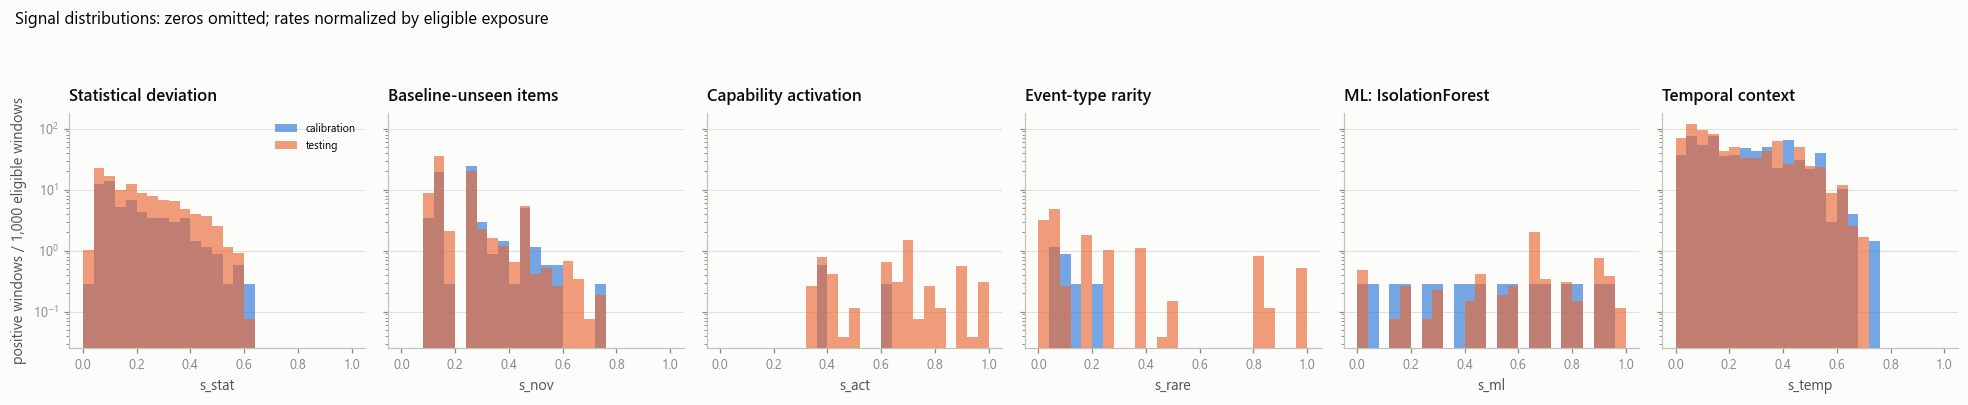

Testing distributions are descriptive only. Do not select model weights or thresholds from these plots using attack labels.


In [70]:
comp = ["s_stat", "s_nov", "s_act", "s_rare", "s_ml", "s_temp"]

titles = {
    "s_stat": "Statistical deviation",
    "s_nov": "Baseline-unseen items",
    "s_act": "Capability activation",
    "s_rare": "Event-type rarity",
    "s_ml": "ML: IsolationForest",
    "s_temp": "Temporal context",
}

# Compare complete signal vectors, not mixtures of rated and unrated rows.
cal_mask = TR["calibration_eligible"].astype(bool)
test_mask = TE["fusion_eligible"].astype(bool)

if not cal_mask.any():
    raise ValueError("No complete calibration signal vectors.")

for label, frame, mask in [
    ("calibration", TR, cal_mask),
    ("testing", TE, test_mask),
]:
    values = frame.loc[mask, comp].to_numpy(float)
    if not np.isfinite(values).all():
        raise ValueError(f"Nonfinite {label} signals.")
    if not ((values >= 0) & (values <= 1)).all():
        raise ValueError(f"{label} signals outside [0, 1].")

rows = []
for signal in comp:
    calibration = TR.loc[cal_mask, signal]
    testing = TE.loc[test_mask, signal]

    rows.append({
        "signal": titles[signal],
        "calibration_n": len(calibration),
        "calibration_zero_rate": calibration.le(1e-9).mean(),
        "calibration_p99": calibration.quantile(0.99),
        "calibration_p99_9": calibration.quantile(0.999),
        "calibration_max": calibration.max(),
        "test_n": len(testing),
        "test_p99_9": testing.quantile(0.999),
        "test_max": testing.max(),
    })

signal_diagnostics = pd.DataFrame(rows).set_index("signal")
display(
    signal_diagnostics.style.format({
        "calibration_zero_rate": "{:.1%}",
        "calibration_p99": "{:.3f}",
        "calibration_p99_9": "{:.3f}",
        "calibration_max": "{:.3f}",
        "test_p99_9": "{:.3f}",
        "test_max": "{:.3f}",
    }, na_rep="—")
)

fig, axes = plt.subplots(
    1, len(comp), figsize=(18, 3.7), sharey=True
)
bins = np.linspace(0, 1, 26)

for i, signal in enumerate(comp):
    ax = axes[i]

    calibration = TR.loc[cal_mask, signal].to_numpy(float)
    testing = TE.loc[test_mask, signal].to_numpy(float)

    # All-window denominators make exposure lengths comparable.
    # Zero values are omitted visually, not from the normalization denominator.
    for values, color, label in [
        (calibration, CAT[0], "calibration"),
        (testing, CAT[1], "testing"),
    ]:
        positive = values[values > 1e-9]
        if len(positive):
            ax.hist(
                positive,
                bins=bins,
                weights=np.full(len(positive), 1000.0 / len(values)),
                color=color,
                alpha=0.65,
                label=label,
            )

    if (
        np.any(calibration > 1e-9)
        or np.any(testing > 1e-9)
    ):
        ax.set_yscale("log")
    else:
        ax.text(
            0.5, 0.5, "No positive signals",
            transform=ax.transAxes,
            ha="center", va="center", fontsize=8,
        )

    finish(ax, titles[signal], xlabel=signal)
    if i == 0:
        ax.set_ylabel("positive windows / 1,000 eligible windows")
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ax.legend(fontsize=7)

fig.suptitle(
    "Signal distributions: zeros omitted; rates normalized by eligible exposure",
    x=0.01, ha="left", fontsize=11,
)
plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

print(
    "Testing distributions are descriptive only. Do not select model weights "
    "or thresholds from these plots using attack labels."
)

In [71]:
# ---- fusion --------------------------------------------------------------------
def fuse_custom(frame, weights):
    """Weighted Noisy-OR. Missing required signals remain unavailable."""
    if not weights:
        raise ValueError("At least one fusion component is required.")

    missing = sorted(set(weights) - set(frame.columns))
    if missing:
        raise ValueError(f"Missing fusion signals: {missing}")

    for signal, weight in weights.items():
        if not np.isfinite(weight) or not 0 <= weight <= 1:
            raise ValueError(f"Invalid fusion weight for {signal}: {weight}")

    signal_values = frame[list(weights)].to_numpy(dtype=float)
    complete = np.isfinite(signal_values).all(axis=1)

    if "score_eligible" in frame.columns:
        complete &= frame["score_eligible"].to_numpy(dtype=bool)

    if (
        (signal_values[complete] < 0).any()
        or (signal_values[complete] > 1).any()
    ):
        raise ValueError("Fusion signals must be within [0, 1].")

    risk = np.full(len(frame), np.nan, dtype=float)
    weight_array = np.array(list(weights.values()), dtype=float)

    risk[complete] = 1 - np.prod(
        1 - signal_values[complete] * weight_array[None, :],
        axis=1,
    )
    return risk


def fuse(frame):
    return fuse_custom(frame, FULL_W)


def band(value):
    if pd.isna(value) or not np.isfinite(value):
        return "UNRATED"
    if not 0 <= value <= 1:
        raise ValueError(f"Risk outside [0, 1]: {value}")
    for upper, label in RISK_BANDS:
        if value < upper:
            return label
    return "CRITICAL"


for frame in (TR, TE):
    frame["risk"] = fuse(frame)
    frame["risk_level"] = frame["risk"].map(band)

# ---- calibration support policy -----------------------------------------------
# Fixed support requirements, not selected using test outcomes.
MIN_CALIBRATION_USER_WINDOWS = WINDOWS_PER_DAY
MIN_CALIBRATION_USER_DAYS = 2
MIN_CALIBRATION_CELL_WINDOWS = 12

def build_threshold_surface(
    tr, risk_col="risk", k_cell=None, lo=None, hi=None
):
    """
    Fit a shrunk user/hour threshold surface using eligible calibration rows.

    Enforces an empirical pooled alert-rate UPPER BOUND, not exact equality.
    It does not guarantee future or individual-user false-positive rates.

    Returns: surface, reference level, unshrunk global quantile.
    """
    k_cell = K_CELL if k_cell is None else float(k_cell)
    shape_lo = SHAPE_LO if lo is None else float(lo)
    shape_hi = SHAPE_HI if hi is None else float(hi)

    if not np.isfinite(k_cell) or k_cell <= 0:
        raise ValueError("k_cell must be finite and positive.")
    if not (
        np.isfinite(shape_lo)
        and np.isfinite(shape_hi)
        and 0 < shape_lo <= 1 <= shape_hi
    ):
        raise ValueError("Require finite 0 < lo <= 1 <= hi.")
    if not 0 < THRESHOLD_FLOOR <= 1:
        raise ValueError("Invalid final threshold floor.")

    required = {
        "user", "hour", "win", "date", "calibration_eligible", risk_col
    }
    missing = sorted(required - set(tr.columns))
    if missing:
        raise ValueError(f"Missing calibration columns: {missing}")

    mask = (
        tr["calibration_eligible"].fillna(False).astype(bool)
        & np.isfinite(tr[risk_col].to_numpy(dtype=float))
    )
    t = tr.loc[
        mask, ["user", "hour", "win", "date", risk_col]
    ].copy()

    if t.empty:
        raise ValueError("No eligible calibration scores.")
    if t.duplicated(["user", "win"]).any():
        raise ValueError("Duplicate calibration principal/window rows.")
    if not t["date"].isin(TRAIN_DATES).all():
        raise ValueError("Threshold fitting contains nontraining dates.")
    if not t[risk_col].between(0, 1).all():
        raise ValueError("Calibration risks must be within [0, 1].")

    user_support = (
        t.groupby("user", observed=True)
        .agg(
            n_windows=("win", "size"),
            n_dates=("date", "nunique"),
        )
    )
    user_support["supported"] = (
        user_support["n_windows"].ge(MIN_CALIBRATION_USER_WINDOWS)
        & user_support["n_dates"].ge(MIN_CALIBRATION_USER_DAYS)
    )

    supported_users = user_support.index[
        user_support["supported"]
    ].tolist()
    t = t.loc[t["user"].isin(supported_users)].copy()

    if t.empty:
        raise ValueError(
            "No users meet calibration support requirements. "
            "More baseline exposure is needed."
        )

    # Calculate exposure and budget from THIS function's input population.
    user_days = len(t) / WINDOWS_PER_DAY
    budget = FP_BUDGET_PER_USER_DAY * user_days
    allowed_alerts = int(np.floor(budget + 1e-12))
    p_tail_local = FP_BUDGET_PER_USER_DAY / WINDOWS_PER_DAY

    q_global = float(t[risk_col].quantile(1 - p_tail_local))
    # Stable shape denominator; final thresholds are floored separately.
    shape_reference = max(q_global, THRESHOLD_FLOOR)

    by_user = t.groupby("user", observed=True)[risk_col]
    n_user = by_user.size()
    q_user = by_user.quantile(1 - p_tail_local)

    tau_user = (
        n_user * q_user + K_USER * shape_reference
    ) / (n_user + K_USER)

    by_cell = t.groupby(["user", "hour"], observed=True)[risk_col]
    n_cell = by_cell.size()
    top_cell = by_cell.agg(lambda values: values.nlargest(2).mean())

    full_index = pd.MultiIndex.from_product(
        [supported_users, range(24)],
        names=["user", "hour"],
    )

    # Unobserved/very thin calibration hours inherit the user's shrunk level.
    # This is a calibration fallback, not a claim of observed quiet behavior.
    cell_counts = n_cell.reindex(full_index, fill_value=0)
    cell_top = top_cell.reindex(full_index)
    user_level = tau_user.reindex(
        full_index.get_level_values("user")
    ).to_numpy(dtype=float)

    tau = user_level.copy()
    sufficient_cell = (
        cell_counts.ge(MIN_CALIBRATION_CELL_WINDOWS).to_numpy()
        & cell_top.notna().to_numpy()
    )
    n = cell_counts.to_numpy(dtype=float)
    top = cell_top.to_numpy(dtype=float)

    tau[sufficient_cell] = (
        n[sufficient_cell] * top[sufficient_cell]
        + k_cell * user_level[sufficient_cell]
    ) / (n[sufficient_cell] + k_cell)

    shape = pd.Series(
        np.clip(tau / shape_reference, shape_lo, shape_hi),
        index=full_index,
        name="shape",
    )

    row_keys = pd.MultiIndex.from_frame(t[["user", "hour"]])
    row_shape = shape.reindex(row_keys).to_numpy(dtype=float)
    risks = t[risk_col].to_numpy(dtype=float)

    def count_alerts(level):
        thresholds = np.maximum(
            THRESHOLD_FLOOR, float(level) * row_shape
        )
        return int(np.count_nonzero(risks >= thresholds))

    # If the floor alone meets the budget, retain a conservative base level.
    # No obligation to manufacture alerts just to consume the budget.
    if count_alerts(0.0) <= allowed_alerts:
        reference_level = THRESHOLD_FLOOR
    else:
        low_level = 0.0
        high_level = max(
            THRESHOLD_FLOOR,
            float(np.max(risks / row_shape)) + 1.0,
        )

        if count_alerts(high_level) > allowed_alerts:
            raise RuntimeError("Could not bracket a feasible threshold level.")

        # Always return the feasible upper endpoint, not the midpoint.
        for _ in range(100):
            middle = (low_level + high_level) / 2
            if middle == low_level or middle == high_level:
                break
            if count_alerts(middle) > allowed_alerts:
                low_level = middle
            else:
                high_level = middle

        reference_level = high_level

    surface = (
        reference_level * shape
    ).clip(lower=THRESHOLD_FLOOR).rename("threshold")

    # Verify using the final published surface and exact >= alert rule.
    final_thresholds = surface.reindex(row_keys).to_numpy(dtype=float)
    actual_alerts = int(np.count_nonzero(risks >= final_thresholds))

    assert np.isfinite(surface.to_numpy()).all()
    assert surface.ge(THRESHOLD_FLOOR).all()
    assert actual_alerts <= allowed_alerts

    surface.attrs["calibration"] = {
        "n_windows": len(t),
        "user_days": user_days,
        "budget_alerts": budget,
        "allowed_integer_alerts": allowed_alerts,
        "actual_alerts": actual_alerts,
        "p_tail": p_tail_local,
        "dates": sorted(t["date"].astype("string").unique()),
        "supported_users": supported_users,
        "threshold_floor": THRESHOLD_FLOOR,
        "shape_bounds": (shape_lo, shape_hi),
    }
    surface.attrs["user_support"] = user_support
    surface.attrs["cell_counts"] = cell_counts
    surface.attrs["shape"] = shape

    return surface, float(reference_level), q_global


THRESH, REF_LEVEL, Q_GLOBAL = build_threshold_surface(TR)
ALERT_THRESHOLD = float(REF_LEVEL)  # reference only; not a global alert rule


# ---- attach explicit decisions -------------------------------------------------
def attach_threshold(frame, surface=None):
    if surface is None:
        surface = THRESH
    if not surface.index.is_unique:
        raise ValueError("Threshold surface contains duplicate keys.")

    result = frame.copy()
    keys = pd.MultiIndex.from_frame(result[["user", "hour"]])

    thresholds = surface.reindex(keys).to_numpy(dtype=float)
    risks = result["risk"].to_numpy(dtype=float)

    signal_eligible = (
        result["score_eligible"].fillna(False).to_numpy(dtype=bool)
        & np.isfinite(risks)
    )
    threshold_available = np.isfinite(thresholds) & (thresholds > 0)
    evaluated = signal_eligible & threshold_available

    # Do not expose an apparently usable decision threshold on unsupported rows.
    result["threshold"] = np.where(evaluated, thresholds, np.nan)

    ratio = np.full(len(result), np.nan)
    np.divide(risks, thresholds, out=ratio, where=evaluated)
    result["risk_ratio"] = ratio

    # Nullable boolean: unavailable is NOT False.
    alerts = pd.Series(pd.NA, index=result.index, dtype="boolean")
    alerts.loc[evaluated] = risks[evaluated] >= thresholds[evaluated]
    result["alert"] = alerts
    result["evaluated"] = evaluated

    result["status"] = "INSUFFICIENT_HISTORY"
    result.loc[evaluated, "status"] = np.where(
        risks[evaluated] >= thresholds[evaluated],
        "ALERT",
        "NORMAL",
    )

    result["decision_reason"] = "insufficient_signal_history_or_ml_support"
    result.loc[
        signal_eligible & ~threshold_available, "decision_reason"
    ] = "insufficient_threshold_calibration"
    result.loc[evaluated, "decision_reason"] = "evaluated"

    # Keep internal fused risk for diagnosis, but make operational rating
    # unavailable if no valid alert decision can be made.
    result["risk_score"] = result["risk"].where(evaluated)
    result["risk_level"] = result["risk_score"].map(band)

    assert result.loc[~evaluated, "alert"].isna().all()
    assert result.loc[~evaluated, "risk_level"].eq("UNRATED").all()
    assert result.loc[evaluated, "threshold"].ge(THRESHOLD_FLOOR).all()
    assert (
        result.loc[evaluated, "alert"].astype(bool).to_numpy()
        == (risks[evaluated] >= thresholds[evaluated])
    ).all()

    return result


TR = attach_threshold(TR)
TE = attach_threshold(TE)

# ---- report the actual calibration population ---------------------------------
calibration_info = THRESH.attrs["calibration"]
calibration_users = calibration_info["supported_users"]

calibration_mask = (
    TR["calibration_eligible"]
    & TR["user"].isin(calibration_users)
)
assert TR.loc[calibration_mask, "evaluated"].all()

calibration_alerts = int(
    TR.loc[calibration_mask, "alert"].fillna(False).sum()
)
assert calibration_alerts == calibration_info["actual_alerts"]

n_user_days_train = calibration_info["user_days"]
budget_alerts = calibration_info["budget_alerts"]
p_tail = calibration_info["p_tail"]

print("Calibration risk distribution:")
display(
    TR.loc[calibration_mask, "risk"]
    .describe(percentiles=[0.5, 0.9, 0.99, 0.995, 0.999])
    .round(4)
    .to_frame("risk")
)

print(f"Calibration dates          : {calibration_info['dates']}")
print(f"Calibration windows        : {calibration_info['n_windows']:,}")
print(f"Eligible calibration days  : {n_user_days_train:.3f} user-days")
print(f"Pooled target upper budget : {budget_alerts:.3f} alerts")
print(f"Allowed integer alerts     : {calibration_info['allowed_integer_alerts']}")
print(f"Observed calibration alerts: {calibration_alerts}")
print(
    "Observed exceedances/day   : "
    f"{calibration_alerts / n_user_days_train:.3f} per user-day"
)
print(f"Reference level            : {REF_LEVEL:.6f}")
print(
    "Final threshold range      : "
    f"{THRESH.min():.6f} -> {THRESH.max():.6f}"
)
print(f"Final threshold floor      : {THRESHOLD_FLOOR:.6f}")

print(f"\nThresholds by principal and hour ({BEHAVIOR_TZ}):")
display(THRESH.unstack().reindex(columns=range(24)).round(4))

print("\nDecision-status counts:")
display(pd.DataFrame({
    "baseline_rows": TR["status"].value_counts(),
    "testing_rows": TE["status"].value_counts(),
}).fillna(0).astype("int64"))

print(
    "\nThe budget is an empirical pooled calibration bound, not a guaranteed "
    "future false-positive rate. Calibration exceedances are only false "
    "positives if the reference period is benign. Flat thresholds are valid. "
    "A threshold above 1 means no bounded risk can alert in that cell."
)
#cell36

Calibration risk distribution:


,risk
count,3456.0000
mean,0.0361
std,0.0739
min,0.0000
50%,0.0151
90%,0.0611
99%,0.3952
99.5%,0.4768
99.9%,0.6301
max,0.7985


Calibration dates          : ['2026-08-01', '2026-08-02', '2026-08-03']
Calibration windows        : 3,456
Eligible calibration days  : 24.000 user-days
Pooled target upper budget : 4.800 alerts
Allowed integer alerts     : 4
Observed calibration alerts: 4
Observed exceedances/day   : 0.167 per user-day
Reference level            : 0.688754
Final threshold range      : 0.585441 -> 0.722965
Final threshold floor      : 0.576000

Thresholds by principal and hour (Asia/Kolkata):


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
user,,,,,,,,,,,,,,,,,,,,,,,,
corp\aarav.malhotra,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854
corp\aditya.saxena,0.6697,0.6331,0.6461,0.6369,0.6734,0.6238,0.6243,0.6318,0.6304,0.6238,0.6844,0.6227,0.6559,0.7230,0.6834,0.6786,0.6764,0.6811,0.6496,0.6460,0.6786,0.7151,0.7048,0.7166
corp\diya.singh,0.5875,0.5879,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.6139,0.6052,0.5854,0.5935,0.5956,0.5854,0.5854,0.5854,0.5854,0.5854
corp\ishita.kapoor,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5929,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854
corp\kabir.chauhan,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854
corp\meera.bansal,0.6181,0.5980,0.5925,0.6019,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.6020,0.6290,0.6623,0.5854,0.5854,0.6276,0.5983,0.6065,0.6073,0.6100,0.6215
corp\prerna.verma,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854
corp\vivaan.sharma,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.6154,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.6282,0.5996,0.5953,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854,0.5854



Decision-status counts:


,baseline_rows,testing_rows
status,,
ALERT,4,128
INSUFFICIENT_HISTORY,4608,0
NORMAL,3452,26368



The budget is an empirical pooled calibration bound, not a guaranteed future false-positive rate. Calibration exceedances are only false positives if the reference period is benign. Flat thresholds are valid. A threshold above 1 means no bounded risk can alert in that cell.


In [72]:
# day = TEST_DATES[0]

# columns = [
#     "user", "date", "win", "hour", "day_type",
#     "risk_score", "threshold", "risk_ratio",
#     "p_active", "s_temp", "evaluated", "status",
#     "decision_reason", "alert",
# ]
# demo = TE.loc[TE["date"].eq(day), columns].copy()

# # Retain chronological UTC keys; display local time explicitly.
# demo["window_start_utc"] = (
#     demo["win"].dt.tz_convert("UTC").dt.strftime("%Y-%m-%d %H:%M %Z")
# )
# demo["window_start_ist"] = (
#     demo["win"].dt.tz_convert(BEHAVIOR_TZ)
#     .dt.strftime("%Y-%m-%d %H:%M %Z")
# )
# demo["window_end_ist"] = (
#     (demo["win"] + pd.Timedelta(WINDOW))
#     .dt.tz_convert(BEHAVIOR_TZ)
#     .dt.strftime("%Y-%m-%d %H:%M %Z")
# )

# out = demo.sort_values(
#     ["user", "win"], kind="stable"
# ).reset_index(drop=True)

# print(f"UTC benchmark date: {day}")
# print(f"Covered principal/window rows: {len(out):,}")
# print(f"Evaluated decisions          : {int(out.evaluated.sum()):,}")
# print(f"Unavailable decisions        : {int((~out.evaluated).sum()):,}")
# print(f"Alerts                       : {int(out.alert.fillna(False).sum()):,}")

# if out["evaluated"].any():
#     evaluated_thresholds = out.loc[out["evaluated"], "threshold"]
#     print(
#         "Evaluated threshold range    : "
#         f"{evaluated_thresholds.min():.6f} -> "
#         f"{evaluated_thresholds.max():.6f}"
#     )

# display(
#     out[
#         [
#             "user", "date", "window_start_utc",
#             "window_start_ist", "window_end_ist",
#             "hour", "day_type", "risk_score", "threshold",
#             "risk_ratio", "status", "decision_reason", "alert",
#             "p_active", "s_temp",
#         ]
#     ].style.format({
#         "risk_score": "{:.6f}",
#         "threshold": "{:.6f}",
#         "risk_ratio": "{:.6f}",
#         "p_active": "{:.3f}",
#         "s_temp": "{:.3f}",
#     }, na_rep="UNAVAILABLE")
# )

# print(
#     "Decisions use full precision, not displayed rounding. Covered quiet "
#     "windows are included. Unknown-coverage windows remain in W but are "
#     "not scored. An unavailable decision is neither NORMAL nor an alert."
# )

day = TEST_DATES[0]

columns = [
    "user", "date", "win", "hour", "day_type",
    "risk_score", "threshold", "risk_ratio",
    "p_active", "s_temp", "evaluated", "status",
    "decision_reason", "alert",
]

demo = TE.loc[
    TE["date"].eq(day) & TE["alert"].fillna(False).eq(True),
    columns
].copy()

# Format window timestamps
demo["window_start_utc"] = (
    demo["win"].dt.tz_convert("UTC").dt.strftime("%Y-%m-%d %H:%M %Z")
)
demo["window_start_ist"] = (
    demo["win"].dt.tz_convert(BEHAVIOR_TZ)
    .dt.strftime("%Y-%m-%d %H:%M %Z")
)
demo["window_end_ist"] = (
    (demo["win"] + pd.Timedelta(WINDOW))
    .dt.tz_convert(BEHAVIOR_TZ)
    .dt.strftime("%Y-%m-%d %H:%M %Z")
)

out = demo.sort_values(
    ["user", "win"], kind="stable"
).reset_index(drop=True)

print(f"UTC benchmark date: {day}")
print(f"Alert rows: {len(out):,}")
print(f"Unique users with alerts: {out['user'].nunique():,}")

display(
    out[
        [
            "user", "date", "window_start_utc",
            "window_start_ist", "window_end_ist",
            "hour", "day_type", "risk_score", "threshold",
            "risk_ratio", "status", "decision_reason", "alert",
            "p_active", "s_temp",
        ]
    ].style.format({
        "risk_score": "{:.6f}",
        "threshold": "{:.6f}",
        "risk_ratio": "{:.6f}",
        "p_active": "{:.3f}",
        "s_temp": "{:.3f}",
    }, na_rep="UNAVAILABLE")
)

UTC benchmark date: 2026-08-04
Alert rows: 7
Unique users with alerts: 4


,user,date,window_start_utc,window_start_ist,window_end_ist,hour,day_type,risk_score,threshold,risk_ratio,status,decision_reason,alert,p_active,s_temp
0,corp\diya.singh,2026-08-04,2026-08-04 15:30 UTC,2026-08-04 21:00 IST,2026-08-04 21:10 IST,21,weekday,0.586378,0.585441,1.001601,ALERT,evaluated,True,0.943,0.057
1,corp\meera.bansal,2026-08-04,2026-08-04 04:10 UTC,2026-08-04 09:40 IST,2026-08-04 09:50 IST,9,weekday,0.623254,0.585441,1.064588,ALERT,evaluated,True,0.524,0.476
2,corp\prerna.verma,2026-08-04,2026-08-04 07:50 UTC,2026-08-04 13:20 IST,2026-08-04 13:30 IST,13,weekday,0.877577,0.585441,1.499003,ALERT,evaluated,True,0.602,0.398
3,corp\prerna.verma,2026-08-04,2026-08-04 08:00 UTC,2026-08-04 13:30 IST,2026-08-04 13:40 IST,13,weekday,0.889216,0.585441,1.518883,ALERT,evaluated,True,0.602,0.398
4,corp\prerna.verma,2026-08-04,2026-08-04 20:30 UTC,2026-08-05 02:00 IST,2026-08-05 02:10 IST,2,weekday,0.634493,0.585441,1.083787,ALERT,evaluated,True,0.544,0.456
5,corp\prerna.verma,2026-08-04,2026-08-04 20:40 UTC,2026-08-05 02:10 IST,2026-08-05 02:20 IST,2,weekday,0.889895,0.585441,1.520042,ALERT,evaluated,True,0.544,0.456
6,corp\vivaan.sharma,2026-08-04,2026-08-04 16:20 UTC,2026-08-04 21:50 IST,2026-08-04 22:00 IST,21,weekday,0.619447,0.585441,1.058086,ALERT,evaluated,True,0.791,0.209


C:\Users\Aarya.DAS\AppData\Local\Temp\ipykernel_13908\1627226010.py:131: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


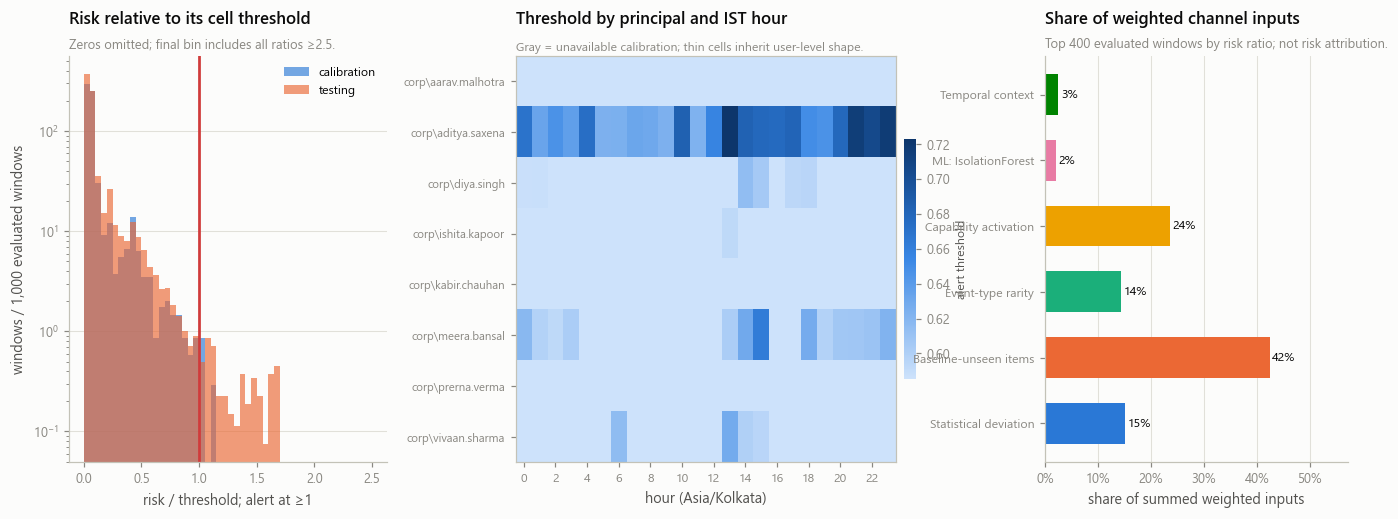

In [73]:
# ---- evaluated populations -----------------------------------------------------
calibration_users = THRESH.attrs["calibration"]["supported_users"]

cal_plot_mask = (
    TR["calibration_eligible"]
    & TR["evaluated"]
    & TR["user"].isin(calibration_users)
)
test_plot_mask = TE["evaluated"].astype(bool)

fig = plt.figure(figsize=(15, 4.8))
gs = fig.add_gridspec(
    1, 3, width_ratios=[1.15, 1.45, 1.1], wspace=0.38
)

# ---- 1. normalized risk-ratio distribution --------------------------------------
ax = fig.add_subplot(gs[0, 0])
bins = np.linspace(0, 2.5, 51)
has_positive_values = False

for frame, mask, color, label in [
    (TR, cal_plot_mask, CAT[0], "calibration"),
    (TE, test_plot_mask, CAT[1], "testing"),
]:
    ratios = frame.loc[mask, "risk_ratio"].to_numpy(dtype=float)

    if not np.isfinite(ratios).all():
        raise ValueError(f"Nonfinite evaluated ratios in {label}.")

    positive = ratios[ratios > 0]
    if len(positive):
        has_positive_values = True
        ax.hist(
            np.clip(positive, 0, 2.5),
            bins=bins,
            weights=np.full(len(positive), 1000.0 / len(ratios)),
            color=color,
            alpha=0.65,
            label=label,
        )

ax.axvline(1.0, color=STATUS["critical"], lw=1.8)
if has_positive_values:
    ax.set_yscale("log")
else:
    ax.text(
        0.5, 0.5, "No positive evaluated ratios",
        transform=ax.transAxes, ha="center", va="center",
    )

finish(
    ax,
    "Risk relative to its cell threshold",
    "Zeros omitted; final bin includes all ratios ≥2.5.",
    xlabel="risk / threshold; alert at ≥1",
    ylabel="windows / 1,000 evaluated windows",
)
handles, labels = ax.get_legend_handles_labels()
if handles:
    ax.legend(fontsize=8)

# ---- 2. threshold surface -------------------------------------------------------
ax = fig.add_subplot(gs[0, 1])
surf = THRESH.unstack().reindex(index=PRINCIPALS, columns=range(24))

cmap = BLUES.copy()
cmap.set_bad("#dddddd")
im = ax.imshow(
    np.ma.masked_invalid(surf.to_numpy(dtype=float)),
    aspect="auto", cmap=cmap,
)
ax.set_yticks(range(len(surf)))
ax.set_yticklabels(surf.index, fontsize=7.5)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels(range(0, 24, 2), fontsize=8)
ax.grid(False)

cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cb.outline.set_visible(False)
cb.set_label("alert threshold", fontsize=8)

ax.set_title(
    "Threshold by principal and IST hour",
    loc="left", color=INK, pad=21,
)
ax.text(
    0, 1.012,
    "Gray = unavailable calibration; thin cells inherit user-level shape.",
    transform=ax.transAxes, color=MUTED, fontsize=8,
)
ax.set_xlabel(f"hour ({BEHAVIOR_TZ})")

# ---- 3. weighted-input shares: not fused-risk contributions ----------------------
ax = fig.add_subplot(gs[0, 2])
top = TE.loc[test_plot_mask].nlargest(400, "risk_ratio")

weighted_inputs = top[list(FULL_W)].mul(pd.Series(FULL_W), axis="columns")
input_totals = weighted_inputs.sum()
total_input = float(input_totals.sum())

if total_input > 0:
    share = input_totals / total_input
    labels = [titles.get(signal, signal) for signal in share.index]

    ax.barh(
        range(len(share)), share.to_numpy(),
        color=[CAT[i % len(CAT)] for i in range(len(share))],
        height=0.62,
    )
    ax.set_yticks(range(len(share)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
    ax.set_xlim(0, min(1.15, float(share.max()) * 1.35))

    for i, value in enumerate(share):
        ax.text(value + 0.005, i, f"{value:.0%}", va="center", fontsize=8)
else:
    ax.text(
        0.5, 0.5, "No positive weighted inputs",
        transform=ax.transAxes, ha="center", va="center",
    )

finish(
    ax,
    "Share of weighted channel inputs",
    f"Top {len(top)} evaluated windows by risk ratio; not risk attribution.",
    xlabel="share of summed weighted inputs",
    xgrid=True,
)

plt.tight_layout()
plt.show()


# ---- explanation lookup integrity ----------------------------------------------
if not np.array_equal(TE["wid"].to_numpy(), DBG["wid"]):
    raise ValueError(
        "TE/debug row order differs. Rerun scoring and downstream cells in order."
    )

if not TE["fit_id"].eq(BASELINE["fit_id"]).all():
    raise ValueError("TE and BASELINE come from different fits.")

if len(TE) != len(Z_TE) or len(TE) != len(ACT_TE):
    raise ValueError("Explanation arrays do not match TE.")

TE_POS = {
    int(wid): position
    for position, wid in enumerate(TE["wid"].to_numpy())
}

TE_LOOKUP = TE.set_index(["user", "win"], verify_integrity=True)

# A narrow lookup table, not another copy of every feature.
explanation_features = list(dict.fromkeys(STAT_FEATURES + ACT_FEATURES))
W_LOOKUP = W[["wid"] + explanation_features].set_index(
    "wid", verify_integrity=True
)

# Store group positions rather than a separate DataFrame per window.
NOV_BY_WIN = NOV_TE.groupby(
    ["user", "win"], observed=True, sort=False
).indices
RARE_BY_WIN = RARE_TE.groupby(
    ["user", "win"], observed=True, sort=False
).indices


def explain(user, win, max_reasons=6):
    """
    Return a decision header and up to one evidence summary per channel.

    delta_risk = risk - risk_without_that_channel.
    These removal effects overlap and must NOT be summed as contributions.
    """
    if not isinstance(max_reasons, int) or max_reasons < 1:
        raise ValueError("max_reasons must be a positive integer.")

    canonical_user = canonical_identity(
        pd.Series([user], dtype="string")
    ).iloc[0]

    if pd.isna(canonical_user):
        raise ValueError("A valid canonical principal is required.")

    timestamp = pd.Timestamp(win)
    if timestamp.tzinfo is None:
        raise ValueError(
            "Supply a timezone-aware window timestamp, for example "
            "'2026-08-04 08:00:00+00:00'."
        )
    timestamp = timestamp.tz_convert("UTC")

    key = (canonical_user, timestamp)
    if key not in TE_LOOKUP.index:
        return None, []

    row = TE_LOOKUP.loc[key]
    wid = int(row["wid"])
    pos = TE_POS[wid]
    observed = W_LOOKUP.loc[wid]

    local_start = timestamp.tz_convert(BEHAVIOR_TZ)
    local_end = (
        timestamp + pd.Timedelta(WINDOW)
    ).tz_convert(BEHAVIOR_TZ)

    header = {
        "user": canonical_user,
        "utc_date": str(row["date"]),
        "window_utc": (
            f"{timestamp:%Y-%m-%d %H:%M %Z} -> "
            f"{timestamp + pd.Timedelta(WINDOW):%Y-%m-%d %H:%M %Z}"
        ),
        "window_local": (
            f"{local_start:%Y-%m-%d %H:%M %Z} -> "
            f"{local_end:%Y-%m-%d %H:%M %Z}"
        ),
        "hour": int(row["hour"]),
        "status": row["status"],
        "decision_reason": row["decision_reason"],
        "evaluated": bool(row["evaluated"]),
        "alert": None if pd.isna(row["alert"]) else bool(row["alert"]),
        "risk_score": float(row["risk_score"]),
        "threshold": float(row["threshold"]),
        "risk_ratio": float(row["risk_ratio"]),
        "risk_level": row["risk_level"],
        "events": int(row["event_count"]),
        "fit_id": row["fit_id"],
        "signals": {
            signal: float(row[signal]) for signal in FULL_W
        },
    }

    if not header["evaluated"]:
        return header, []

    # Ensure explanation calculations reproduce the published fused risk.
    row_frame = row.to_frame().T
    recomputed = float(fuse(row_frame)[0])
    if not np.isclose(recomputed, float(row["risk"]), atol=1e-12, rtol=1e-10):
        raise ValueError("Current weights/signals do not reproduce stored risk.")

    removal_effects = {}
    for signal in FULL_W:
        remaining_weights = {
            name: weight
            for name, weight in FULL_W.items()
            if name != signal
        }
        risk_without = float(fuse_custom(row_frame, remaining_weights)[0])
        removal_effects[signal] = max(0.0, recomputed - risk_without)

    reasons = []

    def add_reason(signal, text):
        if float(row[signal]) <= 0:
            return
        reasons.append({
            "signal": signal,
            "channel_score": float(row[signal]),
            "weighted_input": FULL_W[signal] * float(row[signal]),
            "delta_risk": removal_effects[signal],
            "text": text,
        })

    # Actual top-three severities, including decay and saturation.
    severity = SEV_TE[pos]
    if np.isfinite(severity).all() and row["s_stat"] > 0:
        order = np.argsort(-severity, kind="stable")[:3]
        details = []

        for j, decay in zip(order, (1.0, 0.5, 0.25)):
            if severity[j] <= 0:
                continue

            feature = STAT_FEATURES[j]
            median = np.expm1(
                BASELINE["num"]["med_h"].loc[
                    (canonical_user, int(row["hour"])), feature
                ]
            )
            p95 = np.expm1(
                BASELINE["num"]["p95_h"].loc[
                    (canonical_user, int(row["hour"])), feature
                ]
            )

            details.append(
                f"{feat_text(feature)}={observed[feature]:.0f}, "
                f"baseline median={median:.2f}, P95={p95:.2f}, "
                f"z={Z_TE[pos, j]:.2f}, severity={severity[j]:.3f}, "
                f"decay={decay}"
            )

        add_reason(
            "s_stat",
            f"Compared with this user's supported IST hour "
            f"{int(row['hour']):02d}. " + "; ".join(details),
        )

    novelty_positions = NOV_BY_WIN.get(key)
    if novelty_positions is not None:
        novelty_rows = NOV_TE.iloc[novelty_positions].nlargest(3, "w")
        details = []
        for item in novelty_rows.itertuples(index=False):
            scope = (
                "global reference key absent"
                if item.gcnt == 0
                else f"global reference observations={int(item.gcnt)}"
            )
            details.append(
                f"{ITEM_LABEL[item.itype]}: {item.value} "
                f"({scope}; item evidence weight={item.w:.2f})"
            )
        add_reason(
            "s_nov",
            "Absent from this user's fitted baseline; not necessarily first "
            "use during testing. Top items: " + "; ".join(details),
        )

    activation = ACT_TE[pos]
    if np.isfinite(activation).all() and row["s_act"] > 0:
        details = []
        for j in np.argsort(-activation, kind="stable")[:3]:
            if activation[j] <= 0:
                continue
            feature = ACT_FEATURES[j]
            details.append(
                f"{feat_text(feature)}={observed[feature]:.0f} "
                f"(activation evidence={activation[j]:.2f})"
            )

        add_reason(
            "s_act",
            "These capabilities had maximum zero in this user's eligible "
            f"fitted baseline dates {BASELINE['train_dates'][0]} through "
            f"{BASELINE['train_dates'][-1]}: " + "; ".join(details),
        )

    rarity_positions = RARE_BY_WIN.get(key)
    if rarity_positions is not None:
        rare_rows = RARE_TE.iloc[rarity_positions].nlargest(3, "w")
        details = []
        for item in rare_rows.itertuples(index=False):
            details.append(
                f"{item.event_family}/{int(item.EventID)} "
                f"({event_meaning(item.event_family, item.EventID)}), "
                f"current records={int(item.n)}, "
                f"training user records={int(item.ucnt)}, "
                f"eligible reference records={int(item.gcnt)}"
            )
        add_reason(
            "s_rare",
            "Additive excess user/corpus surprise; not an AND gate. "
            + "; ".join(details),
        )

    add_reason(
        "s_ml",
        f"IsolationForest empirical calibration rank={row['ml_pct']:.6f}; "
        f"tail gate starts at {ML_TAIL_START:.3f}. "
        f"ML fit dates={ML_FIT_DATES}; "
        f"calibration dates={ML_CALIBRATION_DATES}. "
        "This rank is not an attack probability or a feature-level explanation.",
    )

    add_reason(
        "s_temp",
        f"Observed activity on a {row['day_type']} at IST hour "
        f"{int(row['hour']):02d}; smoothed activity rate={row['p_active']:.3f}. "
        f"User-prior fallback used={bool(row['temporal_used_prior'])}.",
    )

    reasons.sort(
        key=lambda reason: (
            reason["delta_risk"], reason["weighted_input"]
        ),
        reverse=True,
    )
    return header, reasons[:max_reasons]

In [74]:
def print_alert(user, win, max_reasons=6):
    header, reasons = explain(user, win, max_reasons)

    if header is None:
        print(
            "No covered test window found for that canonical principal "
            "and exact UTC window start."
        )
        return

    def number(value, decimals=6):
        return (
            f"{value:.{decimals}f}"
            if np.isfinite(value)
            else "UNAVAILABLE"
        )

    print("=" * 100)
    print(f"User       : {header['user']}")
    print(f"UTC window : {header['window_utc']}")
    print(f"IST window : {header['window_local']}")
    print(f"Status     : {header['status']}")
    print(f"Reason     : {header['decision_reason']}")
    print(f"Fit ID     : {header['fit_id']}")
    print(
        f"Risk={number(header['risk_score'])}  "
        f"Threshold={number(header['threshold'])}  "
        f"Ratio={number(header['risk_ratio'])}  "
        f"Band={header['risk_level']}  "
        f"Alert={header['alert']}"
    )
    print(f"Included attributed records: {header['events']}")

    print(
        "Signals: "
        + " | ".join(
            f"{signal}={number(value, 3)}"
            for signal, value in header["signals"].items()
        )
    )

    if not header["evaluated"]:
        print("No alert decision was available; this is not a NORMAL verdict.")
        return

    print("-" * 100)
    print(
        "Reasons ranked by channel-removal effect. "
        "Removal effects overlap and must not be added together."
    )

    if not reasons:
        print("No positive channel evidence.")
    else:
        for i, reason in enumerate(reasons, 1):
            print(
                f"\n{i}. {titles.get(reason['signal'], reason['signal'])}: "
                f"channel={reason['channel_score']:.3f}, "
                f"risk reduction if removed={reason['delta_risk']:.6f}"
            )
            print(textwrap.fill(
                reason["text"],
                width=96,
                initial_indent="   ",
                subsequent_indent="   ",
            ))
    print()


alert_mask = (
    TE["evaluated"]
    & TE["alert"].fillna(False).astype(bool)
)
top_alerts = TE.loc[alert_mask].nlargest(3, "risk_ratio")

if top_alerts.empty:
    print("No evaluated test windows alerted at the calibrated thresholds.")
else:
    for row in top_alerts.itertuples(index=False):
        print_alert(row.user, row.win)

User       : corp\diya.singh
UTC window : 2026-08-24 21:20 UTC -> 2026-08-24 21:30 UTC
IST window : 2026-08-25 02:50 IST -> 2026-08-25 03:00 IST
Status     : ALERT
Reason     : evaluated
Fit ID     : 1a48ba3a54b0e8d7
Risk=0.987829  Threshold=0.585441  Ratio=1.687325  Band=CRITICAL  Alert=True
Included attributed records: 12
Signals: s_stat=0.000 | s_nov=0.608 | s_rare=0.974 | s_act=0.973 | s_ml=0.000 | s_temp=0.381
----------------------------------------------------------------------------------------------------
Reasons ranked by channel-removal effect. Removal effects overlap and must not be added together.

1. Event-type rarity: channel=0.974, risk reduction if removed=0.086753
   Additive excess user/corpus surprise; not an AND gate. sysmon/10 (Process access), current
   records=1, training user records=0, eligible reference records=0; sysmon/8
   (CreateRemoteThread), current records=1, training user records=0, eligible reference
   records=0

2. Capability activation: channel=0

In [75]:
%%requires_ground_truth
from urllib.parse import urlsplit

# ---- read and fingerprint ------------------------------------------------------
gt_bytes = Path(GT_PATH).read_bytes()

if gt_bytes.startswith((b"\xff\xfe", b"\xfe\xff")):
    gt_text = gt_bytes.decode("utf-16")
else:
    gt_text = gt_bytes.decode("utf-8-sig")

GT_SHA256 = hashlib.sha256(gt_bytes).hexdigest()

# Extract exact level-2 sections; nested level-3 headings remain inside them.
section_pattern = re.compile(
    r"^##[ \t]+([^\r\n]+)[ \t]*\r?$",
    flags=re.MULTILINE,
)
section_matches = list(section_pattern.finditer(gt_text))
GT_SECTIONS = {}

for position, match in enumerate(section_matches):
    heading = match.group(1).strip().casefold()
    end = (
        section_matches[position + 1].start()
        if position + 1 < len(section_matches)
        else len(gt_text)
    )
    if heading in GT_SECTIONS:
        raise ValueError(f"Duplicate ground-truth heading: {heading}")
    GT_SECTIONS[heading] = gt_text[match.end():end]

def gt_section(prefix, required=True):
    matches = [
        text for heading, text in GT_SECTIONS.items()
        if heading == prefix.casefold()
        or heading.startswith(prefix.casefold() + " ")
    ]
    if len(matches) > 1:
        raise ValueError(f"Ambiguous ground-truth section: {prefix}")
    if not matches:
        if required:
            raise ValueError(f"Missing ground-truth section: {prefix}")
        return ""
    return matches[0]

timeline_block = gt_section("Timeline")
ioc_block = gt_section("Indicators of Compromise")
red_herring_block = gt_section("Red Herrings", required=False)
summary_block = gt_section("Attack Summary", required=False)

timestamp_pattern = re.compile(
    r"^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2} UTC$"
)

def parse_gt_table(block, table_name):
    rows = []

    for line_number, line in enumerate(block.splitlines(), start=1):
        stripped = line.strip()
        if not stripped.startswith("|"):
            continue

        # Ignore headers/separators, but never silently skip a dated data row.
        if not re.match(r"^\|\s*\d{4}-", stripped):
            continue

        # Split only the first four separators; details may contain pipes.
        fields = stripped.strip("|").split("|", 4)
        if len(fields) != 5:
            raise ValueError(
                f"Malformed {table_name} row at section line {line_number}."
            )
        fields = [field.strip() for field in fields]

        if not timestamp_pattern.fullmatch(fields[0]):
            raise ValueError(
                f"Invalid {table_name} timestamp: {fields[0]!r}"
            )

        rows.append({
            "ts_utc": pd.to_datetime(
                fields[0],
                format="%Y-%m-%d %H:%M:%S UTC",
                utc=True,
                errors="raise",
            ),
            "actor_declared": fields[1],
            "system_declared": fields[2],
            "kind": fields[3],
            "details": fields[4],
            "section_line": line_number,
        })

    return rows


timeline_rows = parse_gt_table(timeline_block, "timeline")
if not timeline_rows:
    raise ValueError("No ground-truth timeline rows were parsed.")

TL = (
    pd.DataFrame(timeline_rows)
    .sort_values(["ts_utc", "section_line"], kind="stable")
    .reset_index(drop=True)
)
TL.index.name = "tl_row"
TL["tl_row"] = TL.index
TL["ts"] = TL["ts_utc"]                # event-time operations stay UTC
TL["win"] = TL["ts_utc"].dt.floor(WINDOW)
TL["date"] = TL["ts_utc"].dt.strftime("%Y-%m-%d")
TL["event_type"] = TL.pop("kind")

# ---- ambiguity-checked identity resolution -------------------------------------
# Includes attributed accounts outside PRINCIPALS so "unscored" is distinguishable
# from "identity unresolved". This lookup is evaluation-only.
evaluation_identity_values = (
    raw["attr_user"].dropna().drop_duplicates().astype("string")
)

identity_frame = pd.DataFrame({"canonical": evaluation_identity_values})
identity_parts = identity_frame["canonical"].str.partition("\\", expand=True)
identity_frame["namespace"] = identity_parts[0]
identity_frame["account"] = identity_parts[2]

identity_frame = identity_frame.loc[
    identity_frame["account"].ne("")
    & identity_frame["namespace"].ne(UNQUALIFIED_NAMESPACE)
]

account_candidates = (
    identity_frame.groupby("account", observed=True)["canonical"]
    .agg(lambda values: tuple(sorted(set(values))))
    .to_dict()
)
canonical_accounts = set(identity_frame["canonical"])

def resolve_gt_identity(value):
    text = str(value).strip().casefold()

    if "\\" in text or "@" in text:
        canonical = canonical_identity(
            pd.Series([text], dtype="string")
        ).iloc[0]
        if pd.notna(canonical) and canonical in canonical_accounts:
            return canonical, "resolved_qualified"
        return None, "qualified_identity_not_observed"

    candidates = account_candidates.get(text, ())
    if len(candidates) == 1:
        return candidates[0], "resolved_unique_account_name"
    if len(candidates) > 1:
        return None, "ambiguous_account_name"
    return None, "account_not_observed"


resolved = [resolve_gt_identity(value) for value in TL["actor_declared"]]
TL["actor"] = pd.Series(
    [value for value, _ in resolved], index=TL.index, dtype="string"
)
TL["identity_status"] = [status for _, status in resolved]

# Host aliases are also resolved only if unique.
host_values = canonical_host(raw["Computer"]).dropna().drop_duplicates()
host_candidates = {}
for host in host_values:
    host_candidates.setdefault(host.split(".", 1)[0], set()).add(host)
host_set = set(host_values)

def resolve_gt_host(value):
    host = str(value).strip().casefold().rstrip(".")
    if host in host_set:
        return host, "resolved_exact"
    candidates = host_candidates.get(host, set())
    if len(candidates) == 1:
        return next(iter(candidates)), "resolved_unique_short_name"
    if len(candidates) > 1:
        return None, "ambiguous_short_hostname"
    return None, "host_not_observed"

resolved_hosts = [resolve_gt_host(value) for value in TL["system_declared"]]
TL["system"] = pd.Series(
    [value for value, _ in resolved_hosts], index=TL.index, dtype="string"
)
TL["host_status"] = [status for _, status in resolved_hosts]

# ---- explicit split status -----------------------------------------------------
TL["split_status"] = np.select(
    [
        TL["date"].isin(TRAIN_DATES),
        TL["date"].isin(TEST_DATES),
    ],
    ["TRAINING_CONTAMINATION", "testing"],
    default="outside_configured_split",
)

if TL["split_status"].eq("TRAINING_CONTAMINATION").any():
    display(TL.loc[TL["split_status"].eq("TRAINING_CONTAMINATION")])
    raise ValueError(
        "Declared attack rows occur in configured training dates. "
        "Investigate benchmark configuration; do not silently move dates."
    )

# ---- red herrings: preserve every occurrence -----------------------------------
rh_data = parse_gt_table(red_herring_block, "red-herring")
RH = pd.DataFrame(
    rh_data,
    columns=[
        "ts_utc", "actor_declared", "system_declared",
        "kind", "details", "section_line",
    ],
)

if RH.empty:
    RH["ts_utc"] = pd.Series(dtype="datetime64[ns, UTC]")
    RH["user"] = pd.Series(dtype="string")
    RH["system"] = pd.Series(dtype="string")
    RH["identity_status"] = pd.Series(dtype="string")
    RH["host_status"] = pd.Series(dtype="string")
else:
    RH["ts_utc"] = pd.to_datetime(RH["ts_utc"], utc=True)
    rh_identities = [resolve_gt_identity(v) for v in RH["actor_declared"]]
    rh_hosts = [resolve_gt_host(v) for v in RH["system_declared"]]

    RH["user"] = pd.array([v for v, _ in rh_identities], dtype="string")
    RH["identity_status"] = [s for _, s in rh_identities]
    RH["system"] = pd.array([v for v, _ in rh_hosts], dtype="string")
    RH["host_status"] = [s for _, s in rh_hosts]

RH["ts"] = RH["ts_utc"]
RH["win"] = RH["ts_utc"].dt.floor(WINDOW)
RH["activity"] = RH.pop("kind")
RH["why_benign"] = RH["details"]

# ---- typed IOC subsections -----------------------------------------------------
IOC_IPS, IOC_DOMAINS, IOC_CMDS = set(), set(), set()
IOC_PROCESS_ENTRIES, IOC_USER_ENTRIES, IOC_FILE_ENTRIES = [], [], []
IOC_UNPARSED_NETWORK = []
ioc_subsection = ""

def add_ioc_host(host):
    host = host.strip().strip("[]").rstrip(".").casefold()
    try:
        address = ipaddress.ip_address(host)
        if isinstance(address, ipaddress.IPv6Address):
            address = address.ipv4_mapped or address
        IOC_IPS.add(str(address))      # retain internal addresses too
    except ValueError:
        normalized = normalize_dns_name(host)
        if normalized:
            IOC_DOMAINS.add(normalized)
        else:
            IOC_UNPARSED_NETWORK.append(host)

for line in ioc_block.splitlines():
    stripped = line.strip()

    if stripped.startswith("### "):
        ioc_subsection = stripped[4:].strip().casefold()
        continue
    if not stripped.startswith("- "):
        continue

    entry = stripped[2:].strip()

    if "network" in ioc_subsection:
        endpoint = entry.split(" (", 1)[0].strip().strip("`")
        try:
            # Supports IP:port, [IPv6]:port, URLs, and hostname:port.
            parsed = urlsplit(
                endpoint if "://" in endpoint else "//" + endpoint
            )
            if parsed.hostname is None:
                raise ValueError("No hostname")
            add_ioc_host(parsed.hostname)
        except ValueError:
            IOC_UNPARSED_NETWORK.append(entry)

    elif "process" in ioc_subsection:
        IOC_PROCESS_ENTRIES.append(entry)
        if entry.startswith("`") and entry.endswith("`"):
            command = entry[1:-1]
            IOC_CMDS.add(command.casefold())

            for url in re.findall(r"https?://[^\s\"'<>`]+", command):
                try:
                    host = urlsplit(url).hostname
                    if host:
                        add_ioc_host(host)
                except ValueError:
                    pass

    elif "user" in ioc_subsection:
        IOC_USER_ENTRIES.append(entry)
    elif "file" in ioc_subsection:
        IOC_FILE_ENTRIES.append(entry)

ATTACK_SUMMARY = [
    line.strip()
    for line in summary_block.splitlines()
    if re.match(r"^\s*\d+\.", line)
]

print(f"Ground truth: {GT_PATH}")
print(f"SHA256: {GT_SHA256}")
print(f"Parsed timeline rows: {len(TL)}")
print(f"Parsed red-herring rows: {len(RH)}")
print(f"Declared numbered summary entries: {len(ATTACK_SUMMARY)}")
print(f"IOC IPs, including internal endpoints: {sorted(IOC_IPS)}")
print(f"IOC domains, including command URLs: {sorted(IOC_DOMAINS)}")
print(f"Command IOC entries: {len(IOC_CMDS)}")

if IOC_UNPARSED_NETWORK:
    print("Unparsed network IOC entries:", IOC_UNPARSED_NETWORK)

display(
    TL.groupby(
        ["split_status", "identity_status"], dropna=False, observed=True
    ).size().rename("timeline_rows").reset_index()
)

print(
    "No labels have been assigned to scored windows yet. "
    "Common executable/IOC membership alone is not an attack label."
)

Ground truth: C:\Users\Aarya.DAS\Downloads\prompt\New folder\GROUND_TRUTH30.md
SHA256: 64e038ab2b2a3e097336e54e34e9f6802fe0f4232fe3c9c4d76bd5274b5405bf
Parsed timeline rows: 231
Parsed red-herring rows: 6
Declared numbered summary entries: 80
IOC IPs, including internal endpoints: ['10.10.10.21', '10.10.10.22', '10.10.10.25', '10.10.10.26', '10.10.10.27', '10.10.10.28', '10.10.20.10', '10.10.20.20', '10.10.20.30', '10.10.20.40', '192.0.2.202', '192.0.2.207', '198.51.100.133', '198.51.100.135', '198.51.100.37']
IOC domains, including command URLs: ['upload-10012.example', 'upload-11015.example', 'upload-21049.example', 'upload-24059.example', 'upload-26068.example']
Command IOC entries: 57


,split_status,identity_status,timeline_rows
0,testing,resolved_unique_account_name,231


No labels have been assigned to scored windows yet. Common executable/IOC membership alone is not an attack label.


In [77]:
%%requires_ground_truth

# ---- spray summaries -----------------------------------------------------------
spray_mask = TL["event_type"].str.contains(
    "spray", case=False, na=False
)

# Explicit evaluation-matching assumptions, not detector settings.
SPRAY_START_TOLERANCE = pd.Timedelta("2s")
SPRAY_MAX_DURATION = pd.Timedelta("30min")

SPRAY_EVIDENCE = {}
spray_audit_rows = []

for tl_id, row in TL.loc[spray_mask].iterrows():
    declared_counts = re.search(
        r"(\d+)\s+attempts\s+against\s+(\d+)\s+accounts",
        row["details"],
        flags=re.IGNORECASE,
    )
    declared_success = re.search(
        r"success:\s*([^\s,)]+)\s+at\s+attempt\s+(\d+)",
        row["details"],
        flags=re.IGNORECASE,
    )

    audit = {
        "tl_row": int(tl_id),
        "ts_utc": row["ts_utc"],
        "host": row["system"],
        "status": "unresolved",
        "reason": "",
        "candidate_bursts": 0,
        "matched_records": 0,
    }

    if pd.isna(row["system"]):
        audit["reason"] = "unresolved_scenario_host"
        spray_audit_rows.append(audit)
        continue

    if not declared_counts:
        audit["reason"] = "summary_has_no_parseable_attempt_account_counts"
        spray_audit_rows.append(audit)
        continue

    expected_attempts = int(declared_counts.group(1))
    expected_accounts = int(declared_counts.group(2))

    if expected_attempts <= 0 or expected_accounts <= 0:
        audit["reason"] = "invalid_declared_counts"
        spray_audit_rows.append(audit)
        continue

    expected_success_user = None
    expected_success_position = None

    if declared_success:
        expected_success_user, success_resolution = resolve_gt_identity(
            declared_success.group(1)
        )
        expected_success_position = int(declared_success.group(2))
        if expected_success_user is None:
            audit["reason"] = "declared_success_target_identity_unresolved"
            spray_audit_rows.append(audit)
            continue

    t0 = row["ts_utc"]
    auth_mask = (
        raw["event_family"].eq("security")
        & raw["EventID"].isin([4624, 4625])
        & raw["ts_utc"].ge(t0 - SPRAY_START_TOLERANCE)
        & raw["ts_utc"].lt(t0 + SPRAY_MAX_DURATION)
    )

    # Filter Series separately to avoid wide raw-table consolidation.
    selected_idx = raw.index[auth_mask]
    columns = [
        "ts_utc", "Computer", "EventID", "IpAddress",
        "TargetUserName", "TargetDomainName",
    ]
    auth = pd.DataFrame({
        column: raw[column].loc[selected_idx].copy()
        for column in columns
    }, copy=False)

    auth["host"] = canonical_host(auth["Computer"])
    auth = auth.loc[auth["host"].eq(row["system"])].copy()
    auth["src_ip"] = clean_ip(auth["IpAddress"])
    auth["user"] = canonical_identity(
        auth["TargetUserName"], auth["TargetDomainName"]
    )
    auth = auth.dropna(subset=["src_ip", "user"])

    # If a source is explicitly declared, use it. Otherwise require a unique
    # burst matching the declared counts/timing/success pattern.
    source_match = re.search(
        r"\b(?:from|source(?:\s+ip)?)\s*[:=]?\s*"
        r"(\d{1,3}(?:\.\d{1,3}){3})",
        row["details"], flags=re.IGNORECASE,
    )
    if source_match:
        source_value = normalize_ip(
            pd.Series([source_match.group(1)], dtype="string")
        ).iloc[0]
        auth = auth.loc[auth["src_ip"].eq(source_value)]

    candidates = []

    for source_ip, source_rows in auth.groupby("src_ip", observed=True):
        source_rows = source_rows.sort_values("ts_utc", kind="stable")

        possible_starts = np.flatnonzero(
            source_rows["ts_utc"]
            .sub(t0).abs().le(SPRAY_START_TOLERANCE)
            .to_numpy()
        )

        for start_position in possible_starts:
            burst = source_rows.iloc[
                start_position:start_position + expected_attempts
            ].copy()

            if len(burst) != expected_attempts:
                continue
            if burst["user"].nunique() != expected_accounts:
                continue

            # Do not accept an unresolved account namespace as a known victim.
            if burst["user"].str.startswith(
                UNQUALIFIED_NAMESPACE + "\\", na=False
            ).any():
                continue

            if declared_success:
                position = expected_success_position - 1
                if not 0 <= position < len(burst):
                    continue

                success_rows = burst["EventID"].eq(4624)
                if int(success_rows.sum()) != 1:
                    continue
                if not bool(success_rows.iloc[position]):
                    continue
                if burst["user"].iloc[position] != expected_success_user:
                    continue

            candidates.append(burst)

    # Collapse duplicate candidate row sets, not distinct plausible bursts.
    unique_candidates = {}
    for candidate in candidates:
        unique_candidates[tuple(candidate.index)] = candidate

    audit["candidate_bursts"] = len(unique_candidates)

    if len(unique_candidates) == 1:
        evidence = next(iter(unique_candidates.values())).copy()
        evidence["win"] = evidence["ts_utc"].dt.floor(WINDOW)
        evidence["tl_row"] = int(tl_id)

        SPRAY_EVIDENCE[int(tl_id)] = evidence[
            ["tl_row", "ts_utc", "win", "host", "src_ip", "user", "EventID"]
        ]
        audit["status"] = "unique_data_assisted_match"
        audit["reason"] = "declared_counts_timing_and_success_pattern"
        audit["matched_records"] = len(evidence)

    elif len(unique_candidates) == 0:
        audit["reason"] = "no_burst_satisfies_declared_constraints"
    else:
        audit["reason"] = "multiple_plausible_bursts"

    spray_audit_rows.append(audit)

SPRAY_AUDIT = pd.DataFrame(
    spray_audit_rows,
    columns=[
        "tl_row", "ts_utc", "host", "status", "reason",
        "candidate_bursts", "matched_records",
    ],
)
print("Spray evidence audit:")
display(SPRAY_AUDIT)

print(
    "A unique match is data-assisted evaluation evidence, not independent "
    "proof of maliciousness. Unresolved spray rows remain in the scenario audit."
)

# ---- episodes: explicitly heuristic, never claimed to be original attack IDs ----
EPISODE_GAP = pd.Timedelta("12min")
episode_clusters = []

# Group by declared actor AND declared system to avoid cross-host merging.
for _, group in TL.groupby(
    ["actor_declared", "system_declared"],
    observed=True, dropna=False, sort=False,
):
    group = group.sort_values("ts_utc", kind="stable")
    cluster = []
    previous_time = None

    for tl_id, row in group.iterrows():
        if (
            previous_time is not None
            and row["ts_utc"] - previous_time > EPISODE_GAP
        ):
            episode_clusters.append(cluster)
            cluster = []

        cluster.append(int(tl_id))
        previous_time = row["ts_utc"]

    if cluster:
        episode_clusters.append(cluster)

episode_rows = []

for timeline_ids in episode_clusters:
    group = TL.loc[timeline_ids]
    users = set(group["actor"].dropna())
    unresolved_spray_rows = []

    # Replace the summary's SYSTEM actor with evidence-supported targets,
    # but retain unresolved spray episodes with an empty target list.
    if group.index.isin(TL.index[spray_mask]).any():
        ordinary = group.loc[~group.index.isin(TL.index[spray_mask])]
        users = set(ordinary["actor"].dropna())

        for tl_id in group.index[group.index.isin(TL.index[spray_mask])]:
            evidence = SPRAY_EVIDENCE.get(int(tl_id))
            if evidence is None:
                unresolved_spray_rows.append(int(tl_id))
            else:
                users.update(evidence["user"])

    start = group["ts_utc"].min()
    end = group["ts_utc"].max() + pd.Timedelta("1s")

    for tl_id in timeline_ids:
        evidence = SPRAY_EVIDENCE.get(tl_id)
        if evidence is not None and not evidence.empty:
            start = min(start, evidence["ts_utc"].min())
            end = max(end, evidence["ts_utc"].max() + pd.Timedelta("1ns"))

    episode_rows.append({
        "users": sorted(users),
        "start": start,
        "end": end,
        "systems": sorted(set(group["system"].dropna())),
        "declared_systems": sorted(set(group["system_declared"])),
        "types": sorted(set(group["event_type"])),
        "n_timeline_rows": len(group),
        "tl_rows": sorted(timeline_ids),
        "unresolved_spray_rows": unresolved_spray_rows,
        "desc": "; ".join(sorted(set(group["event_type"]))),
        "episode_method": "actor_host_gap_heuristic",
    })

EP = (
    pd.DataFrame(episode_rows)
    .sort_values("start", kind="stable")
    .reset_index(drop=True)
)
EP.insert(0, "step", np.arange(1, len(EP) + 1))

# Explicit provenance: each timeline row belongs to exactly one episode.
TL_TO_STEP = {}
for episode in EP.itertuples(index=False):
    for tl_id in episode.tl_rows:
        if tl_id in TL_TO_STEP:
            raise ValueError("Timeline row assigned to multiple episodes.")
        TL_TO_STEP[tl_id] = int(episode.step)

assert set(TL_TO_STEP) == set(TL.index)
TL["step"] = TL.index.map(TL_TO_STEP)

print(f"\nHeuristic episodes reconstructed: {len(EP)}")
print(f"Numbered attack-summary entries: {len(ATTACK_SUMMARY)}")
print(
    "These are different units. Matching counts would not establish an exact "
    "episode mapping. Window-level labels remain the primary evaluation."
)

display(
    EP[
        [
            "step", "start", "end", "users", "declared_systems",
            "n_timeline_rows", "tl_rows", "unresolved_spray_rows", "desc",
        ]
    ]
)

C:\Users\Aarya.DAS\AppData\Local\Temp\ipykernel_13908\1752122526.py:187: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  normalized.map(allowed).fillna(False).astype(bool)
C:\Users\Aarya.DAS\AppData\Local\Temp\ipykernel_13908\1752122526.py:187: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  normalized.map(allowed).fillna(False).astype(bool)


Spray evidence audit:


C:\Users\Aarya.DAS\AppData\Local\Temp\ipykernel_13908\1752122526.py:187: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  normalized.map(allowed).fillna(False).astype(bool)


,tl_row,ts_utc,host,status,reason,candidate_bursts,matched_records
0,53,2026-08-09 11:10:08+00:00,dc-01.corp.local,unique_data_assisted_match,declared_counts_timing_and_success_pattern,1,9
1,131,2026-08-16 15:00:15+00:00,dc-01.corp.local,unique_data_assisted_match,declared_counts_timing_and_success_pattern,1,9
2,200,2026-08-23 08:10:20+00:00,dc-01.corp.local,unique_data_assisted_match,declared_counts_timing_and_success_pattern,1,9


A unique match is data-assisted evaluation evidence, not independent proof of maliciousness. Unresolved spray rows remain in the scenario audit.

Heuristic episodes reconstructed: 80
Numbered attack-summary entries: 80
These are different units. Matching counts would not establish an exact episode mapping. Window-level labels remain the primary evaluation.


,step,start,end,users,declared_systems,n_timeline_rows,tl_rows,unresolved_spray_rows,desc
0,1,2026-08-04 07:59:35+00:00,2026-08-04 08:00:10+00:00,[corp\prerna.verma],[FILE-01],2,"[0, 1]",[],Process; Service_Installed
1,2,2026-08-04 16:19:58+00:00,2026-08-04 16:20:50+00:00,[corp\vivaan.sharma],[PC-003],4,"[2, 3, 4, 5]",[],Process
2,3,2026-08-04 20:39:45+00:00,2026-08-04 20:40:11+00:00,[corp\prerna.verma],[FILE-01],2,"[6, 7]",[],Process; Service_Installed
3,4,2026-08-05 03:59:55+00:00,2026-08-05 04:00:07+00:00,[corp\aarav.malhotra],[PC-002],2,"[8, 9]",[],Process; Scheduled_Task_Created
4,5,2026-08-05 12:59:40+00:00,2026-08-05 13:00:07+00:00,[corp\aditya.saxena],[DC-01],3,"[10, 11, 12]",[],Account_Created; Group_Member_Added; Process
...,...,...,...,...,...,...,...,...,...
75,76,2026-08-25 17:59:36+00:00,2026-08-25 18:00:17+00:00,[corp\meera.bansal],[FILE-01],3,"[216, 217, 218]",[],Connection; Logon; Process
76,77,2026-08-25 22:00:17+00:00,2026-08-25 22:01:44+00:00,[corp\ishita.kapoor],[PC-001],5,"[219, 220, 221, 222, 223]",[],Connection; Process
77,78,2026-08-26 08:59:52+00:00,2026-08-26 09:00:14+00:00,[corp\aditya.saxena],[DC-01],2,"[224, 225]",[],Log_Cleared; Process
78,79,2026-08-26 15:40:08+00:00,2026-08-26 15:40:53+00:00,[corp\prerna.verma],[DC-01],3,"[226, 227, 228]",[],Account_Created; Group_Member_Added; Process


In [78]:
%%requires_ground_truth

# ---- policy --------------------------------------------------------------------
# Primary evaluation uses exact UTC windows.
# Spray labels use only the audited evidence from Cell 41.
# Unresolved timeline identity: exclude its exact window from negative evaluation.
# Unresolved spray: conservatively exclude the declared search interval from
# negative evaluation, since affected principals cannot be established.
#
# Exclusions are explicitly reported. They are not successful detections.

if BEACON_EXPANSION:
    raise ValueError(
        "This primary evaluator uses exact timeline windows. "
        "Set BEACON_EXPANSION=False. Duration-based expansion requires "
        "a separately validated labeling protocol."
    )

SKIP_RE = re.compile(r"no evidence emitted", re.IGNORECASE)

if not TE["wid"].is_unique:
    raise ValueError("Duplicate test window IDs.")
if TE.duplicated(["user", "win"]).any():
    raise ValueError("Duplicate test principal/window keys.")
if set(TL_TO_STEP) != set(TL.index):
    raise ValueError("Incomplete timeline-to-episode mapping.")

label_rows = []
audit_rows = []
uncertain_intervals = []

def add_label(tl_id, user, timestamp, source, evidence_status):
    timestamp = pd.Timestamp(timestamp).tz_convert("UTC")
    label_rows.append({
        "tl_row": int(tl_id),
        "step": int(TL_TO_STEP[tl_id]),
        "source": source,
        "user": user,
        "win": timestamp.floor(WINDOW),
        "ts": timestamp,
        "evidence_status": evidence_status,
    })

for tl_id, row in TL.iterrows():
    audit = {
        "tl_row": int(tl_id),
        "step": int(TL_TO_STEP[tl_id]),
        "ts_utc": row["ts_utc"],
        "actor_declared": row["actor_declared"],
        "actor": row["actor"],
        "system_declared": row["system_declared"],
        "event_type": row["event_type"],
        "split_status": row["split_status"],
        "label_resolution": "",
        "reason": "",
    }

    if row["split_status"] != "testing":
        audit["label_resolution"] = "outside_test_period"
        audit["reason"] = row["split_status"]
        audit_rows.append(audit)
        continue

    if bool(spray_mask.loc[tl_id]):
        evidence = SPRAY_EVIDENCE.get(int(tl_id))

        if evidence is None or evidence.empty:
            audit["label_resolution"] = "unresolved"
            audit["reason"] = "spray_victims_not_uniquely_recovered"

            uncertain_intervals.append({
                "tl_row": int(tl_id),
                "start": row["ts_utc"] - SPRAY_START_TOLERANCE,
                "end": row["ts_utc"] + SPRAY_MAX_DURATION,
                "reason": audit["reason"],
            })
        else:
            # Preserve all recovered targets, including unscored principals.
            for (user, win), group in evidence.groupby(
                ["user", "win"], observed=True, sort=False
            ):
                add_label(
                    tl_id, user, group["ts_utc"].min(),
                    "spray", "unique_data_assisted_match",
                )

            audit["label_resolution"] = "resolved"
            audit["reason"] = "audited_data_assisted_spray_evidence"

        audit_rows.append(audit)
        continue

    if pd.isna(row["actor"]):
        audit["label_resolution"] = "unresolved"
        audit["reason"] = row["identity_status"]

        uncertain_intervals.append({
            "tl_row": int(tl_id),
            "start": row["win"],
            "end": row["win"] + pd.Timedelta(WINDOW),
            "reason": audit["reason"],
        })
        audit_rows.append(audit)
        continue

    # Keep declared attacks even when "no evidence emitted" is stated.
    # They may be pipeline misses; do not remove them to improve recall.
    evidence_status = (
        "declared_no_evidence_emitted"
        if SKIP_RE.search(str(row["details"]))
        else "declared_timeline"
    )
    add_label(
        tl_id, row["actor"], row["ts_utc"],
        "timeline", evidence_status,
    )
    audit["label_resolution"] = "resolved"
    audit["reason"] = evidence_status
    audit_rows.append(audit)


# ---- explicit schema, including an empty-label case -----------------------------
LABELS = pd.DataFrame(
    label_rows,
    columns=[
        "tl_row", "step", "source", "user", "win", "ts", "evidence_status",
    ],
)
LABELS["user"] = LABELS["user"].astype("string")
LABELS["win"] = pd.to_datetime(LABELS["win"], utc=True)
LABELS["ts"] = pd.to_datetime(LABELS["ts"], utc=True)
LABELS["tl_row"] = LABELS["tl_row"].astype("int64")
LABELS["step"] = LABELS["step"].astype("int64")

TIMELINE_AUDIT = pd.DataFrame(audit_rows)
assert len(TIMELINE_AUDIT) == len(TL)
assert TIMELINE_AUDIT["tl_row"].is_unique

# Source priority is for presentation only, not strength of evidence.
PRIORITY = {"timeline": 0, "spray": 1}

if LABELS.empty:
    CELLS_ALL = pd.DataFrame({
        "user": pd.Series(dtype="string"),
        "win": pd.Series(dtype="datetime64[ns, UTC]"),
        "source": pd.Series(dtype="string"),
        "sources": pd.Series(dtype=object),
        "steps": pd.Series(dtype=object),
        "tl_rows": pd.Series(dtype=object),
    })
else:
    CELLS_ALL = (
        LABELS.assign(_priority=LABELS["source"].map(PRIORITY))
        .sort_values("_priority", kind="stable")
        .groupby(["user", "win"], observed=True, sort=False)
        .agg(
            source=("source", "first"),
            sources=("source", lambda values: sorted(set(values))),
            steps=("step", lambda values: sorted(set(map(int, values)))),
            tl_rows=("tl_row", lambda values: sorted(set(map(int, values)))),
        )
        .reset_index()
    )

assert not CELLS_ALL.duplicated(["user", "win"]).any()

# ---- classify positive-cell availability ----------------------------------------
CELLS_ALL = CELLS_ALL.merge(
    TE[
        [
            "user", "win", "wid", "event_count", "evaluated",
            "status", "decision_reason",
        ]
    ],
    on=["user", "win"],
    how="left",
    validate="one_to_one",
    indicator="_test_join",
)

has_test_row = CELLS_ALL["_test_join"].eq("both")
evaluated_positive = (
    CELLS_ALL["evaluated"]
    .astype("boolean").fillna(False).astype(bool)
)

CELLS_ALL["availability"] = "no_covered_scored_window"
CELLS_ALL.loc[
    ~CELLS_ALL["user"].isin(PRINCIPALS), "availability"
] = "principal_not_baselined"
CELLS_ALL.loc[
    has_test_row & ~evaluated_positive, "availability"
] = "covered_but_unrated"
CELLS_ALL.loc[
    has_test_row & evaluated_positive, "availability"
] = "evaluated"

CELLS_ALL = CELLS_ALL.drop(columns="_test_join")

# ---- attach known labels to TE --------------------------------------------------
TE["win_end"] = TE["win"] + pd.Timedelta(WINDOW)

te_keys = pd.MultiIndex.from_frame(TE[["user", "win"]])
positive_keys = pd.MultiIndex.from_frame(CELLS_ALL[["user", "win"]])
known_positive = te_keys.isin(positive_keys)

uncertain_mask = np.zeros(len(TE), dtype=bool)
for interval in uncertain_intervals:
    # All principals are conservatively affected because victims are unresolved.
    uncertain_mask |= (
        TE["win"].lt(interval["end"])
        & TE["win_end"].gt(interval["start"])
    ).to_numpy(dtype=bool)

TE["is_attack"] = pd.Series(
    known_positive, index=TE.index, dtype="boolean"
)

# A known positive remains positive even if another unresolved episode overlaps.
TE.loc[uncertain_mask & ~known_positive, "is_attack"] = pd.NA

TE["label_status"] = "assumed_benign_under_synthetic_ground_truth"
TE.loc[known_positive, "label_status"] = "known_positive"
TE.loc[
    uncertain_mask & ~known_positive, "label_status"
] = "unresolved_ground_truth_overlap"

steps_by_cell = {
    (row.user, row.win): row.steps
    for row in CELLS_ALL.itertuples(index=False)
}
TE["attack_steps"] = [
    list(steps_by_cell.get((user, win), []))
    for user, win in zip(TE["user"], TE["win"])
]

# ---- exact red-herring windows --------------------------------------------------
TE["is_red_herring"] = False
rh_audit_rows = []

for rh_id, row in RH.iterrows():
    if pd.isna(row["user"]):
        rh_audit_rows.append({
            "rh_row": rh_id,
            "status": "identity_unresolved",
        })
        continue

    match = (
        TE["user"].eq(row["user"])
        & TE["win"].eq(row["win"])
    )
    TE.loc[match, "is_red_herring"] = True
    rh_audit_rows.append({
        "rh_row": rh_id,
        "status": (
            "covered_window_found" if match.any()
            else "no_covered_scored_window"
        ),
    })

RH_AUDIT = pd.DataFrame(rh_audit_rows)

TE["red_herring_context"] = "not_marked"
TE.loc[TE["is_red_herring"], "red_herring_context"] = "benign_context"
TE.loc[
    TE["is_red_herring"] & TE["is_attack"].fillna(False),
    "red_herring_context",
] = "mixed_attack_and_benign_context"
TE.loc[
    TE["is_red_herring"] & TE["is_attack"].isna(),
    "red_herring_context",
] = "unknown_label_with_benign_context"

# ---- one explicit discrimination/decision population ----------------------------
# ACTIVE is retained for compatibility; it includes evaluated quiet windows.
ACTIVE = TE.loc[
    TE["evaluated"] & TE["is_attack"].notna()
].copy()
ACTIVE["is_attack"] = ACTIVE["is_attack"].astype(bool)

CELLS = CELLS_ALL.loc[
    CELLS_ALL["availability"].eq("evaluated")
].copy()

N_USER_DAYS_TEST = len(ACTIVE) / WINDOWS_PER_DAY

if ACTIVE.empty:
    raise ValueError("No evaluated windows with known ground-truth labels.")

assert not ACTIVE.duplicated(["user", "win"]).any()
assert int(ACTIVE["is_attack"].sum()) == len(CELLS)
assert ACTIVE["date"].isin(TEST_DATES).all()
assert ACTIVE["alert"].notna().all()

# Compatibility: counts label mappings, NOT raw malicious event records.
episode_label_rows = {
    int(step): int(LABELS["step"].eq(step).sum())
    for step in EP["step"]
}
episode_evidence = episode_label_rows.copy()

unresolved_audit = TIMELINE_AUDIT.loc[
    TIMELINE_AUDIT["label_resolution"].eq("unresolved")
]
UNRESOLVED_GT_INTERVALS = pd.DataFrame(
    uncertain_intervals,
    columns=["tl_row", "start", "end", "reason"],
)

print("Exact UTC principal/window labels")
print(f"Timeline rows audited                  : {len(TIMELINE_AUDIT)}")
print(f"Unresolved timeline rows               : {len(unresolved_audit)}")
print(f"Known positive cells, all availability : {len(CELLS_ALL)}")
print(f"Known positive cells evaluated         : {len(CELLS)}")
print(
    "Known positive cells not evaluated    : "
    f"{int(CELLS_ALL.availability.ne('evaluated').sum())}"
)
print(
    "Covered windows excluded for unknown labels: "
    f"{int(TE.is_attack.isna().sum())}"
)
print(f"Evaluated known-label population       : {len(ACTIVE):,}")
print(f"Evaluation exposure                    : {N_USER_DAYS_TEST:.3f} user-days")

print("\nPositive-cell availability:")
display(
    CELLS_ALL["availability"].value_counts()
    .rename("positive_cells").to_frame()
)

print("\nTimeline audit:")
display(
    TIMELINE_AUDIT.groupby(
        ["label_resolution", "reason"], dropna=False, observed=True
    ).size().rename("timeline_rows").reset_index()
)

if not unresolved_audit.empty:
    print("\nUnresolved scenario rows — not successful detections:")
    display(unresolved_audit)

if not CELLS.empty:
    print("\nEvaluated positives by principal and presentation source:")
    display(
        CELLS.pivot_table(
            index="user", columns="source", values="win",
            aggfunc="count", fill_value=0,
        )
    )

print(
    "\nUnlisted windows are treated as benign only under the synthetic "
    "ground-truth completeness assumption. Window metrics are conditional on "
    "the evaluated known-label population; they do not replace the complete "
    "scenario availability/unresolved audit."
)

Exact UTC principal/window labels
Timeline rows audited                  : 231
Unresolved timeline rows               : 0
Known positive cells, all availability : 139
Known positive cells evaluated         : 139
Known positive cells not evaluated    : 0
Covered windows excluded for unknown labels: 0
Evaluated known-label population       : 26,496
Evaluation exposure                    : 184.000 user-days

Positive-cell availability:


,positive_cells
availability,
evaluated,139



Timeline audit:


,label_resolution,reason,timeline_rows
0,resolved,audited_data_assisted_spray_evidence,3
1,resolved,declared_timeline,228



Evaluated positives by principal and presentation source:


source,spray,timeline
user,,
corp\aarav.malhotra,3,12
corp\aditya.saxena,3,25
corp\diya.singh,3,7
corp\ishita.kapoor,3,14
corp\kabir.chauhan,3,9
corp\meera.bansal,3,8
corp\prerna.verma,3,28
corp\vivaan.sharma,3,12



Unlisted windows are treated as benign only under the synthetic ground-truth completeness assumption. Window metrics are conditional on the evaluated known-label population; they do not replace the complete scenario availability/unresolved audit.


In [79]:
%%requires_ground_truth

y = ACTIVE["is_attack"].to_numpy(dtype=bool)
has_positive = bool(y.any())
has_negative = bool((~y).any())

print("DISCRIMINATION — evaluated windows with known labels")
print(f"Positive windows : {int(y.sum()):,}")
print(f"Total windows    : {len(y):,}")
print(f"Prevalence       : {y.mean():.3%}")
print(
    "Includes evaluated quiet windows. Unrated and unresolved-label windows "
    "are reported separately in Cell 42."
)

def discrimination_row(label, scores):
    scores = np.asarray(scores, dtype=float)

    if len(scores) != len(y):
        raise ValueError(f"Score/label length mismatch: {label}")
    if not np.isfinite(scores).all():
        raise ValueError(f"Unavailable scores in evaluated population: {label}")

    return {
        "model": label,
        "Average Precision": (
            average_precision_score(y, scores)
            if has_positive else np.nan
        ),
        "ROC-AUC": (
            roc_auc_score(y, scores)
            if has_positive and has_negative else np.nan
        ),
    }

rows = []

for column, label in [
    ("s_stat", "Statistical channel"),
    ("s_nov", "Novelty channel"),
    ("s_act", "Capability activation channel"),
    ("s_rare", "Event-type rarity channel"),
    ("s_ml", "IsolationForest deployed tail gate"),
    ("s_temp", "Temporal channel"),
    ("risk_score", "Fused operational risk"),
    ("risk_ratio", "Fused risk / cell threshold"),
]:
    rows.append(discrimination_row(
        label, ACTIVE[column].to_numpy(dtype=float)
    ))

# ML raw rankings are evaluated before the deployed tail gate.
# Align by wid, not by ACTIVE's current index position.
if not np.array_equal(TE["wid"].to_numpy(), DBG["wid"]):
    raise ValueError("TE row order changed since scoring; rebuild ML outputs.")

for name, (_, test_raw_scores) in ML_RAW_SCORES.items():
    if len(test_raw_scores) != len(TE):
        raise ValueError(f"ML output length mismatch: {name}")

    score_lookup = pd.Series(
        np.asarray(test_raw_scores, dtype=float),
        index=TE["wid"].to_numpy(),
    )
    aligned_scores = ACTIVE["wid"].map(score_lookup).to_numpy(dtype=float)

    rows.append(discrimination_row(
        f"[ML raw ranking] {name}", aligned_scores
    ))

DISCRIMINATION = pd.DataFrame(rows).set_index("model")
display(DISCRIMINATION.round(4))

if not has_positive:
    print("Average Precision unavailable: no positive labels in this population.")
if not (has_positive and has_negative):
    print("ROC-AUC unavailable: both label classes are required.")

print(
    "Average Precision is not trapezoidal PR-AUC. These are descriptive "
    "test results—not permission to tune thresholds on the same labels."
)

DISCRIMINATION — evaluated windows with known labels
Positive windows : 139
Total windows    : 26,496
Prevalence       : 0.525%
Includes evaluated quiet windows. Unrated and unresolved-label windows are reported separately in Cell 42.


,Average Precision,ROC-AUC
model,,
Statistical channel,0.0072,0.5240
Novelty channel,0.3836,0.8131
Capability activation channel,0.7282,0.8738
Event-type rarity channel,0.3000,0.6503
IsolationForest deployed tail gate,0.0053,0.5005
Temporal channel,0.0101,0.6960
Fused operational risk,0.7205,0.9590
Fused risk / cell threshold,0.7188,0.9576
[ML raw ranking] IsolationForest,0.0156,0.7869


Average Precision is not trapezoidal PR-AUC. These are descriptive test results—not permission to tune thresholds on the same labels.


In [84]:
%%requires_ground_truth

if ACTIVE.empty:
    raise ValueError("No evaluated, known-label windows.")

if ACTIVE["is_attack"].isna().any() or ACTIVE["alert"].isna().any():
    raise ValueError("ACTIVE contains unavailable labels or decisions.")

if not ACTIVE["evaluated"].all():
    raise ValueError("ACTIVE includes unevaluated windows.")

# Recompute locally; do not rely on a previous metrics cell's y.
y = ACTIVE["is_attack"].to_numpy(dtype=bool)
N_USER_DAYS_TEST = len(ACTIVE) / WINDOWS_PER_DAY

known_positive_total = len(CELLS_ALL)
known_positive_not_evaluated = int(
    CELLS_ALL["availability"].ne("evaluated").sum()
)

test_episode_ids = set(
    TL.loc[TL["split_status"].eq("testing"), "step"].astype(int)
)
evaluable_episode_ids = {
    int(step)
    for steps in CELLS["steps"]
    for step in steps
}

def safe_ratio(numerator, denominator):
    return numerator / denominator if denominator > 0 else np.nan

def sweep(mult):
    """
    Diagnostic threshold multiplier.

    The absolute threshold floor is retained even when mult < 1.
    mult=1 exactly reproduces the deployed operating point.
    This function does not modify TE, THRESH, or any model.
    """
    mult = float(mult)
    if not np.isfinite(mult) or mult <= 0:
        raise ValueError("Threshold multiplier must be finite and positive.")

    effective_threshold = np.maximum(
        THRESHOLD_FLOOR,
        mult * ACTIVE["threshold"].to_numpy(dtype=float),
    )
    predicted = (
        ACTIVE["risk_score"].to_numpy(dtype=float) >= effective_threshold
    )

    tp = int(np.count_nonzero(predicted & y))
    fp = int(np.count_nonzero(predicted & ~y))
    fn = int(np.count_nonzero(~predicted & y))
    tn = int(np.count_nonzero(~predicted & ~y))

    precision = safe_ratio(tp, tp + fp)
    recall = safe_ratio(tp, tp + fn)
    specificity = safe_ratio(tn, tn + fp)
    f1 = safe_ratio(2 * tp, 2 * tp + fp + fn)

    # Only true-positive cells can provide episode-detection credit.
    detected_steps = {
        int(step)
        for steps in ACTIVE.loc[predicted & y, "attack_steps"]
        for step in steps
    }
    if not detected_steps.issubset(test_episode_ids):
        raise ValueError("Detected step IDs are inconsistent with test episodes.")

    # Separate clean benign red-herring alerts from mixed attack contexts.
    red_herring = ACTIVE["is_red_herring"].to_numpy(dtype=bool)

    return {
        "threshold x": mult,
        "alerts": int(predicted.sum()),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "F1": f1,
        "accuracy": (tp + tn) / len(ACTIVE),
        "balanced_acc": (
            0.5 * (recall + specificity)
            if np.isfinite(recall) and np.isfinite(specificity)
            else np.nan
        ),
        "steps_detected": (
            f"{len(detected_steps)}/{len(test_episode_ids)}"
        ),
        "evaluable_steps_detected": (
            f"{len(detected_steps)}/{len(evaluable_episode_ids)}"
        ),
        "FP/user/day": fp / N_USER_DAYS_TEST,
        "red_herring_alerts": int(
            np.count_nonzero(predicted & red_herring & ~y)
        ),
        "mixed_attack_red_herring_alerts": int(
            np.count_nonzero(predicted & red_herring & y)
        ),
        "known_positive_cells_not_evaluated": known_positive_not_evaluated,
        "known_cell_pipeline_recall": safe_ratio(tp, known_positive_total),
        "known_cells_without_alert": fn + known_positive_not_evaluated,
    }


OP = sweep(1.0)

# The operating point must reproduce actual published decisions.
assert OP["alerts"] == int(ACTIVE["alert"].astype(bool).sum())
assert OP["TP"] + OP["FN"] == len(CELLS)
assert OP["TP"] + OP["FP"] + OP["FN"] + OP["TN"] == len(ACTIVE)
assert OP["TP"] <= known_positive_total

print("=" * 88)
print("OPERATING POINT — evaluated windows with known labels")
print("=" * 88)

for key, value in OP.items():
    if key == "threshold x":
        continue
    if isinstance(value, str):
        formatted = value
    elif isinstance(value, (float, np.floating)):
        formatted = f"{value:.4f}" if np.isfinite(value) else "UNDEFINED"
    else:
        formatted = str(value)
    print(f"  {key:<39} {formatted}")

print(f"\nEvaluation exposure: {N_USER_DAYS_TEST:.3f} user-days")
print(
    "Episode counts use the actor/host/gap heuristic, not verified original "
    "scenario episode IDs."
)
print(
    "Known-cell pipeline recall includes known positive cells without a "
    "decision in its denominator. It cannot account numerically for unknown "
    "victim/window labels in unresolved ground-truth rows."
)

print("\nUnresolved timeline rows:")
display(
    TIMELINE_AUDIT.loc[
        TIMELINE_AUDIT["label_resolution"].eq("unresolved"),
        [
            "tl_row", "ts_utc", "actor_declared",
            "event_type", "reason",
        ],
    ]
)

# Optional development diagnostic, not model selection.
SHOW_TEST_THRESHOLD_SWEEP = False

sw = pd.DataFrame()
if SHOW_TEST_THRESHOLD_SWEEP:
    sw = pd.DataFrame([
        sweep(mult)
        for mult in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.25, 1.5, 2.0]
    ])
    display(sw.set_index("threshold x").round(4))
    print(
        "DEVELOPMENT DIAGNOSTIC ONLY. Do not select a production multiplier "
        "from these test labels. The absolute floor remains enforced."
    )

# Optional unrestricted ratio oracle: explicitly NOT a deployable calibration.
SHOW_TEST_ORACLE = False

if SHOW_TEST_ORACLE:
    if y.any() and (~y).any():
        precision_curve, recall_curve, ratio_thresholds = (
            precision_recall_curve(y, ACTIVE["risk_ratio"])
        )

        # Final precision/recall endpoint has no associated threshold.
        p = precision_curve[:-1]
        r = recall_curve[:-1]
        f1_values = np.divide(
            2 * p * r,
            p + r,
            out=np.zeros_like(p),
            where=(p + r) > 0,
        )

        if len(ratio_thresholds):
            best = int(np.argmax(f1_values))
            print(
                "\nTEST-SET ORACLE, unrestricted risk-ratio cut: "
                f"F1={f1_values[best]:.4f}, "
                f"ratio cut={ratio_thresholds[best]:.6f}."
            )
            print(
                "This is retrospective, may violate the absolute floor "
                "when translated to a multiplier, and is not a validated "
                "operating point."
            )
    else:
        print("Oracle comparison omitted: both label classes are required.")

OPERATING POINT — evaluated windows with known labels
  alerts                                  128
  TP                                      84
  FP                                      44
  FN                                      55
  TN                                      26313
  precision                               0.6562
  recall                                  0.6043
  specificity                             0.9983
  F1                                      0.6292
  accuracy                                0.9963
  balanced_acc                            0.8013
  steps_detected                          68/80
  evaluable_steps_detected                68/80
  FP/user/day                             0.2391
  red_herring_alerts                      1
  mixed_attack_red_herring_alerts         0
  known_positive_cells_not_evaluated      0
  known_cell_pipeline_recall              0.6043
  known_cells_without_alert               55

Evaluation exposure: 184.000 user-days
Episode coun

,tl_row,ts_utc,actor_declared,event_type,reason


In [85]:
miss_mask = (
    ACTIVE["is_attack"].astype(bool)
    & ~ACTIVE["alert"].astype(bool)
)
misses = ACTIVE.loc[miss_mask].copy()

columns = [
    "user", "win", "event_count",
    "risk_score", "threshold", "risk_ratio",
    "s_stat", "s_nov", "s_act", "s_rare", "s_ml", "s_temp",
    "attack_steps",
]

print(f"Evaluated malicious windows missed: {len(misses)}")

display(
    misses[columns]
    .sort_values("risk_ratio", ascending=False)
    .round(4)
)

print("\nMisses by principal:")
display(misses.groupby("user", observed=True).size().rename("misses").to_frame())

print("\nPositive-cell sources:")
display(CELLS.groupby("source", observed=True).size().rename("positive_cells").to_frame())

print("\nThreshold distribution:")
display(
    ACTIVE["threshold"]
    .describe(percentiles=[0.1, 0.5, 0.9])
    .to_frame()
)

print("\nCalibration exposure:")
print(THRESH.attrs["calibration"])

Evaluated malicious windows missed: 55


,user,win,event_count,risk_score,threshold,risk_ratio,s_stat,s_nov,s_act,s_rare,s_ml,s_temp,attack_steps
21690,corp\prerna.verma,2026-08-16 15:00:00+00:00,1.0,0.5843,0.5854,0.9981,0.0000,0.0000,0.7012,0.0000,0.0,0.5325,[44]
20659,corp\prerna.verma,2026-08-09 11:10:00+00:00,1.0,0.5843,0.5854,0.9981,0.0000,0.0000,0.7012,0.0000,0.0,0.5325,[19]
787,corp\aarav.malhotra,2026-08-09 11:10:00+00:00,1.0,0.5839,0.5854,0.9974,0.0000,0.0000,0.7012,0.0000,0.0,0.5226,[19]
23971,corp\vivaan.sharma,2026-08-09 11:10:00+00:00,2.0,0.5832,0.5854,0.9962,0.0000,0.0000,0.7012,0.0000,0.0,0.5072,[19]
22657,corp\prerna.verma,2026-08-23 08:10:00+00:00,4.0,0.5816,0.5854,0.9934,0.0000,0.0000,0.7012,0.0000,0.0,0.4700,[68]
10723,corp\ishita.kapoor,2026-08-09 11:10:00+00:00,4.0,0.5812,0.5854,0.9928,0.0000,0.0000,0.7012,0.0000,0.0,0.4613,[19]
2785,corp\aarav.malhotra,2026-08-23 08:10:00+00:00,1.0,0.5812,0.5854,0.9927,0.0000,0.0000,0.7012,0.0000,0.0,0.4601,[68]
17347,corp\meera.bansal,2026-08-09 11:10:00+00:00,1.0,0.5806,0.5854,0.9918,0.0000,0.0000,0.7012,0.0000,0.0,0.4482,[19]
25002,corp\vivaan.sharma,2026-08-16 15:00:00+00:00,1.0,0.5805,0.5854,0.9915,0.0000,0.0000,0.7012,0.0000,0.0,0.4447,[44]
8442,corp\diya.singh,2026-08-16 15:00:00+00:00,8.0,0.5773,0.5854,0.9860,0.0000,0.0000,0.7012,0.0000,0.0,0.3715,[44]



Misses by principal:


,misses
user,
corp\aarav.malhotra,6
corp\aditya.saxena,16
corp\diya.singh,5
corp\ishita.kapoor,6
corp\kabir.chauhan,4
corp\meera.bansal,3
corp\prerna.verma,7
corp\vivaan.sharma,8



Positive-cell sources:


,positive_cells
source,
spray,24
timeline,115



Threshold distribution:


,threshold
count,26496.000000
mean,0.597931
std,0.028543
min,0.585441
10%,0.585441
50%,0.585441
90%,0.631772
max,0.722965



Calibration exposure:
{'n_windows': 3456, 'user_days': 24.0, 'budget_alerts': 4.800000000000001, 'allowed_integer_alerts': 4, 'actual_alerts': 4, 'p_tail': 0.001388888888888889, 'dates': ['2026-08-01', '2026-08-02', '2026-08-03'], 'supported_users': ['corp\\aarav.malhotra', 'corp\\aditya.saxena', 'corp\\diya.singh', 'corp\\ishita.kapoor', 'corp\\kabir.chauhan', 'corp\\meera.bansal', 'corp\\prerna.verma', 'corp\\vivaan.sharma'], 'threshold_floor': 0.576, 'shape_bounds': (0.85, 1.4)}


In [82]:
print("Current policy:", SCORING_ID)

for name, frame in [("TR", TR), ("TE", TE)]:
    print(f"\n{name}:")
    print(
        "Scoring IDs:",
        frame["scoring_id"].unique()
        if "scoring_id" in frame
        else "MISSING — stale or dropped provenance"
    )
    print(
        frame[["nov", "s_nov", "risk", "threshold"]]
        .describe()
        .round(6)
    )

print("\nActual network-family contribution:")
print(
    NOV_FAMILY_TE.loc[
        NOV_FAMILY_TE["family"].eq("network"),
        ["raw_family_weight", "family_weight"],
    ].describe().round(6)
)

assert TR["scoring_id"].eq(SCORING_ID).all()
assert TE["scoring_id"].eq(SCORING_ID).all()
assert NOV_FAMILY_TE.loc[
    NOV_FAMILY_TE["family"].eq("network"), "family_weight"
].le(NETWORK_NOVELTY_CAP).all()

Current policy: 80c88feb3bb5d04e

TR:
Scoring IDs: ['80c88feb3bb5d04e']
               nov        s_nov         risk    threshold
count  8064.000000  8064.000000  3456.000000  3456.000000
mean      0.087351     0.022930     0.036084     0.597931
std       0.310734     0.077575     0.073914     0.028547
min       0.000000     0.000000     0.000000     0.585441
25%       0.000000     0.000000     0.000000     0.585441
50%       0.000000     0.000000     0.015112     0.585441
75%       0.000000     0.000000     0.040556     0.585967
max       4.400000     0.747160     0.798528     0.722965

TE:
Scoring IDs: ['80c88feb3bb5d04e']
                nov         s_nov          risk     threshold
count  26496.000000  26496.000000  26496.000000  26496.000000
mean       0.068418      0.017890      0.048116      0.597931
std        0.283272      0.068985      0.093610      0.028543
min        0.000000      0.000000      0.000000      0.585441
25%        0.000000      0.000000      0.002778      0.58

In [83]:
cal_users = THRESH.attrs["calibration"]["supported_users"]

top_calibration = (
    TR.loc[
        TR["calibration_eligible"]
        & TR["evaluated"]
        & TR["user"].isin(cal_users)
    ]
    .nlargest(5, "risk")
)

# Refit each required fold once.
inspection_baselines = {}

for row in top_calibration.itertuples(index=False):
    held_out_date = str(row.date)

    if held_out_date not in inspection_baselines:
        fitting_dates = [
            day for day in TRAIN_DATES if day != held_out_date
        ]
        inspection_baselines[held_out_date] = fit_baseline(fitting_dates)

    fold = inspection_baselines[held_out_date]
    novelty = novelty_frame(fold, [held_out_date])
    evidence = novelty.loc[
        novelty["user"].eq(row.user)
        & novelty["win"].eq(row.win)
    ].sort_values("w", ascending=False)

    print(
        f"\n{row.user} | {row.win} | "
        f"risk={row.risk:.4f} | novelty={row.s_nov:.4f}"
    )

    display(evidence[
        [
            "itype", "value", "gvalue", "gcnt",
            "is_external", "susp_dir", "sens_port", "interactive", "w",
        ]
    ])

    print("Evidence weight by dimension:")
    display(
        evidence.groupby("itype", observed=True)["w"]
        .sum()
        .sort_values(ascending=False)
        .to_frame("raw_novelty_weight")
    )

del inspection_baselines


corp\aditya.saxena | 2026-08-03 07:40:00+00:00 | risk=0.7985 | novelty=0.7472


,itype,value,gvalue,gcnt,is_external,susp_dir,sens_port,interactive,w
139,process,c:\windows\system32\perfmon.exe,c:\windows\system32\perfmon.exe,0,False,False,False,False,2.0
3781,logon_host_type,pc-006.corp.local/2,pc-006.corp.local/2,23,False,False,False,True,1.9
1351,pair,explorer.exe>perfmon.exe,explorer.exe>perfmon.exe,0,False,False,False,False,1.2
4836,dst_ip,13.107.6.173,13.107.6.173,5,True,False,False,False,0.5
6799,computer,pc-006.corp.local,pc-006.corp.local,620,False,False,False,False,0.5
5498,domain,postman.com,postman.com,9,False,False,False,False,0.4
5501,domain,onenote.net,onenote.net,47,False,False,False,False,0.4


Evidence weight by dimension:


,raw_novelty_weight
itype,
process,2.0
logon_host_type,1.9
pair,1.2
domain,0.8
computer,0.5
dst_ip,0.5



corp\aditya.saxena | 2026-08-03 16:40:00+00:00 | risk=0.6792 | novelty=0.4972


...

,raw_novelty_weight
itype,
logon_host_type,1.9
computer,0.5



corp\meera.bansal | 2026-08-03 13:10:00+00:00 | risk=0.6276 | novelty=0.5960


,itype,value,gvalue,gcnt,is_external,susp_dir,sens_port,interactive,w
5009,dst_ip,13.110.54.11,13.110.54.11,0,True,False,False,False,3.5
4011,logon_host_type,pc-008.corp.local/2,pc-008.corp.local/2,29,False,False,False,True,1.9
7401,computer,pc-008.corp.local,pc-008.corp.local,603,False,False,False,False,0.5


Evidence weight by dimension:


,raw_novelty_weight
itype,
dst_ip,3.5
logon_host_type,1.9
computer,0.5
